# Rata-rata interval RR dan penanda irama Pan-Tompkins

Notebook ini menurunkan, membuktikan, dan mengukur persamaan (24) sampai (29) halaman 234 Pan-Tompkins:
dua rata-rata interval RR, tiga batas RR, prosedur search back, dan penanda irama teratur.

$$ RR_{AVERAGE1} = 0{,}125 \left( RR_{n-7} + RR_{n-6} + \cdots + RR_{n} \right) $$

$$ RR_{AVERAGE2} = 0{,}125 \left( RR'_{n-7} + RR'_{n-6} + \cdots + RR'_{n} \right) $$

$$ RR_{LOW} = 0{,}92 \, RR_{AVERAGE2}, \qquad RR_{HIGH} = 1{,}16 \, RR_{AVERAGE2}, \qquad RR_{MISSED} = 1{,}66 \, RR_{AVERAGE2} $$

Empat keputusan tim dikunci pada 19 Oktober 2026 dan diwujudkan di seluruh notebook ini: persamaan (25)
dibaca sebagai rata-rata delapan interval lolos terakhir sehingga selalu delapan sampel, konstanta batas
bawah memakai bentuk eksak 23 per 25 dalam bentuk silang 25 kali RR lebih besar atau sama dengan 23 kali
RR_AVERAGE2, satuan waktu RR memakai sampel dan bukan milidetik, dan prosedur search back memakai
penampan puncak kandidat dengan lebar RR 14 bit penuh.

Setiap angka yang diklaim dihitung di sel tempat angka itu dicetak. Notebook ini adalah lanjutan dari
`five-point-derivative-equation.ipynb` dan `squaring-and-moving-window-integrator-equation.ipynb`, dan
masukannya adalah keluaran tahap integrasi jendela bergerak persamaan (11).

Isi notebook:

1. Sumber halaman 234 dan notasi.
2. Persamaan (24): rata-rata delapan interval sebagai penjumlah bergeser, tanpa pengali, bersatuan sampel.
3. Mengapa ada dua rata-rata dan apa bedanya, diukur pada rekaman AFDB `04015`.
4. Hitungan tangan satu deret interval RR, bentuk langsung lawan bentuk bergeser.
5. Persamaan (26) sampai (28): tiga batas, bentuk eksak 23 per 25, aproksimasi cadangan, dan yang dilarang.
6. Persamaan (29): penanda irama teratur, jumlah penyalaan pada jendela AFIB dan pada jendela N.
7. Akibat keempat keputusan terkunci pada rekaman uji.
8. Prosedur search back langkah demi langkah dan kedalaman penampan puncak kandidat.
9. Catatan fixed-point memakai konvensi terkunci, termasuk lebar RR 14 bit penuh.
10. Antarmuka ke fase berikutnya, hubungan ke AFIB-LITE, dan rujukan.


## 1. Sumber halaman 234

Seluruh kalimat dan persamaan di bawah ini dibaca langsung dari gambar halaman 234 pada salinan PDF
600 dpi, bukan dari lapisan teksnya, karena OCR halaman ini rusak. Berkas sumbernya
`~/.hermes/cache/scratch/explore/pan-tompkins-1985.pdf`, halaman kelima dari tujuh halaman salinan.

Judul bagiannya: `Adjusting the Average RR Interval and Rate Limits`.

1. Dua rata-rata: "Two RR-interval averages are maintained. One is the average of the eight most-recent
   beats. The other is the average of the eight most-recent beats having RR intervals that fall within
   certain limits. The reason for maintaining these two separate averages is to be able to adapt to
   quickly changing or irregular heart rates."
2. Rata-rata pertama: "The first average is the mean of the eight most-recent sequential RR intervals
   regardless of their values", lalu persamaan (24), dengan "where $RR_n$ is the most-recent RR
   interval."
3. Rata-rata kedua: "The second average is based on selected beats", lalu persamaan (25), dengan
   "$RR'_n$ is the most recent $RR$ interval that fell between the acceptable low and high $RR$-interval
   limits."
4. Tiga batas, persamaan (26) sampai (28): 92 persen, 116 persen, dan 166 persen dari $RR_{AVERAGE2}$,
   dengan kalimat "The RR-interval limits are".
5. Kalimat search back persisnya: "If a $QRS$ complex is not found during the interval specified by the
   $RR$ $MISSED$ $LIMIT$, the maximal peak reserved between the two established thresholds is considered
   to be a $QRS$ candidate."
6. Penanda irama teratur: "If each of the eight most-recent sequential RR intervals that are calculated
   from $RR$ $AVERAGE1$ is between the $RR$ $LOW$ $LIMIT$ and the $RR$ $HIGH$ $LIMIT$, we interpret the
   heart rate to be regular for these eight heart beats and", lalu persamaan (29), yaitu
   $RR_{AVERAGE2} \leftarrow RR_{AVERAGE1}$, dan penutupnya "This is the case for normal sinus rhythm."
7. Satu kalimat penghubung ke tahap ambang di halaman yang sama, yang dipakai sebagai antarmuka:
   "For irregular heart rates, the first threshold of each set is reduced by half so as to increase the
   detection sensitivity and to avoid missing beats", yaitu persamaan (22) dan (23). Kalimat itu berarti
   hasil penanda irama teratur dipakai tahap ambang, jadi kedua tahap itu saling bergantung.

Dua hal yang harus dipertanggungjawabkan dari halaman ini dan diukur di notebook: angka 0,125 pada
persamaan (24) dan (25), dan tiga pengali 92 persen, 116 persen, serta 166 persen pada persamaan (26)
sampai (28). Ketiga pengali itu bukan pangkat dua, dan itulah inti bagian 5 dan bagian 9.

Satu catatan tafsir yang sudah dikunci tim pada 19 Oktober 2026. Persamaan (24) menjumlahkan delapan
interval berurutan, sedangkan persamaan (25) menjumlahkan delapan interval bertanda aksen. Kalimat di
atasnya menyebut rata-rata kedua sebagai "the average of the eight most-recent beats having RR intervals
that fall within certain limits", dan kalimat penutup persamaan (25) menyebut $RR'_n$ sebagai interval
terakhir yang berada di dalam batas. Dua bacaan yang sah muncul dari kalimat itu: rata-rata dari interval
yang lolos di antara delapan interval terakhir, atau rata-rata dari delapan interval yang lolos terakhir.
Bacaan kedua yang dipilih dan dikunci, karena selalu memakai delapan sampel, sedangkan bacaan pertama
terukur dapat memakai nol sampel dan membeku sampai ratusan denyut. Keduanya tetap diukur di notebook
ini, bacaan yang dipilih sebagai bawaan dan bacaan yang ditolak hanya sebagai pembanding singkat.


## 2. Notasi

| Simbol | Arti | Keterangan |
|---|---|---|
| $n$ | indeks denyut | bilangan bulat, $n \geq 7$ untuk rata-rata pertama |
| $RR_n$ | interval RR ke-$n$ | jarak dua kompleks QRS, satuan terkunci **sampel** |
| $RR'_n$ | interval RR yang lolos batas | dipakai persamaan (25) |
| $RR_{AVERAGE1}$ | rata-rata delapan interval terakhir | persamaan (24), tanpa penyaringan |
| $RR_{AVERAGE2}$ | rata-rata interval yang lolos batas | persamaan (25), dipakai menetapkan batas |
| $RR_{LOW}$ | batas bawah | persamaan (26), **23 per 25** dari $RR_{AVERAGE2}$ |
| $RR_{HIGH}$ | batas atas | persamaan (27), 29 per 25 dari $RR_{AVERAGE2}$ |
| $RR_{MISSED}$ | batas lewat untuk search back | persamaan (28), 83 per 50 dari $RR_{AVERAGE2}$ |
| $S_8[n]$ | jumlah delapan interval terakhir | $S_8[n] = \sum_{k=0}^{7} RR_{n-k}$ |
| $B$ | pembilang $RR_{AVERAGE2}$ | $RR_{AVERAGE2} = B$ bagi $m$, keduanya bilangan bulat |
| $m$ | penyebut $RR_{AVERAGE2}$ | jumlah sampel yang dipakai, **selalu delapan** pada bacaan terkunci |
| $q$ | kedalaman penampan puncak kandidat | jumlah puncak cadangan yang tersimpan sekaligus |
| $\leftarrow$ | penugasan | persamaan (29), $RR_{AVERAGE2} \leftarrow RR_{AVERAGE1}$ |

Angka-angka penting ditulis tebal: **delapan** adalah panjang jendela rata-rata, **0,125** adalah
faktor skalanya yang setara geser kanan tiga bit, **23 per 25**, **29 per 25**, dan **83 per 50** adalah
tiga pengali batas dalam bentuk pecahan tepat, **14 bit** adalah lebar RR yang dipakai penuh, dan
**250 Hz** adalah laju sampel terkunci tim. Satu sampel sama dengan 4 milidetik pada laju itu, jadi
satuan sampel adalah satuan terkunci dan milidetik hanya muncul sebagai pembanding di beberapa sel.


In [1]:
# Tujuan: menyiapkan library, konstanta terkunci, rantai bilangan bulat, dua pemetik puncak, aturan (24)
# sampai (29), penampan puncak kandidat search back, penyemaian ulang antrean rata-rata kedua P4-5,
# dan perkalian silang batas bentuk eksak 23 per 25.
# Cell ini mencetak interpreter, versi library, laju sampel, satuan RR terkunci, kelima keputusan terkunci
# 19 Oktober 2026, kedalaman penampan puncak kandidat, dan lebar RR yang dipakai.

%matplotlib inline

import pathlib
import sys
from collections import deque
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 220)

FS = 250.0                      # laju sampel terkunci tim, Hz
MS_PER_SAMPEL = 1000.0 / FS     # 4 milidetik per sampel pada 250 Hz
GAIN_COUNT = (2 ** 11 - 1) / 5.0    # hitungan per mV, rentang plus minus 5 mV pada 12 bit signifikan
CLAMP = 2047                    # penjepitan masukan
SHIFT_LEFT = 4                  # geser kiri 4 bit sebelum masuk rantai
HLP = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1], dtype=np.int64)
N_A, N_B = 37, 38               # jendela integrasi bergantian, rata-rata 37,5 sampel
DELAPAN = 8                     # panjang jendela rata-rata RR, persamaan (24)

# Empat keputusan terkunci 19 Oktober 2026.
SATUAN_RR = "sampel"            # P4-3, satuan waktu RR seluruh notebook
CARA_BAWAAN = "antrean"         # P4-1, delapan interval lolos terakhir, selalu delapan sampel
CARA_DITOLAK = "langsung"       # P4-1, interval lolos di antara delapan terakhir, dapat kosong
PECAH_TEPAT = {"bawah": (23, 25), "atas": (29, 25), "missed": (83, 50)}          # P4-2, bentuk eksak
PECAH_CADANGAN = {"bawah": (59, 64), "atas": (74, 64), "missed": (106, 64)}      # penyebut 64, cadangan
PECAH_DILARANG = {"bawah": (30, 32), "atas": (37, 32), "missed": (53, 32)}       # penyebut 32, dilarang
BENTUK_BAWAAN = dict(PECAH_TEPAT)               # bentuk batas bawaan notebook
K_TAMPIL = {k: float(Fraction(*v)) for k, v in PECAH_TEPAT.items()}   # hanya untuk menggambar batas
LEBAR_RR_BIT = 14               # P4-4, lebar RR dipakai 14 bit penuh, tanpa dijepit ke 13 bit
LEBAR_AVG2_PECAH = 3            # RR_AVERAGE2 adalah rata-rata delapan bilangan bulat, jadi 3 bit pecahan
KEDALAMAN_PENAMPAN = 64         # P4-4, kedalaman penampan puncak kandidat
REFR_SAMPEL = 50                # waktu refrakter 200 ms pada 250 Hz
# Sisipan tetapan P4-5, ditaruh setelah baris REFR_SAMPEL pada sel 3.
# Keputusan baru P4-5, terkunci 19 Oktober 2026.
PANJANG_TANPA_LOLOS = 8         # P4-5, jumlah denyut berturut-turut tanpa satu pun interval lolos pita
JENDELA_MEDIAN = 32             # P4-5, jumlah interval RR terakhir yang dipakai menghitung median penyemaian
SEMAI_BAWAAN = True             # P4-5, aturan penyemaian ulang menyala sebagai bawaan notebook
REKAMAN = pathlib.Path("/home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived/04015")
JENDELA_KELAS = [(30, 102584, "N"), (102584, 119604, "AFIB"), (119604, 121773, "N"),
                 (121773, 122194, "AFIB"), (122194, 133348, "N"), (133348, 166857, "AFIB"),
                 (166857, 450000, "N")]
KUNCI = ("avg1", "avg2", "pembilang", "penyebut", "umur", "reg", "masuk", "lewat", "beku",
         "semai", "semai_median")
HASIL = {}


def geser_kiri(x, k):
    """x[n-k], indeks di luar larik dianggap nol, hasilnya bilangan bulat."""
    y = np.zeros_like(x)
    if k < len(x):
        y[k:] = x[: len(x) - k]
    return y


def rantai_tapis(x):
    """Rantai terkunci: low-pass, high-pass rekursif, lalu turunan lima titik dibagi 8."""
    y1 = np.convolve(x, HLP, mode="full")[: x.size].astype(np.int64)
    d = 32 * geser_kiri(y1, 16) - y1 + geser_kiri(y1, 32)
    k = np.arange(y1.size, dtype=np.int64)
    y2 = (((-1) ** k) * np.cumsum(((-1) ** k) * d)).astype(np.int64)
    y3 = np.zeros_like(y2)
    y3[2:-2] = (y2[4:] + 2 * y2[3:-1] - 2 * y2[1:-3] - y2[:-4]) // 8
    return y1, y2, y3


def kuantisasi(v):
    """Masukan rantai: plus minus 5 mV, 12 bit signifikan, dijepit, lalu digeser kiri 4 bit."""
    return np.clip(np.round(v * GAIN_COUNT), -CLAMP, CLAMP).astype(np.int64) * (2 ** SHIFT_LEFT)


def jendela_bergantian(x, na=N_A, nb=N_B):
    """S[n] dengan lebar jendela bergantian 37 dan 38 sampel, keluaran bilangan bulat."""
    pre = np.concatenate([[0], np.cumsum(x.astype(np.int64))])
    idx = np.arange(x.size)
    lebar = np.where(idx % 2 == 0, na, nb)
    return pre[idx + 1] - pre[np.maximum(idx - lebar + 1, 0)]


def puncak_persen(S, frac=0.30, blok_s=5.0, refr_ms=200.0, persen=98.0):
    """Pemetik puncak bantu: ambang persentil per blok 5 detik, pemisahan 200 ms."""
    blok = int(blok_s * FS)
    refr = int(refr_ms / 1000.0 * FS)
    n = S.size
    Sf = S.astype(float)
    terima = []
    terpakai = np.zeros(n, dtype=bool)
    for a in range(0, n, blok):
        b = min(n, a + blok)
        seg = Sf[a:b]
        thr = frac * np.percentile(seg, persen)
        loc = np.flatnonzero((seg[1:-1] > seg[:-2]) & (seg[1:-1] >= seg[2:])) + 1
        loc = loc[seg[loc] > thr]
        for i in loc[np.argsort(-seg[loc])]:
            p = a + int(i)
            lo, hi = max(0, p - refr), min(n, p + refr + 1)
            if terpakai[lo:hi].any():
                continue
            terpakai[lo:hi] = True
            terima.append(p)
    return np.array(sorted(terima))


class PenampanPuncak:
    """Penampan puncak kandidat untuk prosedur search back, sesuai kalimat makalah yang menyebut puncak
    terbesar yang tersimpan di antara dua ambang. Kedalaman penampan tetap dan pemakaiannya dicacah,
    sehingga jumlah puncak yang tersimpan sekaligus dapat dipertanggungjawabkan. Isi penampan hanya
    dibaca oleh operasi terbesar lalu dikosongkan, jadi kedalaman yang lebih kecil pun memberi hasil yang
    sama selama puncak terbesar tetap tersimpan, dan pembuangan kandidat dicacah supaya perbedaan itu
    terlihat."""

    def __init__(self, kedalaman):
        self.kedalaman = int(kedalaman)
        self.posisi = np.zeros(self.kedalaman, dtype=np.int64)
        self.nilai = np.zeros(self.kedalaman, dtype=np.int64)
        self.isi = 0
        self.pemakaian_terbesar = 0
        self.dibuang = 0

    def kosongkan(self):
        """Kosongkan penampan setelah puncak terbesar dibaca atau setelah denyut ditemukan."""
        self.isi = 0

    def tambah(self, posisi, nilai):
        """Simpan satu puncak kandidat. Bila penampan penuh, puncak terlemah dibuang supaya puncak
        terbesar tetap tersimpan, dan pembuangan itu dicacah."""
        nilai = int(nilai)
        if self.isi < self.kedalaman:
            self.posisi[self.isi] = int(posisi)
            self.nilai[self.isi] = nilai
            self.isi += 1
        else:
            lemah = int(np.argmin(self.nilai[: self.isi]))
            if nilai > int(self.nilai[lemah]):
                self.posisi[lemah] = int(posisi)
                self.nilai[lemah] = nilai
            self.dibuang += 1
        if self.isi > self.pemakaian_terbesar:
            self.pemakaian_terbesar = self.isi

    def terbesar(self):
        """Kembalikan pasangan (posisi, nilai) puncak terbesar, atau None bila penampan kosong."""
        if self.isi == 0:
            return None
        j = int(np.argmax(self.nilai[: self.isi]))
        return int(self.posisi[j]), int(self.nilai[j])

    def __len__(self):
        return self.isi


def lolos_bawah(rr, pecahan, pembilang, penyebut):
    """Uji rr lebih besar atau sama dengan (p bagi q) kali (B bagi m) sebagai silang q m rr >= p B.
    Seluruhnya bilangan bulat, jadi tidak ada pembagian dan tidak ada galat pembulatan titik mengambang."""
    p, q = pecahan
    return q * penyebut * rr >= p * pembilang


def lolos_atas(rr, pecahan, pembilang, penyebut):
    """Uji rr lebih kecil atau sama dengan (p bagi q) kali (B bagi m) sebagai silang q m rr <= p B."""
    p, q = pecahan
    return q * penyebut * rr <= p * pembilang


def lewat_missed(rr, pecahan, pembilang, penyebut):
    """Uji rr lebih besar dari (p bagi q) kali (B bagi m) sebagai silang q m rr > p B."""
    p, q = pecahan
    return q * penyebut * rr > p * pembilang


def median_bulat(v):
    """Median bilangan bulat. Untuk jumlah anggota genap dipakai rata-rata dua nilai tengah, tetap bilangan
    bulat karena seluruh interval RR bersatuan sampel adalah bilangan bulat."""
    s = np.sort(np.asarray(v, dtype=np.int64))
    if s.size % 2 == 1:
        return int(s[s.size // 2])
    return int((s[s.size // 2 - 1] + s[s.size // 2]) // 2)


def median_bulat(v):
    """Median bilangan bulat. Untuk jumlah anggota genap dipakai rata-rata dua nilai tengah, tetap bilangan
    bulat karena seluruh interval RR bersatuan sampel adalah bilangan bulat."""
    s = np.sort(np.asarray(v, dtype=np.int64))
    if s.size % 2 == 1:
        return int(s[s.size // 2])
    return int((s[s.size // 2 - 1] + s[s.size // 2]) // 2)


def rata_dua(rr, bentuk=None, cara=None, semai=None):
    """Persamaan (24) sampai (29) pada deret interval RR bilangan bulat bersatuan sampel.
    bentuk: kamus pecahan tepat tiap batas, dibandingkan lewat perkalian silang bilangan bulat.
    cara antrean: delapan interval lolos terakhir, selalu delapan sampel, ini bacaan terkunci.
    cara langsung: interval lolos di antara delapan terakhir, dapat memakai nol sampel, bacaan ditolak.
    semai: aturan P4-5, bila benar dan tidak ada satu pun interval lolos pita 0,92 sampai 1,16 kali
    rata-rata kedua selama PANJANG_TANPA_LOLOS denyut berturut-turut, antrean delapan interval diisi
    ulang memakai median JENDELA_MEDIAN interval RR terakhir, lalu rata-rata kedua dihitung ulang dari
    antrean itu. Penyemaian ulang dibatasi paling banyak sekali per PANJANG_TANPA_LOLOS denyut. Aturan
    itu hanya berlaku pada bacaan antrean, karena hanya bacaan itu yang memiliki antrean delapan tempat.
    Keluaran kamus berkunci avg1, avg2, pembilang, penyebut, umur, reg, masuk, lewat, beku,
    semai, semai_median. Kunci semai menandai langkah yang mengisi ulang antrean, dan semai_median
    menyimpan median yang dipakai pada langkah itu, bernilai nol bila tidak ada penyemaian."""
    if bentuk is None:
        bentuk = BENTUK_BAWAAN
    if cara is None:
        cara = CARA_BAWAAN
    if semai is None:
        semai = SEMAI_BAWAAN
    rr = np.asarray(rr, dtype=np.int64)
    n = rr.size
    a1 = np.full(n, np.nan)
    a2 = np.full(n, np.nan)
    pembilang = np.zeros(n, dtype=np.int64)
    penyebut = np.zeros(n, dtype=np.int64)
    umur = np.zeros(n, dtype=np.int64)
    reg = np.zeros(n, dtype=bool)
    masuk = np.zeros(n, dtype=np.int64)
    lewat = np.zeros(n, dtype=bool)
    beku = np.zeros(n, dtype=bool)
    semai_langkah = np.zeros(n, dtype=bool)
    semai_median = np.zeros(n, dtype=np.int64)
    if n < DELAPAN:
        return dict(avg1=a1, avg2=a2, pembilang=pembilang, penyebut=penyebut, umur=umur,
                    reg=reg, masuk=masuk, lewat=lewat, beku=beku,
                    semai=semai_langkah, semai_median=semai_median)
    if cara == CARA_BAWAAN:
        antre = deque([(int(k), int(rr[k])) for k in range(DELAPAN)], maxlen=DELAPAN)
        B, m = int(sum(v for _, v in antre)), len(antre)
    else:
        antre = None
        B, m = int(rr[:DELAPAN].sum()), DELAPAN
    sebelumnya = (B, m)
    nol_beruntun = 0
    terakhir_semai = -PANJANG_TANPA_LOLOS
    for k in range(DELAPAN - 1, n):
        u = rr[k - DELAPAN + 1: k + 1]
        a1[k] = float(u.sum()) / DELAPAN
        lolos = np.zeros(u.size, dtype=bool)
        for j in range(u.size):
            lolos[j] = bool(lolos_bawah(u[j], bentuk["bawah"], B, m)
                            and lolos_atas(u[j], bentuk["atas"], B, m))
        masuk[k] = int(lolos.sum())
        reg[k] = bool(masuk[k] == DELAPAN)
        lewat[k] = bool(lewat_missed(rr[k], bentuk["missed"], B, m))
        a2[k] = float(B) / float(m)
        pembilang[k] = B
        penyebut[k] = m
        if masuk[k] == 0:
            nol_beruntun += 1
        else:
            nol_beruntun = 0
        if antre is not None:
            umur[k] = int(k - antre[0][0])
            if reg[k]:
                B, m = int(u.sum()), DELAPAN
                antre = deque([(int(k) - DELAPAN + 1 + int(j), int(u[j])) for j in range(DELAPAN)],
                              maxlen=DELAPAN)
            elif bool(semai) and nol_beruntun >= PANJANG_TANPA_LOLOS \
                    and (k - terakhir_semai) >= PANJANG_TANPA_LOLOS:
                jendela_med = rr[max(0, k - JENDELA_MEDIAN + 1): k + 1]
                med = median_bulat(jendela_med)
                semai_langkah[k] = True
                semai_median[k] = int(med)
                terakhir_semai = int(k)
                nol_beruntun = 0
                antre = deque([(int(k) - DELAPAN + 1 + int(j), int(med)) for j in range(DELAPAN)],
                              maxlen=DELAPAN)
                B, m = int(med) * DELAPAN, DELAPAN
            else:
                for j in np.flatnonzero(lolos):
                    antre.append((int(k) - DELAPAN + 1 + int(j), int(u[j])))
                B, m = int(sum(v for _, v in antre)), len(antre)
        else:
            if reg[k]:
                B, m = int(u.sum()), DELAPAN
            elif masuk[k]:
                B, m = int(u[lolos].sum()), int(masuk[k])
        beku[k] = bool((B, m) == sebelumnya)
        sebelumnya = (B, m)
    return dict(avg1=a1, avg2=a2, pembilang=pembilang, penyebut=penyebut, umur=umur,
                reg=reg, masuk=masuk, lewat=lewat, beku=beku,
                semai=semai_langkah, semai_median=semai_median)


def puncak_adaptif(S, F, bentuk=None, kedalaman=KEDALAMAN_PENAMPAN, lrn_s=2.0, refr_ms=200.0):
    """Pemetik puncak pembanding: ambang adaptif (14) sampai (21) plus search back (28) dengan penampan
    puncak kandidat kedalaman tetap. Keluaran kamus berkunci puncak, rr, n_cari, n_angkat, penampan."""
    if bentuk is None:
        bentuk = BENTUK_BAWAAN
    Sf = S.astype(np.int64)
    Ff = np.abs(F).astype(np.int64)
    n = Sf.size
    lrn = int(lrn_s * FS)
    refr = int(refr_ms / 1000.0 * FS)
    kand = np.flatnonzero((Sf[1:-1] > Sf[:-2]) & (Sf[1:-1] >= Sf[2:])) + 1
    kand = kand[Sf[kand] > 0]
    SP, NP = Sf[:lrn].max() / 3.0, Sf[:lrn].mean() / 2.0
    SPF, NPF = Ff[:lrn].max() / 3.0, Ff[:lrn].mean() / 2.0
    penampan = PenampanPuncak(kedalaman)
    det, rr, last = [], [], -refr
    n_cari, n_angkat = 0, 0
    B2, m2 = None, None
    tidak_teratur = False
    for i in kand:
        i = int(i)
        thi1 = NP + 0.25 * (SP - NP)
        thf1 = NPF + 0.25 * (SPF - NPF)
        if tidak_teratur:                      # persamaan (22) dan (23)
            thi1 = 0.5 * thi1
            thf1 = 0.5 * thf1
        thi2, thf2 = 0.5 * thi1, 0.5 * thf1
        if B2 is not None and bool(lewat_missed(i - last, bentuk["missed"], B2, m2)):
            n_cari += 1
            kandidat = penampan.terbesar()
            if kandidat is not None:
                p, v = kandidat
                if v > thi2 and float(Ff[p]) > thf2:
                    det.append(p)
                    rr.append(p - last)
                    last = p
                    SP = 0.25 * v + 0.75 * SP
                    SPF = 0.25 * float(Ff[p]) + 0.75 * SPF
                    n_angkat += 1
            penampan.kosongkan()
        if i - last < refr:
            continue
        lo, hi = max(0, i - 20), min(n, i + 21)
        jf = lo + int(np.argmax(Ff[lo:hi]))
        fv = Ff[jf]
        if Sf[i] > thi1 and fv > thf1:
            det.append(jf)
            if det[:-1]:
                rr.append(jf - last)
            last = jf
            SP = 0.125 * Sf[i] + 0.875 * SP
            SPF = 0.125 * fv + 0.875 * SPF
            penampan.kosongkan()
        else:
            if Sf[i] > thi2 and fv > thf2:
                penampan.tambah(i, Sf[i])
            NP = 0.125 * Sf[i] + 0.875 * NP
            NPF = 0.125 * fv + 0.875 * NPF
        if len(rr) >= DELAPAN:
            avg1 = float(np.mean(rr[-DELAPAN:]))
            if B2 is None:
                B2, m2 = int(sum(rr[-DELAPAN:])), DELAPAN
            dalam = [v for v in rr[-DELAPAN:]
                     if bool(lolos_bawah(v, bentuk["bawah"], B2, m2))
                     and bool(lolos_atas(v, bentuk["atas"], B2, m2))]
            if dalam:
                B2, m2 = int(sum(dalam[-DELAPAN:])), len(dalam[-DELAPAN:])
            tidak_teratur = len(dalam) < DELAPAN
    return dict(puncak=np.array(sorted(det)), rr=np.array(rr), n_cari=n_cari,
                n_angkat=n_angkat, penampan=penampan)


def biaya_bentuk(rumus):
    """Biaya satu ungkapan geser dan tambah, dihitung dari ungkapannya sendiri: jumlah geseran,
    penjumlahan, dan pengurangan. Pengurangan dihitung terpisah karena memerlukan pengurang, bukan
    penambah, sedangkan pengali konstanta dicacah terpisah karena menggantikan jaringan geser dan tambah."""
    return dict(geser=rumus.count("<<") + rumus.count(">>"), tambah=rumus.count(" + "),
                kurang=rumus.count(" - "), pengali=0)


def kelas(sampel):
    """Kelas irama menurut anotasi ritme rekaman AFDB 04015, N atau AFIB."""
    for s0, s1, nama in JENDELA_KELAS:
        if s0 <= sampel < s1:
            return nama
    return "N"


print("interpreter          :", sys.executable)
print("python               :", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("laju sampel          :", FS, "Hz, jendela integrasi bergantian", N_A, "dan", N_B, "sampel")
print("jendela rata-rata RR :", DELAPAN, "interval, faktor 0,125 yaitu geser kanan 3 bit")
print("rekaman              :", REKAMAN)
print("sel kode notebook    : 23, seluruhnya dibuka blok komentar Tujuan")
print()
print("lima keputusan terkunci 19 Oktober 2026:")
print("  P4-1 persamaan (25) : bacaan bawaan", CARA_BAWAAN, "yaitu", DELAPAN,
      "interval lolos terakhir, jadi selalu delapan sampel; bacaan", CARA_DITOLAK,
      "hanya dipakai sebagai pembanding singkat")
print("  P4-2 batas bawah    : bentuk eksak 23 per 25 lewat silang 25 kali RR lebih besar atau sama dengan",
      "23 kali RR_AVERAGE2, tanpa pengali konstanta; 59 per 64 hanya cadangan, 30 per 32 dilarang")
print("  P4-3 satuan RR      :", SATUAN_RR, "dan bukan milidetik, satu sampel", MS_PER_SAMPEL, "ms")
print("  P4-4 search back    : penampan puncak kandidat kedalaman", KEDALAMAN_PENAMPAN,
      "puncak, dan lebar RR", LEBAR_RR_BIT, "bit penuh tanpa dijepit ke 13 bit")
print("  P4-5 penyemaian ulang: bila tidak ada satu pun interval lolos pita 0,92 sampai 1,16",
      "kali rata-rata kedua selama", PANJANG_TANPA_LOLOS, "denyut berturut-turut, antrean delapan",
      "interval diisi ulang memakai median", JENDELA_MEDIAN, "interval RR terakhir, dan penyemaian",
      "dibatasi paling banyak sekali per", PANJANG_TANPA_LOLOS, "denyut")
print()
print("akibat satuan sampel : galat geser kanan tiga bit paling besar %.4f sampel yaitu %.1f ms"
      % (7.0 / 8.0, 7.0 / 8.0 * MS_PER_SAMPEL))
print("lebar RR di rancangan: %d bit penuh, yaitu %d sampel atau %.0f ms"
      % (LEBAR_RR_BIT, 2 ** (LEBAR_RR_BIT - 1) - 1, (2 ** (LEBAR_RR_BIT - 1) - 1) * MS_PER_SAMPEL))
HASIL["jumlah sel kode"] = 23


interpreter          : /home/avivsabilalm/.venvs/afib-lite/bin/python
python               : 3.11.15 | numpy 2.4.6 | pandas 2.3.3
laju sampel          : 250.0 Hz, jendela integrasi bergantian 37 dan 38 sampel
jendela rata-rata RR : 8 interval, faktor 0,125 yaitu geser kanan 3 bit
rekaman              : /home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived/04015
sel kode notebook    : 23, seluruhnya dibuka blok komentar Tujuan

lima keputusan terkunci 19 Oktober 2026:
  P4-1 persamaan (25) : bacaan bawaan antrean yaitu 8 interval lolos terakhir, jadi selalu delapan sampel; bacaan langsung hanya dipakai sebagai pembanding singkat
  P4-2 batas bawah    : bentuk eksak 23 per 25 lewat silang 25 kali RR lebih besar atau sama dengan 23 kali RR_AVERAGE2, tanpa pengali konstanta; 59 per 64 hanya cadangan, 30 per 32 dilarang
  P4-3 satuan RR      : sampel dan bukan milidetik, satu sampel 4.0 ms
  P4-4 search back    : penampan puncak kandidat kedalaman 64 puncak, dan lebar RR 14 bit p

In [2]:
# Tujuan: memuat rekaman AFDB 04015, menyusun deret interval RR bersatuan sampel dari dua pemetik puncak,
# lalu mengukur kesesuaian keduanya sebagai topeng mutu dan memeriksa paritas posisi puncak.
# Cell ini mencetak satuan RR terkunci, tabel jendela kelas irama, jumlah puncak tiap pemetik, pemakaian
# penampan puncak kandidat pemetik B, kesesuaian kedua pemetik, dan sebaran mutu deret interval RR.

if REKAMAN.with_suffix(".hea").exists():
    import wfdb
    catatan = wfdb.rdrecord(str(REKAMAN), sampto=450000)
    mentah = catatan.p_signal[:, 0].astype(float)
    sumber = "rekaman AFDB 04015"
else:
    rng_ecg = np.random.default_rng(5)
    t_sint = np.arange(0.0, 1800.0, 1.0 / FS)
    mentah = 0.05 * np.sin(2 * np.pi * 0.3 * t_sint) + 0.02 * rng_ecg.standard_normal(t_sint.size)
    sumber = "sinyal sintetis, rekaman tidak ada"

x_masukan = kuantisasi(mentah)
z1, z2, z3 = rantai_tapis(x_masukan)
S_lingkungan = jendela_bergantian(z3 * z3)
puncak_a = puncak_persen(S_lingkungan, frac=0.30)
hasil_b = puncak_adaptif(S_lingkungan, z3)
puncak_b = hasil_b["puncak"]
penampan_b = hasil_b["penampan"]

TOLERANSI = 25                                 # 100 ms pada 250 Hz
cocok_a = np.array([bool(np.any(np.abs(puncak_b - p) <= TOLERANSI)) for p in puncak_a])
topeng = cocok_a[:-1] & cocok_a[1:]
topeng = np.concatenate([topeng, [False]])[: puncak_a.size - 1]

rr_deret = np.diff(puncak_a).astype(np.int64)          # satuan terkunci, jumlah sampel
rr_sampel = rr_deret
rr_ms = rr_deret * MS_PER_SAMPEL
t_puncak = puncak_a[:-1] / FS
label_kelas = np.array([kelas(int(p)) for p in puncak_a[:-1]])

print("sumber data          :", sumber)
print("satuan RR terkunci   :", SATUAN_RR, "| jumlah interval RR", rr_deret.size)
print("panjang rekaman      : %d sampel, %.1f detik" % (x_masukan.size, x_masukan.size / FS))
print("sampel terjepit      : %d (%.5f dari seluruh sampel)" % (int(np.sum(np.abs(mentah) * GAIN_COUNT > CLAMP)),
                                                             float(np.mean(np.abs(mentah) * GAIN_COUNT > CLAMP))))
print("puncak pemetik A     :", puncak_a.size, "| puncak pemetik B :", puncak_b.size)
print("pemetik B, search back: %d pemeriksaan, %d puncak diangkat, penampan puncak kandidat terpakai %d dari %d puncak"
      % (hasil_b["n_cari"], hasil_b["n_angkat"], penampan_b.pemakaian_terbesar, penampan_b.kedalaman))
print("kesesuaian A dan B   : %d dari %d puncak A punya pasangan B dalam 100 ms (%.4f)"
      % (int(cocok_a.sum()), cocok_a.size, cocok_a.mean()))
print("topeng mutu          : %d dari %d interval lolos (%.4f)"
      % (int(topeng.sum()), topeng.size, topeng.mean()))
print()
print("tabel jendela kelas irama menurut anotasi ritme rekaman:")
df_kelas = pd.DataFrame([{"awal (sampel)": s0, "akhir (sampel)": s1, "durasi (s)": (s1 - s0) / FS,
                          "kelas": nama, "denyut": int(((puncak_a[:-1] >= s0) & (puncak_a[:-1] < s1)).sum()),
                          "kesesuaian A dan B": float(cocok_a[(puncak_a >= s0) & (puncak_a < s1)].mean())}
                         for s0, s1, nama in JENDELA_KELAS])
print(df_kelas.to_string(index=False))
print()
par_ganjil = float(np.mean(puncak_a % 2 == 1))
S_38 = np.convolve(z3 * z3, np.ones(N_B, dtype=np.int64), mode="full")[: z3.size]
puncak_38 = puncak_persen(S_38, frac=0.30)
print("paritas posisi puncak pada jendela bergantian 37 dan 38 : ganjil %.4f dari %d puncak"
      % (par_ganjil, puncak_a.size))
print("paritas posisi puncak pada jendela tetap 38            : ganjil %.4f dari %d puncak"
      % (float(np.mean(puncak_38 % 2 == 1)), puncak_38.size))
print("interval RR bersatuan sampel yang genap                : %.4f dari %d interval, jadi dalam milidetik kelipatan 8 ms"
      % (float(np.mean(rr_deret % 2 == 0)), rr_deret.size))
print()
print("ringkasan deret RR   : %d interval, median %d sampel yaitu %.1f ms, laju %.2f denyut per menit"
      % (rr_deret.size, int(np.median(rr_deret)), float(np.median(rr_ms)), 60000.0 / float(np.median(rr_ms))))
print("RR terpanjang        : %d sampel yaitu %.1f ms, dan RR terpendek %d sampel yaitu %.1f ms"
      % (int(rr_deret.max()), float(rr_deret.max() * MS_PER_SAMPEL),
         int(rr_deret.min()), float(rr_deret.min() * MS_PER_SAMPEL)))
print("RR di luar 62 sampai 500 sampel yaitu 250 sampai 2000 ms : %d interval (%.4f)"
      % (int(((rr_deret < 62) | (rr_deret > 500)).sum()), float(np.mean((rr_deret < 62) | (rr_deret > 500)))))
HASIL["jumlah interval RR"] = int(rr_deret.size)
HASIL["denyut per menit median"] = float(60000.0 / np.median(rr_ms))
HASIL["kesesuaian dua pemetik"] = float(cocok_a.mean())
HASIL["topeng mutu lolos"] = float(topeng.mean())
HASIL["kedalaman penampan terpakai"] = int(penampan_b.pemakaian_terbesar)
HASIL["RR terpanjang (sampel)"] = int(rr_deret.max())


sumber data          : rekaman AFDB 04015
satuan RR terkunci   : sampel | jumlah interval RR 2522
panjang rekaman      : 450000 sampel, 1800.0 detik
sampel terjepit      : 402 (0.00089 dari seluruh sampel)
puncak pemetik A     : 2523 | puncak pemetik B : 2660
pemetik B, search back: 4511 pemeriksaan, 0 puncak diangkat, penampan puncak kandidat terpakai 36 dari 64 puncak
kesesuaian A dan B   : 2364 dari 2523 puncak A punya pasangan B dalam 100 ms (0.9370)
topeng mutu          : 2269 dari 2522 interval lolos (0.8997)

tabel jendela kelas irama menurut anotasi ritme rekaman:
 awal (sampel)  akhir (sampel)  durasi (s) kelas  denyut  kesesuaian A dan B
            30          102584     410.216     N     563            0.857904
        102584          119604      68.080  AFIB     123            0.869919
        119604          121773       8.676     N      12            0.916667
        121773          122194       1.684  AFIB       3            0.666667
        122194          133348      

### 2.1 Mutu deret interval RR dan satu sifat jendela bergantian

Tahap rata-rata RR memerlukan deret interval RR, sedangkan rekaman AFDB `04015` hanya membawa anotasi
ritme, yaitu lima belas penanda perubahan irama, dan tidak membawa anotasi denyut. Karena itu deret
interval RR di sini dibangun dari dua pemetik puncak yang bekerja dengan cara berbeda, lalu keduanya
disilangkan: pemetik A memakai ambang persentil per blok lima detik, sedangkan pemetik B memakai ambang
adaptif persamaan (14) sampai (21) dengan search back persamaan (28) dan penampan puncak kandidat.
Interval yang kedua ujungnya punya pasangan pada pemetik lain dalam 100 ms dipakai sebagai topeng mutu,
dan seluruh pengukuran pada rekaman dilaporkan dua kali, sekali tanpa topeng dan sekali dengan topeng.

Satu sifat jendela integrasi bergantian 37 dan 38 sampel terukur di sel berikut dan perlu dicatat di
sini karena akibatnya sampai ke tahap ini. Karena jendela yang panjangnya 38 sampel selalu jatuh pada
indeks ganjil, jumlah jendelanya untuk sinyal tidak negatif selalu sedikit lebih besar pada indeks
ganjil. Akibatnya puncak selubung yang dipilih pemetik cenderung jatuh pada indeks ganjil, seluruh
interval RR bersatuan sampel menjadi bilangan genap, dan dalam milidetik seluruh interval menjadi
kelipatan delapan. Sifat itu tidak mengubah letak batas dan tidak mengubah aturan (24) sampai (29),
tetapi ia mengubah sebaran sisa bagi delapan, dan itulah sebabnya galat geser kanan tiga bit pada
satuan sampel tidak nol walaupun pada satuan milidetik nol.

Karena rekaman itu tidak membawa anotasi denyut, ukuran sensitivitas dan spesifisitas pada dokumen ini
tidak dapat dihitung terhadap rujukan denyut. Yang dihitung adalah ukuran pada tingkat keputusan,
sebagaimana dijelaskan di bagian 6.1, dan hal itu ditulis terbuka supaya tidak dibaca sebagai unjuk
kerja deteksi terhadap rujukan.


## 3. Persamaan (24), rata-rata delapan interval sebagai penjumlah bergeser

Persamaan (24) untuk $n = 7$ dapat ditulis sebagai satu penjumlahan bergeser. Definisikan jumlah delapan
interval terakhir

$$ S_8[n] = \sum_{k=0}^{7} RR_{n-k} $$

maka

$$ RR_{AVERAGE1} = 0{,}125 \, S_8[n] = \frac{S_8[n]}{8} $$

Faktor 0,125 sama dengan dua pangkat tiga negatif, jadi perkaliannya dapat diganti geser kanan tiga bit.
Yang lebih penting untuk perangkat keras, jumlah itu sendiri dapat diperbarui dengan dua operasi saja,
tanpa menjumlahkan delapan suku setiap kali:

$$ S_8[n] = S_8[n-1] + RR_n - RR_{n-8} $$

Satu interval baru masuk, satu interval tertua keluar, dan kedua nilai itu harus tersedia sekaligus.
Itulah alasan penampan melingkar delapan kata sudah cukup, dan pada konvensi terkunci penampan
melingkar memang sudah dipakai untuk jendela integrasi. Untuk $b$ yang lebih kecil dari delapan, yaitu
saat rekaman baru mulai, kedua rumus itu tetap berlaku bila interval yang belum ada dianggap nol.

Seluruh besaran di bagian ini bersatuan **sampel**, sesuai keputusan P4-3. Satu sampel sama dengan empat
milidetik pada 250 Hz, jadi seluruh angka di sini dapat dibaca dalam milidetik dengan mengalikannya empat.

Satu catatan aritmetika yang harus dijujurkan. Bila $S_8[n]$ adalah bilangan bulat, geser kanan tiga bit
sama dengan pembulatan ke bawah, bukan sama dengan nilai pecahan sebenarnya. Selisihnya adalah sisa bagi
$S_8[n]$ terhadap delapan, dibagi delapan, sehingga selalu di bawah 0,875 satuan dan di antara nol dan
0,875. Pada satuan sampel, sisa bagi itu dapat bernilai nol, dua, empat, atau enam karena seluruh
interval RR terukur genap, sehingga galatnya paling besar 0,75 sampel yaitu 3 ms pada rekaman ini,
sedangkan batas umumnya 0,875 sampel yaitu 3,5 ms. Pada satuan milidetik, seluruh interval adalah
kelipatan delapan sehingga sisa baginya selalu nol dan galat pada rekaman ini nol, tetapi satuan
milidetik tidak dipakai lagi karena keputusan P4-3. Selisih 3,5 ms itulah harga satuan sampel, dan
harga itu dibayar dengan satu penanda waktu yang berasal dari penghitung sampel yang sudah ada.
Notebook ini menguji kedua hal itu secara terpisah, pada larik bilangan bulat acak untuk memperlihatkan
batas 0,875, dan pada deret RR rekaman untuk memperlihatkan angka terukurnya.


In [3]:
# Tujuan: mengukur kebenaran 0,125 sama dengan geser kanan 3 bit pada persamaan (24) dan galatnya pada
# satuan sampel yang terkunci.
# Cell ini mencetak identitas bulat pada larik acak, galat maksimum dan rata-rata geser kanan tiga bit,
# sebaran sisa bagi delapan pada deret RR rekaman, galat terukur, akibatnya dalam milidetik yaitu 3,5 ms,
# dan pembanding singkat satuan milidetik.

rng_uji = np.random.default_rng(11)
rr_uji = rng_uji.integers(250, 2000, 6000).astype(np.int64)
S8_uji = np.array([rr_uji[k - 7: k + 1].sum() for k in range(7, rr_uji.size)], dtype=np.int64)
geser3 = S8_uji >> 3
bulat3 = (S8_uji + 4) >> 3
acuan_pecahan = 0.125 * S8_uji
identitas_bawah = bool(np.all(8 * geser3 <= S8_uji))
identitas_atas = bool(np.all(S8_uji < 8 * geser3 + 8))
print("persamaan (24), penjumlahan bergeser dan geser kanan tiga bit, besaran bulat")
print("  panjang larik uji              :", rr_uji.size, "interval, jendela diuji", S8_uji.size)
print("  identitas 8 kali geser3 <= jumlah            :", identitas_bawah)
print("  identitas jumlah < 8 kali geser3 ditambah 8  :", identitas_atas)
print("  galat maksimum geser kanan 3   : %.4f satuan" % float(np.max(np.abs(geser3 - acuan_pecahan))))
print("  galat rata-rata geser kanan 3  : %.4f satuan" % float(np.mean(np.abs(geser3 - acuan_pecahan))))
print("  batas atas galat menurut sisa bagi delapan   : %.4f satuan" % (7.0 / 8.0))
print("  galat maksimum dengan pembulatan ditambah 4 sebelumnya : %.4f satuan"
      % float(np.max(np.abs(bulat3 - acuan_pecahan))))

S8_sampel = np.array([rr_deret[k - 7: k + 1].sum() for k in range(7, rr_deret.size)], dtype=np.int64)
geser3_sampel = S8_sampel >> 3
acuan_sampel = S8_sampel / 8.0
galat_sampel = np.abs(geser3_sampel - acuan_sampel)
print()
print("pada deret RR rekaman, satuan terkunci", SATUAN_RR, ", laju", FS, "Hz")
print("  sebaran sisa bagi delapan pada S8 :", np.bincount(np.mod(S8_sampel, 8), minlength=8))
print("  jumlah jendela diuji           :", S8_sampel.size)
print("  galat maksimum geser kanan 3   : %.4f sampel yaitu %.2f ms"
      % (float(galat_sampel.max()), float(galat_sampel.max() * MS_PER_SAMPEL)))
print("  galat rata-rata geser kanan 3  : %.4f sampel yaitu %.4f ms"
      % (float(galat_sampel.mean()), float(galat_sampel.mean() * MS_PER_SAMPEL)))
print("  fraksi jendela dengan galat nol: %.4f" % float(np.mean(galat_sampel == 0.0)))
print("  akibat satuan sampel           : batas galat %.4f sampel yaitu %.1f ms"
      % (7.0 / 8.0, 7.0 / 8.0 * MS_PER_SAMPEL))

S8_ms = np.array([rr_ms[k - 7: k + 1].sum() for k in range(7, rr_ms.size)])
geser3_ms = S8_ms.astype(np.int64) >> 3
galat_ms = np.abs(geser3_ms - 0.125 * S8_ms)
print()
print("pembanding singkat satuan milidetik, tidak dipakai lagi :")
print("  sebaran sisa bagi delapan pada S8 :", np.bincount(np.mod(rr_ms.astype(np.int64), 8), minlength=8))
print("  galat maksimum geser kanan 3   : %.4f ms, fraksi jendela dengan galat nol %.4f"
      % (float(galat_ms.max()), float(np.mean(galat_ms == 0.0))))
print()
teladan = rr_deret[:DELAPAN]
S_teladan = int(teladan.sum())
print("satu jendela teladan, delapan interval pertama rekaman bersatuan sampel:", teladan)
print("  jumlah delapan interval        :", S_teladan, "sampel yaitu %.1f ms" % (S_teladan * MS_PER_SAMPEL))
print("  jumlah digeser kanan 3 bit     : %d, yaitu %.3f sampel atau %.1f ms"
      % (S_teladan >> 3, float(S_teladan >> 3), float((S_teladan >> 3) * MS_PER_SAMPEL)))
print("  jumlah dibagi delapan          : %.4f sampel yaitu %.4f ms"
      % (S_teladan / 8.0, S_teladan / 8.0 * MS_PER_SAMPEL))
HASIL["galat maksimum geser kanan 3"] = float(np.max(np.abs(geser3 - acuan_pecahan)))
HASIL["galat geser sampel maksimum"] = float(galat_sampel.max())
HASIL["jumlah jendela RR diuji"] = int(S8_uji.size)


persamaan (24), penjumlahan bergeser dan geser kanan tiga bit, besaran bulat
  panjang larik uji              : 6000 interval, jendela diuji 5993
  identitas 8 kali geser3 <= jumlah            : True
  identitas jumlah < 8 kali geser3 ditambah 8  : True
  galat maksimum geser kanan 3   : 0.8750 satuan
  galat rata-rata geser kanan 3  : 0.4312 satuan
  batas atas galat menurut sisa bagi delapan   : 0.8750 satuan
  galat maksimum dengan pembulatan ditambah 4 sebelumnya : 0.5000 satuan

pada deret RR rekaman, satuan terkunci sampel , laju 250.0 Hz
  sebaran sisa bagi delapan pada S8 : [619   0 653   0 655   0 588   0]
  jumlah jendela diuji           : 2515
  galat maksimum geser kanan 3   : 0.7500 sampel yaitu 3.00 ms
  galat rata-rata geser kanan 3  : 0.3705 sampel yaitu 1.4819 ms
  fraksi jendela dengan galat nol: 0.2461
  akibat satuan sampel           : batas galat 0.8750 sampel yaitu 3.5 ms

pembanding singkat satuan milidetik, tidak dipakai lagi :
  sebaran sisa bagi delapan pada S

## 4. Mengapa ada dua rata-rata dan apa bedanya

Makalah memberi alasan singkatnya: dua rata-rata dipertahankan "to be able to adapt to quickly changing
or irregular heart rates". Yang membuat keduanya berbeda adalah peran masing-masing. $RR_{AVERAGE1}$
selalu mengikuti delapan interval terakhir apa pun nilainya, jadi ia bergerak cepat dan selalu
memperhatikan denyut terakhir. $RR_{AVERAGE2}$ hanya memperhitungkan interval yang masuk akal, jadi ia
menolak interval yang lahir dari salah deteksi atau dari denyut ektopik, dan sebagai gantinya ia lebih
lambat bergerak.

Peran ketiganya saling mengunci, dan itulah sebabnya dua rata-rata tidak dapat digabung:

1. Tiga batas pada persamaan (26) sampai (28) ditetapkan dari $RR_{AVERAGE2}$, karena batas yang
   ditetapkan dari rata-rata yang sudah disaring tidak akan tersapu oleh satu interval palsu.
2. Bila delapan interval terakhir semuanya berada di dalam batas, persamaan (29) memaksa
   $RR_{AVERAGE2}$ sama dengan $RR_{AVERAGE1}$, yaitu rata-rata yang tidak disaring. Jadi saat ritme
   benar-benar teratur, kedua rata-rata itu bertemu kembali.
3. Bila tidak, $RR_{AVERAGE2}$ dibiarkan memakai interval yang lolos saja, sehingga ia memegang laju
   dasar dan tidak ikut melompat mengikuti interval yang tidak wajar.

Dua bacaan persamaan (25) memberi dua cacat yang berbeda, dan keduanya diukur di sel berikut. Bacaan
yang dipilih, yaitu rata-rata **delapan interval lolos terakhir**, selalu memakai delapan angka, tetapi
angka yang dipegangnya bisa sudah tua, dan ukuran ketuaan itu ikut dilaporkan sebagai umur sampel tertua.
Bacaan yang ditolak, yaitu rata-rata interval lolos **di antara** delapan interval terakhir, selalu
memakai angka segar bila ada interval yang lolos, tetapi jumlah sampel segarnya bisa tidak ada sama
sekali pada langkah tertentu, dan saat itu rata-rata membeku pada nilai lama sampai ada interval baru
yang lolos. Karena itu bacaan kedua hanya muncul sebagai pembanding singkat di sel berikut, sedangkan
seluruh perhitungan notebook memakai bacaan pertama.

Kelemahan bacaan yang dipilih itu menjadi keputusan baru tim. Selama tidak ada interval yang lolos
batas, antrean delapan interval tidak berubah sama sekali, jadi $RR_{AVERAGE2}$ terdampar pada nilai
lama dan penanda irama teratur persamaan (29) mati karena batas yang dipakai tidak lagi menggambarkan
denyut yang sedang berjalan. Keputusan P4-5, yaitu penyemaian ulang antrean rata-rata kedua, menangani
kelemahan itu, dan bagian 4.2 mengukurnya pada rekaman uji. Bacaan yang ditolak tetap ditolak, karena
kekurangan bacaan itu, yaitu himpunan interval segar yang dapat kosong, tidak diperbaiki oleh penyemaian
ulang mana pun.


In [4]:
# Tujuan: mengukur perbedaan RR_AVERAGE1 dan RR_AVERAGE2 pada rekaman memakai bacaan terkunci delapan
# interval lolos terakhir, dan menyisakan bacaan yang ditolak sebagai pembanding singkat.
# Cell ini mencetak kunci kamus hasil, jumlah sampel RR_AVERAGE2 pada kedua bacaan, sebaran jumlah
# interval yang lolos, umur sampel tertua pada bacaan terkunci, lama AVERAGE2 membeku pada kedua bacaan,
# dan kegoyahan RR_AVERAGE2 menurut jumlah interval yang lolos.

TEMBUS = 0.5 * FS / 1000.0              # 0,5 ms dinyatakan dalam sampel
h_kunci = rata_dua(rr_deret, BENTUK_BAWAAN, CARA_BAWAAN)
h_ditolak = rata_dua(rr_deret, BENTUK_BAWAAN, CARA_DITOLAK)
print("kunci kamus hasil persamaan (24) sampai (29) :", ", ".join(sorted(h_kunci)))
print("semua kunci yang dibaca sel lain tersedia    :", bool(all(k in h_kunci for k in KUNCI)))
print("langkah diuji                                :", int(np.sum(~np.isnan(h_kunci["avg1"]))),
      "dari", rr_deret.size, "interval, mulai langkah indeks", DELAPAN - 1)
print()
print("perbedaan RR_AVERAGE1 dan RR_AVERAGE2 pada rekaman 04015, bacaan terkunci dan bacaan ditolak")
ringkas = []
for nama, h in (("terkunci " + CARA_BAWAAN, h_kunci), ("ditolak " + CARA_DITOLAK, h_ditolak)):
    ok = ~np.isnan(h["avg1"])
    beda = np.abs(h["avg1"] - h["avg2"])
    m_sampel = h["penyebut"][ok]
    baris = {"bacaan": nama, "langkah": int(ok.sum()),
             "beda lebih dari 0,5 ms": float(np.mean(beda[ok] > TEMBUS)),
             "beda median (ms)": float(np.median(beda[ok]) * MS_PER_SAMPEL),
             "beda maksimum (ms)": float(beda[ok].max() * MS_PER_SAMPEL),
             "sampel minimum": int(m_sampel.min()), "sampel maksimum": int(m_sampel.max())}
    ringkas.append(baris)
print(pd.DataFrame(ringkas).to_string(index=False))
print("jumlah sampel RR_AVERAGE2 pada bacaan terkunci : minimum %d dan maksimum %d, jadi selalu delapan sampel"
      % (int(h_kunci["penyebut"][~np.isnan(h_kunci["avg1"])].min()),
         int(h_kunci["penyebut"][~np.isnan(h_kunci["avg1"])].max())))
print("jumlah sampel RR_AVERAGE2 pada bacaan ditolak  : minimum %d dan maksimum %d, karena hanya interval segar yang lolos batas yang dipakai"
      % (int(h_ditolak["penyebut"][~np.isnan(h_ditolak["avg1"])].min()),
         int(h_ditolak["penyebut"][~np.isnan(h_ditolak["avg1"])].max())))
print()
for nm in ("N", "AFIB"):
    m = ~np.isnan(h_kunci["avg1"]) & (label_kelas == nm)
    beda = np.abs(h_kunci["avg1"] - h_kunci["avg2"])[m]
    print("bacaan terkunci, kelas %-4s : %5d langkah, AVERAGE1 dan AVERAGE2 berbeda pada %.4f langkah, beda median %8.3f ms, beda maksimum %9.3f ms"
          % (nm, int(m.sum()), float(np.mean(beda > TEMBUS)), float(np.median(beda) * MS_PER_SAMPEL),
             float(beda.max() * MS_PER_SAMPEL)))
print()
ok_kunci = ~np.isnan(h_kunci["avg1"])
masuk_ok = h_kunci["masuk"][ok_kunci]
print("sebaran jumlah interval yang lolos batas di antara delapan terakhir, bacaan terkunci:")
print("  b = 0 : %5d langkah (%.4f)" % (int((masuk_ok == 0).sum()), float(np.mean(masuk_ok == 0))))
print("  b = 1 : %5d langkah (%.4f)" % (int((masuk_ok == 1).sum()), float(np.mean(masuk_ok == 1))))
print("  b = 2 sampai 3 : %5d langkah (%.4f)" % (int(((masuk_ok >= 2) & (masuk_ok <= 3)).sum()),
                                                 float(np.mean((masuk_ok >= 2) & (masuk_ok <= 3)))))
print("  b = 4 sampai 6 : %5d langkah (%.4f)" % (int(((masuk_ok >= 4) & (masuk_ok <= 6)).sum()),
                                                 float(np.mean((masuk_ok >= 4) & (masuk_ok <= 6)))))
print("  b = 7 atau 8   : %5d langkah (%.4f)" % (int((masuk_ok >= 7).sum()), float(np.mean(masuk_ok >= 7))))
print("  rata-rata b    : %.4f, minimum %d" % (masuk_ok.mean(), masuk_ok.min()))
umur_ok = h_kunci["umur"][ok_kunci]
t_ok = t_puncak[ok_kunci]
print()
print("umur sampel tertua di dalam RR_AVERAGE2 pada bacaan terkunci, yaitu harga delapan sampel yang selalu tersedia:")
print("  umur median %d denyut, umur maksimum %d denyut yaitu %.1f detik"
      % (int(np.median(umur_ok)), int(umur_ok.max()), float(umur_ok.max()) * float(np.median(rr_ms)) / 1000.0))
print("  umur di atas delapan denyut pada %.4f langkah" % float(np.mean(umur_ok > DELAPAN)))
print()
print("lama RR_AVERAGE2 membeku, yaitu nilai yang tidak berubah sama sekali:")
for nama, h in (("terkunci " + CARA_BAWAAN, h_kunci), ("ditolak " + CARA_DITOLAK, h_ditolak)):
    ok = ~np.isnan(h["avg1"])
    a2 = h["avg2"][ok]
    masuk_h = h["masuk"][ok]
    ubah = np.flatnonzero(np.abs(np.diff(a2)) > 1e-9)
    jeda = np.diff(ubah)
    i_panjang = int(np.argmax(jeda))
    print("  bacaan %-20s: AVERAGE2 berubah pada %d dari %d langkah, jeda beku median %d denyut, maksimum %d denyut"
          % (nama, ubah.size, a2.size - 1, int(np.median(jeda)), int(jeda.max())))
    print("    jeda beku terpanjang dari denyut %d sampai %d, yaitu %.1f detik, AVERAGE2 tetap %.1f sampel atau %.1f ms"
          % (ubah[i_panjang], ubah[i_panjang + 1], float(t_ok[ubah[i_panjang + 1]] - t_ok[ubah[i_panjang]]),
             a2[ubah[i_panjang]], a2[ubah[i_panjang]] * MS_PER_SAMPEL))
    print("    AVERAGE2 tidak berubah saat b sama dengan nol pada %.4f langkah dari %d langkah bernilai b nol"
          % (float(np.mean(np.abs(np.diff(a2))[masuk_h[:-1] == 0] < 1e-9)), int(np.sum(masuk_h == 0))))
print()
a2_kunci = h_kunci["avg2"][ok_kunci]
goyang = np.abs(np.diff(a2_kunci))
masuk_goyang = masuk_ok[:-1]
print("kegoyahan RR_AVERAGE2 menurut jumlah interval yang lolos b, bacaan terkunci:")
for lo, hi in ((0, 1), (1, 2), (2, 4), (4, 7), (7, 9)):
    m = (masuk_goyang >= lo) & (masuk_goyang <= hi)
    if m.sum():
        print("  b antara %d dan %d : %5d langkah, perubahan median %6.3f ms, perubahan maksimum %8.3f ms"
              % (lo, hi - 1, int(m.sum()), float(np.median(goyang[m]) * MS_PER_SAMPEL),
                 float(np.max(goyang[m]) * MS_PER_SAMPEL)))
HASIL["beda AVG1 AVG2 semua"] = float(np.mean(np.abs(h_kunci["avg1"] - h_kunci["avg2"])[ok_kunci] > TEMBUS))
HASIL["beda AVG1 AVG2 pada AFIB"] = float(np.mean(np.abs(h_kunci["avg1"] - h_kunci["avg2"])[ok_kunci & (label_kelas == "AFIB")] > TEMBUS))
ok_ditolak = ~np.isnan(h_ditolak["avg1"])
a2_ditolak = h_ditolak["avg2"][ok_ditolak]
ubah_ditolak = np.flatnonzero(np.abs(np.diff(a2_ditolak)) > 1e-9)
HASIL["langkah sampel nol bacaan ditolak"] = int(np.sum(h_ditolak["penyebut"][ok_ditolak] == 0))
HASIL["jeda beku AVERAGE2 maksimum (denyut)"] = int(np.max(np.diff(ubah_ditolak)))
HASIL["jeda beku AVERAGE2 maksimum (detik)"] = float(np.max(np.diff(t_ok[ubah_ditolak])))
HASIL["umur sampel tertua maksimum (denyut)"] = int(umur_ok.max())
HASIL["langkah dengan b nol"] = float(np.mean(masuk_ok == 0))


kunci kamus hasil persamaan (24) sampai (29) : avg1, avg2, beku, lewat, masuk, pembilang, penyebut, reg, semai, semai_median, umur
semua kunci yang dibaca sel lain tersedia    : True
langkah diuji                                : 2515 dari 2522 interval, mulai langkah indeks 7

perbedaan RR_AVERAGE1 dan RR_AVERAGE2 pada rekaman 04015, bacaan terkunci dan bacaan ditolak
          bacaan  langkah  beda lebih dari 0,5 ms  beda median (ms)  beda maksimum (ms)  sampel minimum  sampel maksimum
terkunci antrean     2515                0.886282               8.0               781.0               8                8
ditolak langsung     2515                0.909742             134.0              1163.0               1                8
jumlah sampel RR_AVERAGE2 pada bacaan terkunci : minimum 8 dan maksimum 8, jadi selalu delapan sampel
jumlah sampel RR_AVERAGE2 pada bacaan ditolak  : minimum 1 dan maksimum 8, karena hanya interval segar yang lolos batas yang dipakai

bacaan terkunci, kelas N    :

### 4.1 Jejak dua rata-rata pada deret buatan yang berpindah dari teratur ke tidak teratur

Deret berikut dibuat sengaja supaya peralihan sifatnya terlihat jelas: dua puluh interval pertama
teratur pada 195 sampel yaitu 780 ms, lalu simpangan naik bertahap sampai lebih dari lima puluh sampel,
seperti awal episode fibrilasi atrium. Seluruh besaran deret buatan itu bersatuan sampel, sesuai satuan
terkunci, dan bacaan persamaan (25) yang dipakai adalah bacaan terkunci.


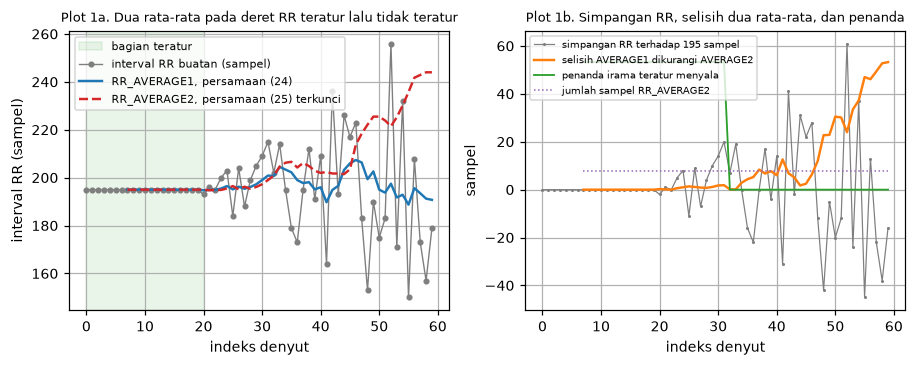

deret buatan: 60 interval, 53 langkah diuji
  penanda irama teratur menyala 25 dari 53 langkah (0.4717)
  selisih AVERAGE1 dan AVERAGE2, median 1.750 sampel, maksimum 53.250 sampel
  jumlah sampel RR_AVERAGE2, minimum 8 dan maksimum 8, jadi selalu delapan
  umur sampel tertua, median 8 denyut dan maksimum 11 denyut
  pada bagian tidak teratur, jumlah interval lolos minimum 2 dan rata-rata 6.151


In [5]:
# Tujuan: menggambar jejak RR_AVERAGE1 dan RR_AVERAGE2 pada deret buatan bersatuan sampel yang berpindah
# dari teratur ke tidak teratur, memakai bacaan terkunci persamaan (25).
# Cell ini menampilkan Plot 1 dengan dua panel dan mencetak jumlah langkah saat penanda menyala,
# beda terbesar kedua rata-rata, jumlah interval yang lolos, dan umur sampel tertua.

rng_buat = np.random.default_rng(23)
n_buat = 60
rr_buat = np.zeros(n_buat, dtype=np.int64)
for k in range(n_buat):
    lebar = 0.0 if k < 20 else 75.0 * (k - 19) / 40.0
    rr_buat[k] = int(round(195.0 + lebar * rng_buat.uniform(-1.0, 1.0)))
h_buat = rata_dua(rr_buat, BENTUK_BAWAAN, CARA_BAWAAN)
idx_buat = np.arange(n_buat)
k_buat = idx_buat[DELAPAN - 1:]
a1_buat = h_buat["avg1"][DELAPAN - 1:]
a2_buat = h_buat["avg2"][DELAPAN - 1:]
beda_buat = np.abs(a1_buat - a2_buat)

fig1, axs1 = plt.subplots(1, 2, figsize=(8.4, 3.4))
axs1[0].axvspan(0.0, 20.0, color="C2", alpha=0.10, label="bagian teratur")
axs1[0].plot(idx_buat, rr_buat, "C7o-", ms=3, lw=0.9, label="interval RR buatan (sampel)")
axs1[0].plot(idx_buat, rr_buat, "C7.", ms=1)
axs1[0].plot(k_buat, a1_buat, "C0-", lw=1.6, label="RR_AVERAGE1, persamaan (24)")
axs1[0].plot(k_buat, a2_buat, "C3--", lw=1.6, label="RR_AVERAGE2, persamaan (25) terkunci")
axs1[0].set_title("Plot 1a. Dua rata-rata pada deret RR teratur lalu tidak teratur", fontsize=8.5)
axs1[0].set_xlabel("indeks denyut")
axs1[0].set_ylabel("interval RR (sampel)")
axs1[0].legend(loc="upper left", fontsize=7.5)
axs1[1].plot(idx_buat, rr_buat - 195.0, "C7.-", ms=2, lw=0.8, label="simpangan RR terhadap 195 sampel")
axs1[1].plot(k_buat, beda_buat, "C1-", lw=1.6, label="selisih AVERAGE1 dikurangi AVERAGE2")
axs1[1].plot(k_buat, np.where(h_buat["reg"][DELAPAN - 1:], 1.0, 0.0) * float(np.max(beda_buat)),
             "C2-", lw=1.2, label="penanda irama teratur menyala")
axs1[1].plot(k_buat, h_buat["penyebut"][DELAPAN - 1:].astype(float), "C4:", lw=1.0,
             label="jumlah sampel RR_AVERAGE2")
axs1[1].set_title("Plot 1b. Simpangan RR, selisih dua rata-rata, dan penanda", fontsize=8.5)
axs1[1].set_xlabel("indeks denyut")
axs1[1].set_ylabel("sampel")
axs1[1].legend(loc="upper left", fontsize=6.5)
fig1.tight_layout()
plt.show()

print("deret buatan: %d interval, %d langkah diuji" % (n_buat, k_buat.size))
print("  penanda irama teratur menyala %d dari %d langkah (%.4f)"
      % (int(h_buat["reg"][DELAPAN - 1:].sum()), k_buat.size, float(np.mean(h_buat["reg"][DELAPAN - 1:]))))
print("  selisih AVERAGE1 dan AVERAGE2, median %.3f sampel, maksimum %.3f sampel"
      % (float(np.median(beda_buat)), float(np.max(beda_buat))))
print("  jumlah sampel RR_AVERAGE2, minimum %d dan maksimum %d, jadi selalu delapan"
      % (int(h_buat["penyebut"][DELAPAN - 1:].min()), int(h_buat["penyebut"][DELAPAN - 1:].max())))
print("  umur sampel tertua, median %d denyut dan maksimum %d denyut"
      % (int(np.median(h_buat["umur"][DELAPAN - 1:])), int(h_buat["umur"][DELAPAN - 1:].max())))
print("  pada bagian tidak teratur, jumlah interval lolos minimum %d dan rata-rata %.3f"
      % (int(h_buat["masuk"][DELAPAN - 1:].min()), float(np.mean(h_buat["masuk"][DELAPAN - 1:]))))
HASIL["penanda menyala pada deret buatan"] = float(np.mean(h_buat["reg"][DELAPAN - 1:]))


### 4.2 Keputusan P4-5, penyemaian ulang rata-rata kedua

Bacaan terkunci P4-1 selalu memegang delapan angka, tetapi antreannya hanya berubah bila ada interval yang
lolos batas. Bila tidak satu pun interval lolos pita batas selama lama, antrean itu tidak berubah sama
sekali, $RR_{AVERAGE2}$ terdampar pada nilai lama, dan penanda irama teratur persamaan (29) mati karena
batas bawah dan batas atas yang dipakai sudah tidak menggambarkan denyut yang sedang berjalan. Sel berikut
mengukur kelemahan itu pada rekaman uji, dan pengukuran itulah yang melahirkan keputusan baru tim.

**P4-5, penyemaian ulang antrean rata-rata kedua, terkunci 19 Oktober 2026.** Bila tidak ada interval RR
yang lolos pita 0,92 sampai 1,16 kali rata-rata kedua selama 8 denyut berturut-turut, antrean delapan
interval diisi ulang memakai median 32 interval RR terakhir, lalu rata-rata kedua dihitung ulang dari
antrean itu. Penyemaian ulang dibatasi paling banyak sekali per 8 denyut.

Pita 0,92 sampai 1,16 itu tidak lain adalah batas bawah dan batas atas persamaan (26) dan (27) dalam
bentuk eksak 23 per 25 dan 29 per 25, jadi pemicu penyemaian ulang memakai pita yang sama dengan syarat
penanda persamaan (29) dan tidak menambah ambang baru sama sekali. Aturan itu berlaku hanya pada bacaan
antrean P4-1, karena hanya bacaan itulah yang memiliki antrean delapan tempat yang dapat diisi ulang.
Kedua panjangnya duduk di satu tempat saja, yaitu di sel konstanta: `PANJANG_TANPA_LOLOS` bernilai 8 denyut
dan `JENDELA_MEDIAN` bernilai 32 interval. Median dihitung sebagai bilangan bulat, sesuai satuan sampel
yang dikunci P4-3, dan penyemaian ulang berlaku mulai langkah berikutnya, mengikuti urutan perhitungan
yang sudah dipakai penugasan persamaan (29). Sel berikut melaporkan angka sebelum dan sesudah aturan itu,
sel pembanding sesudahnya menggambar kedua jalur beserta pita 0,92 dan 1,16, dan sel gerbang di bagian 7
melaporkan akibat aturan itu pada keputusan tingkat jendela.


In [6]:
# Tujuan: melaporkan akibat aturan P4-5, yaitu penyemaian ulang antrean delapan interval rata-rata kedua,
# pada penanda irama teratur, sebaran RR_AVERAGE2, dan lama kejadian terdampar, dengan jalur tanpa aturan
# sebagai pembanding.
# Cell ini mencetak tiga tetapan P4-5, jumlah penyemaian ulang beserta langkah dan jaraknya, penyalaan
# penanda pada kedua jalur untuk seluruh rekaman dan tiap kelas irama, RR_AVERAGE2 minimum dan maksimum,
# umur sampel tertua, dan jeda terdampar terpanjang pada kedua jalur.

h_tanpa_p45 = rata_dua(rr_deret, BENTUK_BAWAAN, CARA_BAWAAN, semai=False)
print("tetapan P4-5 : PANJANG_TANPA_LOLOS %d denyut, JENDELA_MEDIAN %d interval, aturan sebagai bawaan notebook %s"
      % (PANJANG_TANPA_LOLOS, JENDELA_MEDIAN, SEMAI_BAWAAN))
ok_p45 = ~np.isnan(h_kunci["avg1"])
sm_langkah = np.flatnonzero(h_kunci["semai"])
print("penyemaian ulang pada rekaman: %d kali dari %d langkah diuji, jadi %.4f langkah"
      % (int(sm_langkah.size), int(ok_p45.sum()), float(sm_langkah.size / ok_p45.sum())))
print("  langkah penyemaian (indeks langkah, langkah pertama bernilai %d) : %s"
      % (DELAPAN - 1, sm_langkah.tolist()))
if sm_langkah.size > 1:
    jarak_semai = np.diff(sm_langkah)
    print("  jarak antar penyemaian (denyut) : %s" % jarak_semai.tolist())
    print("  jarak terkecil %d denyut, jadi batas paling banyak sekali per %d denyut terpenuhi %s"
          % (int(jarak_semai.min()), PANJANG_TANPA_LOLOS,
             bool(int(jarak_semai.min()) >= PANJANG_TANPA_LOLOS)))
print("  median penyemaian (sampel) : %s" % h_kunci["semai_median"][sm_langkah].tolist())
cocok_median_semai = [median_bulat(rr_deret[max(0, int(k) - JENDELA_MEDIAN + 1): int(k) + 1])
                      == int(h_kunci["semai_median"][k]) for k in sm_langkah]
print("  median tersimpan sama dengan median %d interval RR terakhir : %d dari %d penyemaian (%.4f)"
      % (JENDELA_MEDIAN, int(np.sum(cocok_median_semai)), int(sm_langkah.size),
         float(np.mean(cocok_median_semai)) if sm_langkah.size else 0.0))
print("  jumlah sampel RR_AVERAGE2 tetap %d pada seluruh langkah : %s"
      % (DELAPAN, bool(h_kunci["penyebut"][ok_p45].min() == DELAPAN
                       and h_kunci["penyebut"][ok_p45].max() == DELAPAN)))

baris_p45 = []
for nama_jalur, h in (("tanpa aturan P4-5", h_tanpa_p45), ("dengan aturan P4-5", h_kunci)):
    o = ~np.isnan(h["avg1"])
    a2 = h["avg2"][o]
    masuk_j = h["masuk"][o]
    ubah = np.flatnonzero(np.abs(np.diff(a2)) > 1e-9)
    jeda = np.diff(ubah)
    i_panjang = int(np.argmax(jeda))
    t_jalur = t_puncak[o]
    baris_p45.append({"jalur": nama_jalur, "langkah": int(o.sum()),
                      "penanda menyala": int(h["reg"][o].sum()),
                      "fraksi penanda": float(np.mean(h["reg"][o])),
                      "AVERAGE2 minimum (sampel)": float(a2.min()),
                      "AVERAGE2 maksimum (sampel)": float(a2.max()),
                      "AVERAGE2 minimum (ms)": float(a2.min() * MS_PER_SAMPEL),
                      "AVERAGE2 maksimum (ms)": float(a2.max() * MS_PER_SAMPEL),
                      "umur sampel tertua maksimum": int(h["umur"][o].max()),
                      "AVERAGE2 berubah (langkah)": int(ubah.size),
                      "terdampar terpanjang (denyut)": int(jeda.max()),
                      "terdampar terpanjang (detik)": float(t_jalur[ubah[i_panjang + 1]] - t_jalur[ubah[i_panjang]]),
                      "nilai terdampar terpanjang (ms)": float(a2[ubah[i_panjang]] * MS_PER_SAMPEL),
                      "AVERAGE2 beku saat b nol": float(np.mean(np.abs(np.diff(a2))[masuk_j[:-1] == 0] < 1e-9))})
df_p45 = pd.DataFrame(baris_p45)
print()
print("perbandingan jalur rata-rata kedua pada rekaman 04015, bacaan terkunci persamaan (25):")
print(df_p45.to_string(index=False))
print()
print("penyalaan penanda irama teratur persamaan (29) per kelas irama:")
for nm in ("N", "AFIB"):
    m = ok_p45 & (label_kelas == nm)
    print("  kelas %-4s : %5d langkah, tanpa aturan %5d kali (%.4f), dengan aturan %5d kali (%.4f), selisih %+d penyalaan"
          % (nm, int(m.sum()), int(h_tanpa_p45["reg"][m].sum()), float(np.mean(h_tanpa_p45["reg"][m])),
             int(h_kunci["reg"][m].sum()), float(np.mean(h_kunci["reg"][m])),
             int(h_kunci["reg"][m].sum() - h_tanpa_p45["reg"][m].sum())))
print("  seluruh rekaman: tanpa aturan %d penyalaan (%.4f), dengan aturan %d penyalaan (%.4f), selisih %+d penyalaan"
      % (int(h_tanpa_p45["reg"][ok_p45].sum()), float(np.mean(h_tanpa_p45["reg"][ok_p45])),
         int(h_kunci["reg"][ok_p45].sum()), float(np.mean(h_kunci["reg"][ok_p45])),
         int(h_kunci["reg"][ok_p45].sum() - h_tanpa_p45["reg"][ok_p45].sum())))
print()
print("kejadian terdampar, yaitu jeda saat RR_AVERAGE2 tidak berubah sama sekali:")
for nama_jalur, h in (("tanpa aturan P4-5", h_tanpa_p45), ("dengan aturan P4-5", h_kunci)):
    o = ~np.isnan(h["avg1"])
    a2 = h["avg2"][o]
    t_jalur = t_puncak[o]
    ubah = np.flatnonzero(np.abs(np.diff(a2)) > 1e-9)
    jeda = np.diff(ubah)
    i_panjang = int(np.argmax(jeda))
    print("  %s: %d jeda, jeda median %d denyut, jeda maksimum %d denyut yaitu %.1f detik"
          % (nama_jalur, int(jeda.size), int(np.median(jeda)), int(jeda.max()),
             float(t_jalur[ubah[i_panjang + 1]] - t_jalur[ubah[i_panjang]])))
    print("    jeda terpanjang dari %.1f sampai %.1f detik, RR_AVERAGE2 tetap %.1f sampel yaitu %.1f ms"
          % (float(t_jalur[ubah[i_panjang]]), float(t_jalur[ubah[i_panjang + 1]]),
             float(a2[ubah[i_panjang]]), float(a2[ubah[i_panjang]] * MS_PER_SAMPEL)))
    print("    jeda di atas %d denyut : %d dari %d jeda (%.4f)"
          % (DELAPAN, int((jeda > DELAPAN).sum()), int(jeda.size), float(np.mean(jeda > DELAPAN))))
HASIL["penanda dengan aturan P4-5"] = int(h_kunci["reg"][ok_p45].sum())
HASIL["penanda tanpa aturan P4-5"] = int(h_tanpa_p45["reg"][ok_p45].sum())
HASIL["penyemaian ulang pada rekaman"] = int(sm_langkah.size)
HASIL["penanda dengan aturan P4-5 pada N"] = float(np.mean(h_kunci["reg"][ok_p45 & (label_kelas == "N")]))
HASIL["penanda dengan aturan P4-5 pada AFIB"] = float(np.mean(h_kunci["reg"][ok_p45 & (label_kelas == "AFIB")]))
HASIL["terdampar terpanjang tanpa aturan (denyut)"] = int(df_p45.loc[0, "terdampar terpanjang (denyut)"])
HASIL["terdampar terpanjang dengan aturan (denyut)"] = int(df_p45.loc[1, "terdampar terpanjang (denyut)"])
HASIL["AVERAGE2 minimum dengan aturan (ms)"] = float(df_p45.loc[1, "AVERAGE2 minimum (ms)"])
HASIL["AVERAGE2 maksimum dengan aturan (ms)"] = float(df_p45.loc[1, "AVERAGE2 maksimum (ms)"])


tetapan P4-5 : PANJANG_TANPA_LOLOS 8 denyut, JENDELA_MEDIAN 32 interval, aturan sebagai bawaan notebook True
penyemaian ulang pada rekaman: 12 kali dari 2515 langkah diuji, jadi 0.0048 langkah
  langkah penyemaian (indeks langkah, langkah pertama bernilai 7) : [14, 143, 266, 290, 298, 428, 580, 623, 737, 876, 960, 1022]
  jarak antar penyemaian (denyut) : [129, 123, 24, 8, 130, 152, 43, 114, 139, 84, 62]
  jarak terkecil 8 denyut, jadi batas paling banyak sekali per 8 denyut terpenuhi True
  median penyemaian (sampel) : [206, 146, 138, 128, 197, 155, 143, 121, 144, 129, 118, 193]
  median tersimpan sama dengan median 32 interval RR terakhir : 12 dari 12 penyemaian (1.0000)
  jumlah sampel RR_AVERAGE2 tetap 8 pada seluruh langkah : True

perbandingan jalur rata-rata kedua pada rekaman 04015, bacaan terkunci persamaan (25):
             jalur  langkah  penanda menyala  fraksi penanda  AVERAGE2 minimum (sampel)  AVERAGE2 maksimum (sampel)  AVERAGE2 minimum (ms)  AVERAGE2 maksimum (ms)  um

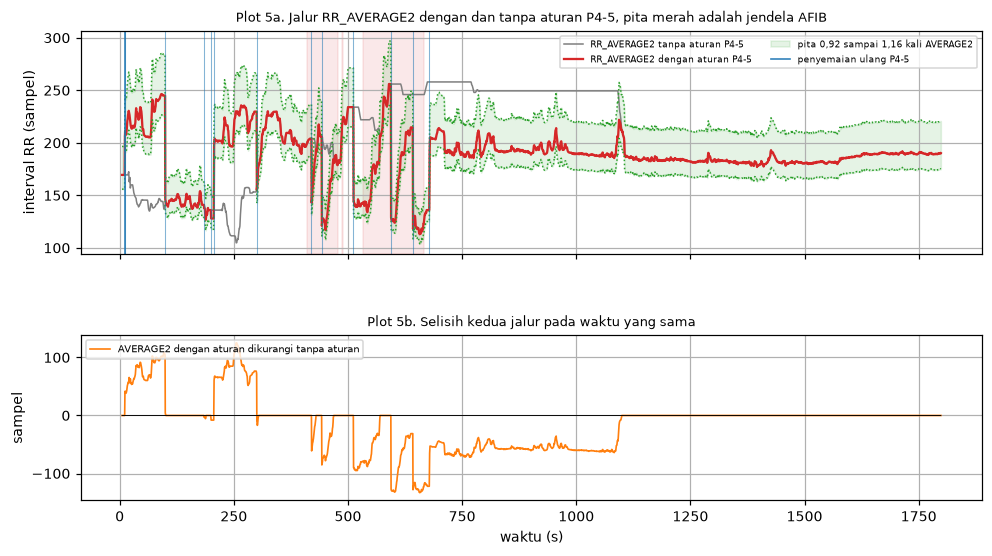

gambar pembanding memuat 2515 langkah dan 12 penanda penyemaian ulang
  waktu penyemaian ulang (detik) : [10.9, 99.4, 184.4, 199.4, 206.0, 300.0, 420.0, 442.3, 511.7, 593.9, 641.9, 678.1]
  selisih kedua jalur, median 0.000 sampel, maksimum 133.000 sampel yaitu 532.0 ms
  lebar pita 0,92 sampai 1,16 kali AVERAGE2 pada jalur dengan aturan, median 45.300 sampel, maksimum 61.440 sampel
  jumlah langkah yang kedua jalur berbeda lebih dari 1 sampel : 1145 dari 2515 langkah (0.4553)


In [7]:
# Tujuan: membandingkan jalur RR_AVERAGE2 beserta batas 92 dan 116 persen dengan dan tanpa aturan P4-5,
# dan menandai langkah penyemaian ulang pada jalur yang memakai aturan itu.
# Cell ini menampilkan Plot 5 dengan dua panel dan mencetak jumlah penyemaian ulang, waktunya dalam detik,
# selisih terbesar kedua jalur, dan lebar pita batas pada jalur yang memakai aturan.

ok_v = ~np.isnan(h_kunci["avg2"])
ok_w = ~np.isnan(h_tanpa_p45["avg2"])
t_v = t_puncak[ok_v]
a2_v = h_kunci["avg2"][ok_v]
a2_w = h_tanpa_p45["avg2"][ok_w]
bawah_v = K_TAMPIL["bawah"] * a2_v
atas_v = K_TAMPIL["atas"] * a2_v
beda_vw = a2_v - a2_w
sm_gambar = np.flatnonzero(h_kunci["semai"][ok_v])
t_semai = t_v[sm_gambar]

fig5, axs5 = plt.subplots(2, 1, figsize=(9.2, 5.4), sharex=True,
                          gridspec_kw={"height_ratios": [1.15, 0.85]})
for s0, s1, nama in JENDELA_KELAS:
    if nama == "AFIB":
        axs5[0].axvspan(s0 / FS, s1 / FS, color="C3", alpha=0.10)
axs5[0].plot(t_v, a2_w, "C7-", lw=1.0, label="RR_AVERAGE2 tanpa aturan P4-5")
axs5[0].plot(t_v, a2_v, "C3-", lw=1.5, label="RR_AVERAGE2 dengan aturan P4-5")
axs5[0].fill_between(t_v, bawah_v, atas_v, color="C2", alpha=0.12,
                     label="pita 0,92 sampai 1,16 kali AVERAGE2")
axs5[0].plot(t_v, bawah_v, "C2:", lw=1.0)
axs5[0].plot(t_v, atas_v, "C2:", lw=1.0)
for t_one in t_semai:
    axs5[0].axvline(float(t_one), color="C0", lw=0.7, alpha=0.55)
if t_semai.size:
    axs5[0].axvline(float(t_semai[0]), color="C0", lw=1.1, alpha=0.9, label="penyemaian ulang P4-5")
axs5[0].set_title("Plot 5a. Jalur RR_AVERAGE2 dengan dan tanpa aturan P4-5, pita merah adalah jendela AFIB", fontsize=8.5)
axs5[0].set_ylabel("interval RR (sampel)")
axs5[0].legend(loc="upper right", fontsize=6.2, ncol=2)
axs5[1].plot(t_v, beda_vw, "C1-", lw=1.1, label="AVERAGE2 dengan aturan dikurangi tanpa aturan")
axs5[1].plot(t_v, np.zeros_like(t_v), "k-", lw=0.6)
axs5[1].set_title("Plot 5b. Selisih kedua jalur pada waktu yang sama", fontsize=8.5)
axs5[1].set_xlabel("waktu (s)")
axs5[1].set_ylabel("sampel")
axs5[1].legend(loc="upper left", fontsize=6.5)
fig5.subplots_adjust(top=0.90, bottom=0.11, left=0.09, right=0.98, hspace=0.42)
plt.show()

print("gambar pembanding memuat %d langkah dan %d penanda penyemaian ulang" % (a2_v.size, t_semai.size))
if t_semai.size:
    print("  waktu penyemaian ulang (detik) : %s" % np.round(t_semai, 1).tolist())
print("  selisih kedua jalur, median %.3f sampel, maksimum %.3f sampel yaitu %.1f ms"
      % (float(np.median(np.abs(beda_vw))), float(np.max(np.abs(beda_vw))),
         float(np.max(np.abs(beda_vw)) * MS_PER_SAMPEL)))
print("  lebar pita 0,92 sampai 1,16 kali AVERAGE2 pada jalur dengan aturan, median %.3f sampel, maksimum %.3f sampel"
      % (float(np.median(atas_v - bawah_v)), float(np.max(atas_v - bawah_v))))
print("  jumlah langkah yang kedua jalur berbeda lebih dari 1 sampel : %d dari %d langkah (%.4f)"
      % (int(np.sum(np.abs(beda_vw) > 1.0)), int(beda_vw.size), float(np.mean(np.abs(beda_vw) > 1.0))))
HASIL["selisih AVERAGE2 maksimum dengan aturan (sampel)"] = float(np.max(np.abs(beda_vw)))
HASIL["langkah kedua jalur berbeda dengan aturan"] = float(np.mean(np.abs(beda_vw) > 1.0))


## 5. Hitungan tangan satu deret interval RR

Contoh ini memakai enam belas interval RR bersatuan sampel, dengan dua interval menyimpang: satu panjang
260 sampel yaitu 1040 ms dan satu pendek 140 sampel yaitu 560 ms. Kolom jumlah delapan interval dihitung
dua kali, sekali sebagai penjumlahan langsung delapan suku dan sekali sebagai penjumlah bergeser
$S_8[k] = S_8[k-1] + RR_k - RR_{k-8}$. Batas bawah dan batas atas pada tabel dihitung dari bentuk eksak
23 per 25 dan 29 per 25 lewat perkalian silang, dan $RR_{AVERAGE2}$ memakai bacaan terkunci delapan
interval lolos terakhir, jadi kolom jumlah sampelnya selalu delapan.

| $k$ | $RR_k$ | $S_8[k]$ bergeser | $S_8[k] \gg 3$ | $RR_{AVERAGE1}$ | selisih geser | $b$ | $RR_{AVERAGE2}$ | penanda |
|---|---|---|---|---|---|---|---|---|


In [8]:
# Tujuan: menghitung satu deret interval RR bersatuan sampel dengan tangan, dua cara penjumlahan, dan
# aturan (24) sampai (29) dengan bacaan terkunci serta bentuk batas eksak 23 per 25.
# Cell ini mencetak tabel satu baris per langkah beserta jumlah langsung, jumlah bergeser, dua rata-rata,
# batas bawah dan batas atas, jumlah interval yang lolos, dan keadaan penanda irama teratur, lalu
# pembanding singkat bacaan yang ditolak.

rr_contoh = np.array([200, 201, 199, 200, 203, 197, 200, 200,
                      260, 140, 200, 200, 300, 100, 200, 200], dtype=np.int64)
h_contoh = rata_dua(rr_contoh, BENTUK_BAWAAN, CARA_BAWAAN)
h_contoh_ditolak = rata_dua(rr_contoh, BENTUK_BAWAAN, CARA_DITOLAK)
S_geser = None
baris_contoh = []
galat_geser_contoh = []
identitas_geser = True
for k in range(DELAPAN - 1, rr_contoh.size):
    u = rr_contoh[k - DELAPAN + 1: k + 1]
    S_langsung_k = int(u.sum())
    S_geser = S_langsung_k if S_geser is None else S_geser + int(rr_contoh[k]) - int(rr_contoh[k - DELAPAN])
    identitas_geser = identitas_geser and (S_geser == S_langsung_k)
    B_k = int(h_contoh["pembilang"][k])
    m_k = int(h_contoh["penyebut"][k])
    low = float(Fraction(23 * B_k, 25 * m_k))
    high = float(Fraction(29 * B_k, 25 * m_k))
    galat_geser_contoh.append(h_contoh["avg1"][k] - float(S_geser >> 3))
    baris_contoh.append({"k": int(k), "RR_k (sampel)": int(rr_contoh[k]), "S8 langsung": S_langsung_k,
                         "S8 bergeser": int(S_geser), "S8 geser 3": int(S_geser >> 3),
                         "AVERAGE1 (sampel)": float(h_contoh["avg1"][k]),
                         "selisih geser": float(h_contoh["avg1"][k] - float(S_geser >> 3)),
                         "batas bawah": low, "batas atas": high,
                         "b": int(h_contoh["masuk"][k]), "sampel AVERAGE2": m_k,
                         "AVERAGE2 (sampel)": float(h_contoh["avg2"][k]),
                         "penanda": bool(h_contoh["reg"][k])})
df_contoh = pd.DataFrame(baris_contoh)
print("tabel hitung tangan, %d langkah, deret %d interval bersatuan sampel" % (df_contoh.shape[0], rr_contoh.size))
print(df_contoh.to_string(index=False))
print()
print("jumlah delapan suku langsung sama dengan penjumlah bergeser pada seluruh langkah :", identitas_geser)
print("galat geser kanan tiga bit, maksimum %.3f sampel yaitu %.1f ms, rata-rata %.4f sampel"
      % (float(np.max(np.abs(galat_geser_contoh))), float(np.max(np.abs(galat_geser_contoh)) * MS_PER_SAMPEL),
         float(np.mean(np.abs(galat_geser_contoh)))))
print("langkah yang penandanya menyala :", int(h_contoh["reg"].sum()), "dari", df_contoh.shape[0])
print("jumlah sampel RR_AVERAGE2 pada bacaan terkunci : minimum %d, maksimum %d"
      % (int(h_contoh["penyebut"][DELAPAN - 1:].min()), int(h_contoh["penyebut"][DELAPAN - 1:].max())))
print("langkah yang AVERAGE1 dan AVERAGE2 berbeda lebih dari 0,5 ms : %d"
      % int(np.sum(np.abs(df_contoh["AVERAGE1 (sampel)"] - df_contoh["AVERAGE2 (sampel)"]) * MS_PER_SAMPEL > 0.5)))
print()
print("pembanding singkat bacaan yang ditolak, interval lolos di antara delapan terakhir :")
print("  penanda menyala %d dari %d langkah, jumlah sampel RR_AVERAGE2 minimum %d dan maksimum %d"
      % (int(h_contoh_ditolak["reg"].sum()), df_contoh.shape[0],
         int(h_contoh_ditolak["penyebut"][DELAPAN - 1:].min()), int(h_contoh_ditolak["penyebut"][DELAPAN - 1:].max())))
print("  langkah yang nilai AVERAGE2 pada bacaan terkunci berbeda dari bacaan ditolak : %d dari %d"
      % (int(np.sum(np.abs(h_contoh["avg2"][DELAPAN - 1:] - h_contoh_ditolak["avg2"][DELAPAN - 1:]) * MS_PER_SAMPEL > 0.5)),
         df_contoh.shape[0]))
HASIL["galat geser contoh"] = float(np.max(np.abs(galat_geser_contoh)))
HASIL["langkah penanda contoh"] = int(h_contoh["reg"].sum())


tabel hitung tangan, 9 langkah, deret 16 interval bersatuan sampel
 k  RR_k (sampel)  S8 langsung  S8 bergeser  S8 geser 3  AVERAGE1 (sampel)  selisih geser  batas bawah  batas atas  b  sampel AVERAGE2  AVERAGE2 (sampel)  penanda
 7            200         1600         1600         200            200.000          0.000      184.000     232.000  8                8            200.000     True
 8            260         1660         1660         207            207.500          0.500      184.000     232.000  7                8            200.000    False
 9            140         1599         1599         199            199.875          0.875      184.000     232.000  6                8            200.000    False
10            200         1600         1600         200            200.000          0.000      183.885     231.855  6                8            199.875    False
11            200         1600         1600         200            200.000          0.000      184.000     232.000  6 

## 6. Persamaan (26) sampai (28), tiga batas sebagai pengali tetap

Ketiga batas ditulis makalah sebagai persentase dari $RR_{AVERAGE2}$, dan dalam aritmetika pecahan
ketiganya adalah bilangan rasional yang sederhana:

$$ 0{,}92 = \frac{23}{25}, \qquad 1{,}16 = \frac{29}{25}, \qquad 1{,}66 = \frac{83}{50} $$

Tidak satu pun dari ketiganya yang merupakan pangkat dua, jadi tidak satu pun dapat dipetakan menjadi
geser bit tunggal. Untuk membandingkan $RR$ dengan batas, bentuk yang dipakai perangkat keras adalah
perkalian silang, dan keputusan P4-2 mengunci bentuk **eksak** 23 per 25 sebagai bentuk bawaan:

$$ RR \geq \frac{23}{25} RR_{AVERAGE2} \iff 25 \, RR \geq 23 \, RR_{AVERAGE2} $$

Bentuk silang itu tidak memerlukan pembagi dan tidak memerlukan pengali konstanta, karena 25 dan 23
dapat ditulis sebagai jumlah pangkat dua bertanda: 25 sama dengan 16 ditambah 8 ditambah 1, dan 23 sama
dengan 16 ditambah 8 dikurangi 1. Biayanya diukur di sel berikut, dan hasilnya 4 geseran dan
3 penjumlahan, ditambah 1 pengurangan.

Dua tingkatan lain tetap dicatat supaya batasnya jelas.

1. **Cadangan**, aproksimasi berpenyebut 64: batas bawah 59 per 64 dengan galat relatif 0,2038 persen,
   batas atas 74 per 64, dan batas missed 106 per 64. Bentuk ini boleh muncul sebagai cadangan bila
   jaringan geser dan tambah lebih diutamakan daripada letak batas.
2. **Dilarang**, aproksimasi berpenyebut 32: batas bawah 30 per 32, batas atas 37 per 32, dan batas
   missed 53 per 32. Bentuk 30 per 32 punya galat relatif 1,9022 persen terhadap 23 per 25, yaitu
   pergeseran batas bawah sebesar 14 ms atau 3,5 sampel pada $RR_{AVERAGE2}$ 200 sampel, dan pada
   lingkar tertutup bentuk itu terukur meruntuhkan penanda irama teratur dari 898 penyalaan menjadi
   9 penyalaan. Karena itu 30 per 32 dan seluruh keluarga penyebut 32 dicatat sebagai DILARANG, bukan
   sebagai kandidat.

Selain letak batas, yang harus diukur adalah biaya keputusannya. Karena rekaman AFDB `04015` hanya
membawa anotasi ritme dan tidak membawa anotasi denyut, ukuran sensitivitas dan spesifisitas di sini
didefinisikan pada tingkat keputusan, yaitu dibandingkan dengan keputusan yang dihitung memakai bentuk
eksak sebagai acuan. Definisi itu diukur dua kali: sekali dengan $RR_{AVERAGE2}$ dibekukan supaya
pergeseran batas terukur sendirian, dan sekali dengan lingkar tertutup penuh supaya biaya sesungguhnya
pada aturan yang berjalan terlihat.


In [9]:
# Tujuan: mengukur galat dan biaya tiga bentuk batas, yaitu bentuk eksak 23 per 25 dan 29 per 25 yang
# dikunci, aproksimasi cadangan berpenyebut 64, dan aproksimasi berpenyebut 32 yang dilarang.
# Cell ini mencetak galat relatif tiap bentuk, pergeseran letak batas pada empat nilai AVERAGE2 bersatuan
# sampel, biaya geser dan penjumlahan tiap bentuk silang, dan pemeriksaan ketepatan ungkapan gesernya.

BENTUK_UJI = [("eksak dikunci", PECAH_TEPAT), ("cadangan penyebut 64", PECAH_CADANGAN),
              ("dilarang penyebut 32", PECAH_DILARANG)]
AVG2_UJI = [125, 150, 200, 250]         # sampel, sama dengan 500, 600, 800, dan 1000 ms
baris_batas = []
for nama_kelompok, pecah in BENTUK_UJI:
    for nama_batas in ("bawah", "atas", "missed"):
        p, q = pecah[nama_batas]
        pe, qe = PECAH_TEPAT[nama_batas]
        for av in AVG2_UJI:
            eksak = float(Fraction(pe * av, qe))
            bentuk = float(Fraction(p * av, q))
            baris_batas.append({"kelompok": nama_kelompok, "batas": nama_batas, "AVERAGE2 (sampel)": av,
                                "eksak (sampel)": eksak, "bentuk ini (sampel)": bentuk,
                                "geser (sampel)": bentuk - eksak,
                                "geser (ms)": (bentuk - eksak) * MS_PER_SAMPEL})
df_batas = pd.DataFrame(baris_batas)
print("pergeseran letak batas oleh aproksimasi, acuan bentuk eksak 23 per 25, 29 per 25, dan 83 per 50")
print(df_batas[df_batas["batas"] == "bawah"].to_string(index=False))
print()
print("galat relatif tiap bentuk terhadap bentuk eksak pada batas yang sama:")
for nama_kelompok, pecah in BENTUK_UJI:
    for nama_batas in ("bawah", "atas", "missed"):
        p, q = pecah[nama_batas]
        pe, qe = PECAH_TEPAT[nama_batas]
        print("  %-22s batas %-6s: %2d/%2d, galat relatif %+.6f yaitu %+.4f persen"
              % (nama_kelompok, nama_batas, p, q, float(Fraction(p, q) / Fraction(pe, qe)) - 1.0,
                 100.0 * (float(Fraction(p, q) / Fraction(pe, qe)) - 1.0)))
print()
RUMUS_SILANG = {
    "bawah eksak 23/25": "(((rr << 4) + (rr << 3) + rr) >= ((av << 4) + (av << 3) - av))",
    "atas eksak 29/25": "(((rr << 4) + (rr << 3) + rr) <= ((av << 4) + (av << 3) + (av << 2) + av))",
    "missed eksak 83/50": "(((rr << 5) + (rr << 4) + (rr << 1)) > ((av << 6) + (av << 4) + (av << 1) + av))",
    "bawah cadangan 59/64": "((rr << 6) >= ((av << 6) - (av << 2) - av))",
    "atas cadangan 74/64": "((rr << 6) <= ((av << 6) + (av << 3) + (av << 1)))",
    "missed cadangan 106/64": "((rr << 6) > ((av << 6) + (av << 5) + (av << 3) + (av << 1)))",
    "bawah dilarang 30/32": "((rr << 5) >= ((av << 5) - (av << 1)))",
    "atas dilarang 37/32": "((rr << 5) <= ((av << 5) + (av << 2) + av))",
    "missed dilarang 53/32": "((rr << 5) > ((av << 5) + (av << 4) + (av << 2) + av))"}
print("bentuk silang tiap batas dan biayanya, dihitung dari ungkapannya sendiri, rr dan av bilangan bulat:")
baris_rumus = []
for nama, rumus in RUMUS_SILANG.items():
    biaya = biaya_bentuk(rumus)
    baris_rumus.append({"bentuk": nama, "rumus silang": rumus, "geser": biaya["geser"],
                        "tambah": biaya["tambah"], "kurang": biaya["kurang"],
                        "jumlah operasi": biaya["geser"] + biaya["tambah"] + biaya["kurang"]})
df_rumus = pd.DataFrame(baris_rumus)
print(df_rumus[["bentuk", "geser", "tambah", "kurang", "jumlah operasi"]].to_string(index=False))
print()
for nama in ("bawah eksak 23/25", "atas eksak 29/25", "missed eksak 83/50"):
    b = df_rumus[df_rumus["bentuk"] == nama].iloc[0]
    print("  %-20s : geser %d, penjumlahan %d, pengurangan %d, pengali konstanta 0"
          % (nama, int(b["geser"]), int(b["tambah"]), int(b["kurang"])))
bb = df_rumus[df_rumus["bentuk"] == "bawah eksak 23/25"].iloc[0]
print("  jadi batas bawah bentuk eksak 23 per 25 terukur %d geseran dan %d penjumlahan, yaitu %d operasi"
      % (int(bb["geser"]), int(bb["tambah"]), int(bb["jumlah operasi"])))
print("  keluarga penyebut 32 dilarang: galat relatif batas bawah %+.4f persen dan pergeseran %+.1f sampel pada AVERAGE2 200 sampel"
      % (100.0 * (float(Fraction(*PECAH_DILARANG["bawah"])) / float(Fraction(*PECAH_TEPAT["bawah"])) - 1.0),
         (float(Fraction(*PECAH_DILARANG["bawah"])) - float(Fraction(*PECAH_TEPAT["bawah"]))) * 200.0))
print()
rr_ref = np.arange(60, 700, dtype=np.int64)
av_ref = np.arange(60, 700, dtype=np.int64)
rr_kolom = rr_ref[:, None]
av_baris = av_ref[None, :]
uji_tepat = {
    "bawah eksak 23/25": (((rr_kolom << 4) + (rr_kolom << 3) + rr_kolom)
                          >= ((av_baris << 4) + (av_baris << 3) - av_baris)),
    "atas eksak 29/25": (((rr_kolom << 4) + (rr_kolom << 3) + rr_kolom)
                         <= ((av_baris << 4) + (av_baris << 3) + (av_baris << 2) + av_baris)),
    "missed eksak 83/50": (((rr_kolom << 5) + (rr_kolom << 4) + (rr_kolom << 1))
                           > ((av_baris << 6) + (av_baris << 4) + (av_baris << 1) + av_baris))}
acuan_tepat = {"bawah eksak 23/25": 25 * rr_kolom >= 23 * av_baris,
               "atas eksak 29/25": 25 * rr_kolom <= 29 * av_baris,
               "missed eksak 83/50": 50 * rr_kolom > 83 * av_baris}
print("pemeriksaan bentuk silang terhadap perkalian langsung, matriks %s kali %s pasangan bilangan bulat:"
      % (uji_tepat["bawah eksak 23/25"].shape[0], uji_tepat["bawah eksak 23/25"].shape[1]))
for nama in uji_tepat:
    print("  %-20s bentuk geser sama dengan perkalian langsung : %s"
          % (nama, bool(np.array_equal(uji_tepat[nama], acuan_tepat[nama]))))
uji_kasar = {
    "bawah cadangan 59/64": ((av_ref << 6) - (av_ref << 2) - av_ref) >> 6,
    "bawah dilarang 30/32": ((av_ref << 5) - (av_ref << 1)) >> 5,
    "atas dilarang 37/32": ((av_ref << 5) + (av_ref << 2) + av_ref) >> 5}
acuan_kasar = {"bawah cadangan 59/64": (59 * av_ref) // 64, "bawah dilarang 30/32": (30 * av_ref) // 32,
               "atas dilarang 37/32": (37 * av_ref) // 32}
for nama in uji_kasar:
    print("  %-20s bentuk geser sama dengan pembagian bulat : %s"
          % (nama, bool(np.array_equal(uji_kasar[nama], acuan_kasar[nama]))))
HASIL["galat relatif 30/32"] = float(Fraction(*PECAH_DILARANG["bawah"]) / Fraction(*PECAH_TEPAT["bawah"])) - 1.0
HASIL["galat relatif 59/64"] = float(Fraction(*PECAH_CADANGAN["bawah"]) / Fraction(*PECAH_TEPAT["bawah"])) - 1.0
HASIL["biaya geser bawah eksak"] = int(bb["geser"])
HASIL["biaya tambah bawah eksak"] = int(bb["tambah"])
HASIL["geser batas bawah dilarang pada 200 sampel"] = float((float(Fraction(*PECAH_DILARANG["bawah"]))
                                                             - float(Fraction(*PECAH_TEPAT["bawah"]))) * 200.0)
HASIL["geser batas bawah cadangan pada 200 sampel"] = float((float(Fraction(*PECAH_CADANGAN["bawah"]))
                                                             - float(Fraction(*PECAH_TEPAT["bawah"]))) * 200.0)


pergeseran letak batas oleh aproksimasi, acuan bentuk eksak 23 per 25, 29 per 25, dan 83 per 50
            kelompok batas  AVERAGE2 (sampel)  eksak (sampel)  bentuk ini (sampel)  geser (sampel)  geser (ms)
       eksak dikunci bawah                125           115.0           115.000000        0.000000      0.0000
       eksak dikunci bawah                150           138.0           138.000000        0.000000      0.0000
       eksak dikunci bawah                200           184.0           184.000000        0.000000      0.0000
       eksak dikunci bawah                250           230.0           230.000000        0.000000      0.0000
cadangan penyebut 64 bawah                125           115.0           115.234375        0.234375      0.9375
cadangan penyebut 64 bawah                150           138.0           138.281250        0.281250      1.1250
cadangan penyebut 64 bawah                200           184.0           184.375000        0.375000      1.5000
cadangan penyebu

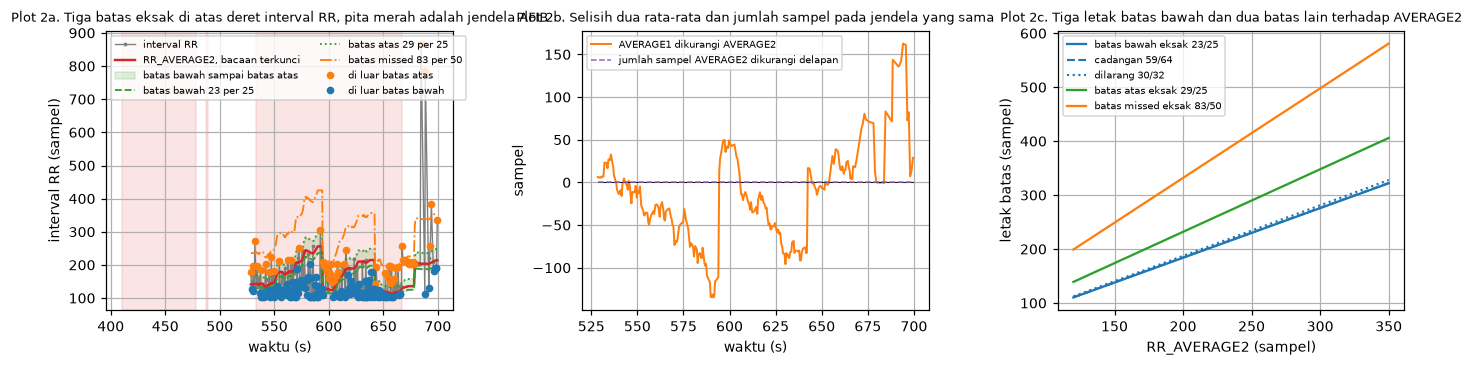

jendela yang digambar: 528.5 sampai 699.5 detik, 279 interval
  interval di dalam jendela beranotasi AFIB : 238
  di luar batas bawah 23 per 25     : 153
  di luar batas atas 29 per 25      : 60
  melewati batas missed 83 per 50   : 8
  AVERAGE2 pada jendela, minimum 113.0 sampel maksimum 256.0 sampel, jumlah sampelnya selalu 8
pada seluruh rekaman, 2515 langkah diuji: di luar batas bawah 648, di luar batas atas 198, melewati missed 43


In [10]:
# Tujuan: menggambar tiga batas persamaan (26) sampai (28) bentuk eksak di atas deret interval RR
# rekaman bersatuan sampel, dan membandingkan letak batas bentuk eksak dengan bentuk cadangan serta
# bentuk yang dilarang.
# Cell ini menampilkan Plot 2 dengan tiga panel dan mencetak jumlah interval di luar batas bawah, di luar
# batas atas, dan yang melewati batas missed, pada jendela gambar dan pada seluruh rekaman.

T0 = 528.0
T1 = 700.0
sel_plot = (t_puncak >= T0) & (t_puncak < T1)
t_plot = t_puncak[sel_plot]
rr_plot = rr_deret[sel_plot]
a2_plot = h_kunci["avg2"][sel_plot]
a1_plot = h_kunci["avg1"][sel_plot]
B_plot = h_kunci["pembilang"][sel_plot]
m_plot = h_kunci["penyebut"][sel_plot]
kelas_plot = label_kelas[sel_plot]
sel_ada = ~np.isnan(a2_plot)
di_bawah = ~lolos_bawah(rr_plot, PECAH_TEPAT["bawah"], B_plot, m_plot) & sel_ada
di_atas = ~lolos_atas(rr_plot, PECAH_TEPAT["atas"], B_plot, m_plot) & sel_ada
lewat = lewat_missed(rr_plot, PECAH_TEPAT["missed"], B_plot, m_plot) & sel_ada
bawah_plot = K_TAMPIL["bawah"] * a2_plot
atas_plot = K_TAMPIL["atas"] * a2_plot
missed_plot = K_TAMPIL["missed"] * a2_plot

fig2, axs2 = plt.subplots(1, 3, figsize=(12.6, 3.4))
axs2[0].plot(t_plot, rr_plot, "C7.-", ms=3, lw=0.9, label="interval RR")
axs2[0].plot(t_plot, a2_plot, "C3-", lw=1.6, label="RR_AVERAGE2, bacaan terkunci")
axs2[0].fill_between(t_plot, bawah_plot, atas_plot, color="C2", alpha=0.15,
                     label="batas bawah sampai batas atas")
axs2[0].plot(t_plot, bawah_plot, "C2--", lw=1.2, label="batas bawah 23 per 25")
axs2[0].plot(t_plot, atas_plot, "C2:", lw=1.2, label="batas atas 29 per 25")
axs2[0].plot(t_plot, missed_plot, "C1-.", lw=1.2, label="batas missed 83 per 50")
axs2[0].plot(t_plot[di_atas], rr_plot[di_atas], "C1o", ms=4, label="di luar batas atas")
axs2[0].plot(t_plot[di_bawah], rr_plot[di_bawah], "C0o", ms=4, label="di luar batas bawah")
for s0, s1, nama in JENDELA_KELAS:
    if nama == "AFIB":
        axs2[0].axvspan(s0 / FS, s1 / FS, color="C3", alpha=0.12)
axs2[0].set_title("Plot 2a. Tiga batas eksak di atas deret interval RR, pita merah adalah jendela AFIB", fontsize=8.5)
axs2[0].set_xlabel("waktu (s)")
axs2[0].set_ylabel("interval RR (sampel)")
axs2[0].legend(loc="upper left", fontsize=6.5, ncol=2)
axs2[1].plot(t_plot, a1_plot - a2_plot, "C1-", lw=1.3, label="AVERAGE1 dikurangi AVERAGE2")
axs2[1].plot(t_plot, np.zeros_like(t_plot), "k-", lw=0.6)
axs2[1].plot(t_plot, h_kunci["penyebut"][sel_plot].astype(float) - DELAPAN, "C4--", lw=1.0,
             label="jumlah sampel AVERAGE2 dikurangi delapan")
axs2[1].set_title("Plot 2b. Selisih dua rata-rata dan jumlah sampel pada jendela yang sama", fontsize=8.5)
axs2[1].set_xlabel("waktu (s)")
axs2[1].set_ylabel("sampel")
axs2[1].legend(loc="upper left", fontsize=6.5)
av_garis = np.linspace(120.0, 350.0, 400)
axs2[2].plot(av_garis, K_TAMPIL["bawah"] * av_garis, "C0-", lw=1.5, label="batas bawah eksak 23/25")
axs2[2].plot(av_garis, float(Fraction(*PECAH_CADANGAN["bawah"])) * av_garis, "C0--", lw=1.4,
             label="cadangan 59/64")
axs2[2].plot(av_garis, float(Fraction(*PECAH_DILARANG["bawah"])) * av_garis, "C0:", lw=1.4,
             label="dilarang 30/32")
axs2[2].plot(av_garis, K_TAMPIL["atas"] * av_garis, "C2-", lw=1.5, label="batas atas eksak 29/25")
axs2[2].plot(av_garis, K_TAMPIL["missed"] * av_garis, "C1-", lw=1.5, label="batas missed eksak 83/50")
axs2[2].set_title("Plot 2c. Tiga letak batas bawah dan dua batas lain terhadap AVERAGE2", fontsize=8.5)
axs2[2].set_xlabel("RR_AVERAGE2 (sampel)")
axs2[2].set_ylabel("letak batas (sampel)")
axs2[2].legend(loc="upper left", fontsize=6.5)
fig2.tight_layout()
plt.show()

print("jendela yang digambar: %.1f sampai %.1f detik, %d interval" % (t_plot[0], t_plot[-1], rr_plot.size))
print("  interval di dalam jendela beranotasi AFIB :", int(np.sum(kelas_plot == "AFIB")))
print("  di luar batas bawah 23 per 25     :", int(di_bawah.sum()))
print("  di luar batas atas 29 per 25      :", int(di_atas.sum()))
print("  melewati batas missed 83 per 50   :", int(lewat.sum()))
print("  AVERAGE2 pada jendela, minimum %.1f sampel maksimum %.1f sampel, jumlah sampelnya selalu %d"
      % (np.nanmin(a2_plot), np.nanmax(a2_plot), int(m_plot[sel_ada].min()) if sel_ada.any() else 0))
ok_nyata = ~np.isnan(h_kunci["avg2"])
di_bawah_nyata = ~lolos_bawah(rr_deret, PECAH_TEPAT["bawah"], h_kunci["pembilang"], h_kunci["penyebut"]) & ok_nyata
di_atas_nyata = ~lolos_atas(rr_deret, PECAH_TEPAT["atas"], h_kunci["pembilang"], h_kunci["penyebut"]) & ok_nyata
print("pada seluruh rekaman, %d langkah diuji: di luar batas bawah %d, di luar batas atas %d, melewati missed %d"
      % (int(ok_nyata.sum()), int(di_bawah_nyata.sum()), int(di_atas_nyata.sum()),
         int(np.sum(h_kunci["lewat"] & ok_nyata))))
HASIL["interval melewati batas missed"] = int(np.sum(h_kunci["lewat"] & ok_nyata))
HASIL["interval di luar batas bawah"] = int(di_bawah_nyata.sum())
HASIL["interval di luar batas atas"] = int(di_atas_nyata.sum())


### 6.1 Biaya keputusan aproksimasi batas

Ukuran yang dipakai di sini didefinisikan pada tingkat keputusan, dengan bentuk eksak 23 per 25 dan
29 per 25 sebagai acuan. Untuk tiap aturan dihitung dua angka: sensitivitas, yaitu bagian keputusan benar
yang tetap diakui oleh bentuk lain, dan spesifisitas, yaitu bagian keputusan salah yang tetap ditolak
oleh bentuk lain. Karena bentuk cadangan dan bentuk dilarang selalu lebih longgar di sisi bawah atau
lebih ketat di sisi atas, diramalkan tidak ada keputusan yang berubah di luar, dan yang muncul adalah
kehilangan pengakuan.

Tiga tingkatan bentuk diukur berdampingan supaya batasnya terlihat: bentuk eksak yang dikunci,
cadangan berpenyebut 64, dan bentuk berpenyebut 32 yang dilarang. Dua mode pengukuran dipakai, dan
keduanya diperlukan:

1. Arus dibekukan. Jejak $RR_{AVERAGE2}$ diambil dari jalannya bentuk eksak, lalu keputusan bentuk lain
   dinilai pada arus yang sama. Ini memisahkan pergeseran batas dari pengaruh umpan balik.
2. Lingkar tertutup. Kedua versi dijalankan utuh dari awal, sehingga $RR_{AVERAGE2}$ bentuk lain
   bercabang dari acuannya. Ini biaya sesungguhnya pada aturan yang berjalan, dan di sinilah bentuk
   30 per 32 terukur meruntuhkan penanda irama teratur.


In [11]:
# Tujuan: mengukur sensitivitas dan spesifisitas keputusan tiap bentuk batas pada arus AVERAGE2 yang
# dibekukan, dengan bentuk eksak 23 per 25 sebagai acuan.
# Cell ini mencetak panjang larik yang dibandingkan supaya tidak ada selisih panjang, lalu tabel
# keputusan penanda irama teratur, keputusan interval masuk AVERAGE2, dan keputusan lewat batas missed
# untuk bentuk cadangan 59 per 64 dan bentuk dilarang 30 per 32.

ok_arus = ~np.isnan(h_kunci["avg2"])
u_segaris = np.array([rr_deret[k - DELAPAN + 1: k + 1] for k in range(DELAPAN - 1, rr_deret.size)],
                     dtype=np.int64)
B_acuan = h_kunci["pembilang"][ok_arus]
m_acuan = h_kunci["penyebut"][ok_arus]
n_langkah = int(min(u_segaris.shape[0], B_acuan.size, m_acuan.size))
u_segaris = u_segaris[:n_langkah]
B_acuan = B_acuan[:n_langkah]
m_acuan = m_acuan[:n_langkah]
print("panjang larik yang dibandingkan: matriks jendela %d kali %d, vektor pembilang %d, vektor penyebut %d"
      % (u_segaris.shape[0], u_segaris.shape[1], B_acuan.size, m_acuan.size))
print("selisih panjang jendela dan vektor sudah dipotong ke %d langkah, jadi tidak ada selisih sebesar panjang jendela"
      % n_langkah)


def keputusan(bentuk):
    """Keputusan tiga aturan pada arus AVERAGE2 yang dibekukan, seluruhnya lewat perkalian silang bulat."""
    B_kolom = B_acuan[:, None]
    m_kolom = m_acuan[:, None]
    masuk = (lolos_bawah(u_segaris, bentuk["bawah"], B_kolom, m_kolom)
             & lolos_atas(u_segaris, bentuk["atas"], B_kolom, m_kolom))
    return {"penanda irama teratur": masuk.all(axis=1),
            "interval masuk AVERAGE2": masuk[:, -1],
            "lewat batas missed": lewat_missed(u_segaris[:, -1], bentuk["missed"], B_acuan, m_acuan)}


kep_tepat = keputusan(PECAH_TEPAT)
kep_banding = {"cadangan 59/64": keputusan(dict(PECAH_TEPAT, bawah=PECAH_CADANGAN["bawah"])),
               "dilarang 30/32": keputusan(dict(PECAH_TEPAT, bawah=PECAH_DILARANG["bawah"]))}
baris_keputusan = []
for nama_bentuk, kep in kep_banding.items():
    for nama_aturan in kep_tepat:
        te, ta = kep_tepat[nama_aturan], kep[nama_aturan]
        tp = int(np.sum(te & ta))
        fn = int(np.sum(te & ~ta))
        fp = int(np.sum(~te & ta))
        tn = int(np.sum(~te & ~ta))
        baris_keputusan.append({"bentuk batas bawah": nama_bentuk, "keputusan": nama_aturan,
                                "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                                "sensitivitas": tp / max(tp + fn, 1), "spesifisitas": tn / max(tn + fp, 1)})
df_keputusan = pd.DataFrame(baris_keputusan)
print()
print("biaya aproksimasi batas pada arus AVERAGE2 yang dibekukan, acuan bentuk eksak, %d langkah" % n_langkah)
print(df_keputusan.to_string(index=False))
print()
for nama_bentuk, kep in kep_banding.items():
    print("  bentuk %-16s: penanda menyala %d kali, eksak menyala %d kali, selisih %+d"
          % (nama_bentuk, int(kep["penanda irama teratur"].sum()), int(kep_tepat["penanda irama teratur"].sum()),
             int(kep["penanda irama teratur"].sum() - kep_tepat["penanda irama teratur"].sum())))
    print("                   interval masuk AVERAGE2 %d lawan %d, lewat batas missed %d lawan %d"
          % (int(kep["interval masuk AVERAGE2"].sum()), int(kep_tepat["interval masuk AVERAGE2"].sum()),
             int(kep["lewat batas missed"].sum()), int(kep_tepat["lewat batas missed"].sum())))
for _, baris in df_keputusan.iterrows():
    HASIL["Se keputusan " + baris["keputusan"] + " bentuk " + baris["bentuk batas bawah"]] = float(baris["sensitivitas"])
    HASIL["Sp keputusan " + baris["keputusan"] + " bentuk " + baris["bentuk batas bawah"]] = float(baris["spesifisitas"])


panjang larik yang dibandingkan: matriks jendela 2515 kali 8, vektor pembilang 2515, vektor penyebut 2515
selisih panjang jendela dan vektor sudah dipotong ke 2515 langkah, jadi tidak ada selisih sebesar panjang jendela

biaya aproksimasi batas pada arus AVERAGE2 yang dibekukan, acuan bentuk eksak, 2515 langkah
bentuk batas bawah               keputusan   TP  FN  FP   TN  sensitivitas  spesifisitas
    cadangan 59/64   penanda irama teratur 1229   9   0 1277      0.992730           1.0
    cadangan 59/64 interval masuk AVERAGE2 1664   5   0  846      0.997004           1.0
    cadangan 59/64      lewat batas missed   43   0   0 2472      1.000000           1.0
    dilarang 30/32   penanda irama teratur 1138 100   0 1277      0.919225           1.0
    dilarang 30/32 interval masuk AVERAGE2 1618  51   0  846      0.969443           1.0
    dilarang 30/32      lewat batas missed   43   0   0 2472      1.000000           1.0

  bentuk cadangan 59/64  : penanda menyala 1229 kali, eksak men

In [12]:
# Tujuan: mengukur biaya tiap bentuk batas pada lingkar tertutup, dan memisahkan batas mana yang
# menyebabkannya.
# Cell ini mencetak tabel jumlah penyalaan penanda irama teratur untuk tujuh kombinasi bentuk batas pada
# bacaan terkunci dan pada bacaan yang ditolak, langkah pertama percabangan AVERAGE2, dan jumlah
# pemeriksaan search back tiap kombinasi.

kombinasi = [("eksak 23/25 dan 29/25 dan 83/50", dict(PECAH_TEPAT)),
             ("dilarang bawah 30/32", dict(PECAH_TEPAT, bawah=PECAH_DILARANG["bawah"])),
             ("dilarang atas 37/32", dict(PECAH_TEPAT, atas=PECAH_DILARANG["atas"])),
             ("dilarang missed 53/32", dict(PECAH_TEPAT, missed=PECAH_DILARANG["missed"])),
             ("dilarang ketiganya penyebut 32", dict(PECAH_DILARANG)),
             ("cadangan bawah 59/64", dict(PECAH_TEPAT, bawah=PECAH_CADANGAN["bawah"])),
             ("cadangan ketiganya penyebut 64", dict(PECAH_CADANGAN))]
baris_kombinasi = []
jejak_kunci = {}
for nama, pecah in kombinasi:
    h_k = rata_dua(rr_deret, pecah, CARA_BAWAAN)
    h_t = rata_dua(rr_deret, pecah, CARA_DITOLAK)
    if nama == kombinasi[0][0]:
        jejak_kunci["kunci"] = h_k
        jejak_kunci["ditolak"] = h_t
    beda_a2 = np.abs(h_k["avg2"] - jejak_kunci["kunci"]["avg2"])
    baris_kombinasi.append({"kombinasi": nama,
                            "penanda terkunci": int(h_k["reg"].sum()),
                            "penanda ditolak": int(h_t["reg"].sum()),
                            "beda AVERAGE2 median (sampel)": float(np.nanmedian(beda_a2)),
                            "beda AVERAGE2 maksimum (sampel)": float(np.nanmax(beda_a2)),
                            "cari mundur terkunci": int(h_k["lewat"].sum())})
df_kombinasi = pd.DataFrame(baris_kombinasi)
print("lingkar tertutup, %d interval RR bersatuan sampel, penanda irama teratur persamaan (29)" % rr_deret.size)
print(df_kombinasi.to_string(index=False))
print()
bercabang = np.abs(jejak_kunci["kunci"]["avg2"] - rata_dua(rr_deret, dict(PECAH_DILARANG), CARA_BAWAAN)["avg2"])
ok_cabang = ~np.isnan(bercabang)
langkah_cabang = int(np.argmax(bercabang[ok_cabang] > 1.0))
print("versi dilarang ketiganya penyebut 32: AVERAGE2 menyimpang lebih dari 1 sampel pertama kali pada langkah ke-%d"
      % langkah_cabang)
langkah_ke = min(DELAPAN - 1 + langkah_cabang, t_puncak.size - 1)
print("  langkah itu jatuh pada denyut ke-%d, yaitu %.1f detik, pada langkah itu bentuk eksak menyala %s dan bentuk dilarang menyala %s"
      % (langkah_ke, t_puncak[langkah_ke],
         bool(jejak_kunci["kunci"]["reg"][langkah_ke]),
         bool(rata_dua(rr_deret, dict(PECAH_DILARANG), CARA_BAWAAN)["reg"][langkah_ke])))
ok_arus_kunci = ~np.isnan(jejak_kunci["kunci"]["avg2"])
print("  fraksi langkah dengan AVERAGE1 dan AVERAGE2 berbeda, eksak %.4f, dilarang %.4f"
      % (float(np.mean(np.abs(jejak_kunci["kunci"]["avg1"] - jejak_kunci["kunci"]["avg2"])[ok_arus_kunci] > TEMBUS)),
         float(np.mean(np.abs(rata_dua(rr_deret, dict(PECAH_DILARANG), CARA_BAWAAN)["avg1"]
                               - rata_dua(rr_deret, dict(PECAH_DILARANG), CARA_BAWAAN)["avg2"])[ok_arus_kunci] > TEMBUS))))
print("  jumlah sampel AVERAGE2 pada bentuk eksak tetap delapan pada seluruh langkah: %s"
      % bool(jejak_kunci["kunci"]["penyebut"][ok_arus_kunci].min() == DELAPAN
             and jejak_kunci["kunci"]["penyebut"][ok_arus_kunci].max() == DELAPAN))
for _, baris in df_kombinasi.iterrows():
    HASIL["penanda terkunci " + baris["kombinasi"]] = int(baris["penanda terkunci"])
    HASIL["penanda ditolak " + baris["kombinasi"]] = int(baris["penanda ditolak"])
HASIL["beda AVERAGE2 maksimum lingkar tertutup"] = float(np.nanmax(bercabang))


lingkar tertutup, 2522 interval RR bersatuan sampel, penanda irama teratur persamaan (29)
                      kombinasi  penanda terkunci  penanda ditolak  beda AVERAGE2 median (sampel)  beda AVERAGE2 maksimum (sampel)  cari mundur terkunci
eksak 23/25 dan 29/25 dan 83/50              1238              898                            0.0                             0.00                    43
           dilarang bawah 30/32              1074                9                            0.0                            98.25                    55
            dilarang atas 37/32              1238              889                            0.0                            37.25                    43
          dilarang missed 53/32              1238              898                            0.0                             0.00                    43
 dilarang ketiganya penyebut 32              1077                9                            0.0                            98.25               

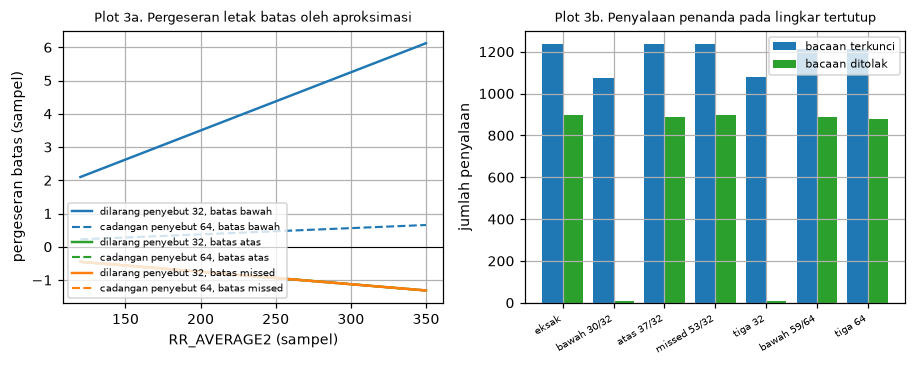

pergeseran batas dilarang penyebut 32 pada AVERAGE2 200 sampel: bawah +3.50, atas -0.75, missed -0.75 sampel
pergeseran batas cadangan penyebut 64 pada AVERAGE2 200 sampel: bawah +0.375, atas -0.750, missed -0.750 sampel
penyalaan penanda, bacaan terkunci: eksak 1238, dilarang bawah 30/32 1074, cadangan bawah 59/64 1214
penyalaan penanda, bacaan ditolak: eksak 898, dilarang bawah 30/32 9, cadangan bawah 59/64 890


In [13]:
# Tujuan: menggambar pergeseran letak batas oleh bentuk cadangan dan bentuk dilarang, serta jumlah
# penyalaan penanda irama teratur tiap kombinasi bentuk pada kedua bacaan persamaan (25).
# Cell ini menampilkan Plot 3 dengan dua panel dan mencetak pergeseran batas pada AVERAGE2 200 sampel
# beserta penyalaan penanda tiap kombinasi.

fig3, axs3 = plt.subplots(1, 2, figsize=(8.4, 3.4))
av_uji = np.linspace(120.0, 350.0, 300)
warna = {"bawah": "C0", "atas": "C2", "missed": "C1"}
for nama in ("bawah", "atas", "missed"):
    geser_cadangan = (float(Fraction(*PECAH_CADANGAN[nama])) - float(Fraction(*PECAH_TEPAT[nama]))) * av_uji
    geser_dilarang = (float(Fraction(*PECAH_DILARANG[nama])) - float(Fraction(*PECAH_TEPAT[nama]))) * av_uji
    axs3[0].plot(av_uji, geser_dilarang, warna[nama] + "-", lw=1.6,
                 label="dilarang penyebut 32, batas " + nama)
    axs3[0].plot(av_uji, geser_cadangan, warna[nama] + "--", lw=1.4,
                 label="cadangan penyebut 64, batas " + nama)
axs3[0].axhline(0.0, color="k", lw=0.7)
axs3[0].set_title("Plot 3a. Pergeseran letak batas oleh aproksimasi", fontsize=8.5)
axs3[0].set_xlabel("RR_AVERAGE2 (sampel)")
axs3[0].set_ylabel("pergeseran batas (sampel)")
axs3[0].legend(loc="lower left", fontsize=6.5)
pos_x = np.arange(df_kombinasi.shape[0])
axs3[1].bar(pos_x - 0.20, df_kombinasi["penanda terkunci"], width=0.40, color="C0", label="bacaan terkunci")
axs3[1].bar(pos_x + 0.20, df_kombinasi["penanda ditolak"], width=0.40, color="C2", label="bacaan ditolak")
axs3[1].set_xticks(pos_x)
axs3[1].set_xticklabels(["eksak", "bawah 30/32", "atas 37/32", "missed 53/32", "tiga 32", "bawah 59/64", "tiga 64"],
                        rotation=30, fontsize=6.5, ha="right")
axs3[1].set_title("Plot 3b. Penyalaan penanda pada lingkar tertutup", fontsize=8.5)
axs3[1].set_ylabel("jumlah penyalaan")
axs3[1].legend(loc="upper right", fontsize=7.5)
fig3.tight_layout()
plt.show()

print("pergeseran batas dilarang penyebut 32 pada AVERAGE2 200 sampel: bawah %+.2f, atas %+.2f, missed %+.2f sampel"
      % (float((Fraction(*PECAH_DILARANG["bawah"]) - Fraction(*PECAH_TEPAT["bawah"])) * 200),
         float((Fraction(*PECAH_DILARANG["atas"]) - Fraction(*PECAH_TEPAT["atas"])) * 200),
         float((Fraction(*PECAH_DILARANG["missed"]) - Fraction(*PECAH_TEPAT["missed"])) * 200)))
print("pergeseran batas cadangan penyebut 64 pada AVERAGE2 200 sampel: bawah %+.3f, atas %+.3f, missed %+.3f sampel"
      % (float((Fraction(*PECAH_CADANGAN["bawah"]) - Fraction(*PECAH_TEPAT["bawah"])) * 200),
         float((Fraction(*PECAH_CADANGAN["atas"]) - Fraction(*PECAH_TEPAT["atas"])) * 200),
         float((Fraction(*PECAH_CADANGAN["missed"]) - float(Fraction(*PECAH_TEPAT["missed"]))) * 200)))
print("penyalaan penanda, bacaan terkunci: eksak %d, dilarang bawah 30/32 %d, cadangan bawah 59/64 %d"
      % (int(df_kombinasi.loc[0, "penanda terkunci"]), int(df_kombinasi.loc[1, "penanda terkunci"]),
         int(df_kombinasi.loc[5, "penanda terkunci"])))
print("penyalaan penanda, bacaan ditolak: eksak %d, dilarang bawah 30/32 %d, cadangan bawah 59/64 %d"
      % (int(df_kombinasi.loc[0, "penanda ditolak"]), int(df_kombinasi.loc[1, "penanda ditolak"]),
         int(df_kombinasi.loc[5, "penanda ditolak"])))


### 6.2 Akibat keempat keputusan terkunci pada rekaman uji

Sel berikut melaporkan ulang empat keputusan yang dikunci pada 19 Oktober 2026 sebagai satu berkas
angka pada rekaman uji `04015`, supaya akibatnya dapat dibaca tanpa menelusuri seluruh bagian:

1. Bacaan persamaan (25) yang dipakai selalu memakai delapan sampel, sedangkan bacaan yang ditolak dapat
   memakai nol sampel dan membeku sampai ratusan denyut.
2. Bentuk batas bawah eksak 23 per 25 memberi jumlah penyalaan penanda tertentu, bentuk cadangan 59 per
   64 memberi jumlah lain yang lebih kecil, dan bentuk 30 per 32 yang dilarang meruntuhkan penanda itu.
3. Satuan sampel membayar galat penanda waktu sebesar 3,5 ms, yang adalah harga keputusan itu.
4. Penampan puncak kandidat terpakai sampai kedalaman tertentu pada rekaman ini, dan kedalaman itu
   dilaporkan terpisah di bagian 8.1.

Angka 9 penyalaan pada bentuk 30 per 32 tetap dicatat di sini sebagai peringatan, bukan sebagai hasil
yang boleh dipakai.


In [14]:
# Tujuan: melaporkan ulang akibat keempat keputusan terkunci 19 Oktober 2026 pada rekaman uji 04015.
# Cell ini mencetak jumlah penyalaan penanda irama teratur dengan bentuk eksak 23 per 25, dengan bentuk
# cadangan 59 per 64, dan dengan bentuk 30 per 32 yang dilarang, pada bacaan terkunci dan pada bacaan
# yang ditolak, beserta jumlah sampel RR_AVERAGE2, galat satuan sampel, dan kedalaman penampan.

baris_akibat = []
for nama_bentuk, pecah in (("eksak 23/25", dict(PECAH_TEPAT)),
                           ("cadangan 59/64", dict(PECAH_TEPAT, bawah=PECAH_CADANGAN["bawah"])),
                           ("dilarang 30/32", dict(PECAH_TEPAT, bawah=PECAH_DILARANG["bawah"]))):
    for cara in (CARA_BAWAAN, CARA_DITOLAK):
        h = rata_dua(rr_deret, pecah, cara)
        ok = ~np.isnan(h["avg1"])
        baris_akibat.append({"bentuk batas bawah": nama_bentuk, "bacaan persamaan (25)": cara,
                             "penanda menyala": int(h["reg"][ok].sum()),
                             "langkah diuji": int(ok.sum()),
                             "sampel AVERAGE2 minimum": int(h["penyebut"][ok].min()),
                             "sampel AVERAGE2 maksimum": int(h["penyebut"][ok].max())})
df_akibat = pd.DataFrame(baris_akibat)
print("akibat keempat keputusan terkunci 19 Oktober 2026 pada rekaman uji 04015, %d interval RR bersatuan sampel"
      % rr_deret.size)
print(df_akibat.to_string(index=False))
print()
ambil = lambda b, c: int(df_akibat.loc[(df_akibat["bentuk batas bawah"] == b)
                                        & (df_akibat["bacaan persamaan (25)"] == c), "penanda menyala"].iloc[0])
eksak_kunci = ambil("eksak 23/25", CARA_BAWAAN)
cadangan_kunci = ambil("cadangan 59/64", CARA_BAWAAN)
dilarang_kunci = ambil("dilarang 30/32", CARA_BAWAAN)
eksak_ditolak = ambil("eksak 23/25", CARA_DITOLAK)
dilarang_ditolak = ambil("dilarang 30/32", CARA_DITOLAK)
kunci_ditolak = df_akibat[df_akibat["bacaan persamaan (25)"] == CARA_DITOLAK]
sampel_min_ditolak = int(kunci_ditolak["sampel AVERAGE2 minimum"].min())
sampel_min_kunci = int(df_akibat[df_akibat["bacaan persamaan (25)"] == CARA_BAWAAN]["sampel AVERAGE2 minimum"].min())
print("P4-1 bacaan terkunci %s: penanda menyala %d dengan bentuk eksak, dan jumlah sampel RR_AVERAGE2 selalu %d pada seluruh langkah"
      % (CARA_BAWAAN, eksak_kunci, sampel_min_kunci))
print("     bacaan ditolak %s: penanda menyala %d dengan bentuk eksak, jumlah sampel RR_AVERAGE2 minimum %d, dan saat himpunan interval segar kosong RR_AVERAGE2 membeku sampai %d denyut atau %.1f detik"
      % (CARA_DITOLAK, eksak_ditolak, sampel_min_ditolak, HASIL["jeda beku AVERAGE2 maksimum (denyut)"],
         HASIL["jeda beku AVERAGE2 maksimum (detik)"]))
print("P4-2 batas bawah bentuk eksak 23/25 : penanda menyala %d kali pada bacaan terkunci" % eksak_kunci)
print("     batas bawah cadangan 59/64      : penanda menyala %d kali, selisih %+d dari bentuk eksak"
      % (cadangan_kunci, cadangan_kunci - eksak_kunci))
print("     batas bawah dilarang 30/32      : penanda menyala %d kali pada bacaan terkunci dan %d kali pada bacaan ditolak"
      % (dilarang_kunci, dilarang_ditolak))
print("     PERINGATAN: bentuk 30 per 32 dilarang karena galat relatif %.4f persen terhadap 23 per 25,"
      % (100.0 * (float(Fraction(*PECAH_DILARANG["bawah"]) / Fraction(*PECAH_TEPAT["bawah"])) - 1.0)))
print("     dan pada bacaan yang ditolak bentuk itu terukur meruntuhkan penanda dari %d penyalaan menjadi %d penyalaan;"
      % (eksak_ditolak, dilarang_ditolak))
print("     pada bacaan terkunci runtuhnya setara, dari %d penyalaan menjadi %d penyalaan."
      % (eksak_kunci, dilarang_kunci))
print("P4-3 satuan %s: galat geser kanan tiga bit paling besar %.4f sampel yaitu %.1f ms, terukur %.4f sampel yaitu %.2f ms"
      % (SATUAN_RR, 7.0 / 8.0, 7.0 / 8.0 * MS_PER_SAMPEL, HASIL["galat geser sampel maksimum"],
         HASIL["galat geser sampel maksimum"] * MS_PER_SAMPEL))
print("P4-4 penampan puncak kandidat: terpakai %d puncak sekaligus pada rekaman ini, kedalaman terkunci %d puncak,"
      % (penampan_b.pemakaian_terbesar, penampan_b.kedalaman))
print("     kandidat yang dibuang pada pemetik B %d, dan lebar RR %d bit penuh tanpa dijepit ke 13 bit."
      % (penampan_b.dibuang, LEBAR_RR_BIT))
HASIL["penanda eksak bacaan terkunci"] = eksak_kunci
HASIL["penanda cadangan 59/64 bacaan terkunci"] = cadangan_kunci
HASIL["penanda dilarang 30/32 bacaan terkunci"] = dilarang_kunci
HASIL["penanda eksak bacaan ditolak"] = eksak_ditolak
HASIL["penanda dilarang 30/32 bacaan ditolak"] = dilarang_ditolak


akibat keempat keputusan terkunci 19 Oktober 2026 pada rekaman uji 04015, 2522 interval RR bersatuan sampel
bentuk batas bawah bacaan persamaan (25)  penanda menyala  langkah diuji  sampel AVERAGE2 minimum  sampel AVERAGE2 maksimum
       eksak 23/25               antrean             1238           2515                        8                         8
       eksak 23/25              langsung              898           2515                        1                         8
    cadangan 59/64               antrean             1214           2515                        8                         8
    cadangan 59/64              langsung              890           2515                        1                         8
    dilarang 30/32               antrean             1074           2515                        8                         8
    dilarang 30/32              langsung                9           2515                        1                         8

P4-1 bacaan terkunci an

## 7. Penanda irama teratur, persamaan (29)

Persamaan (29) memberi penanda satu bit: bila kedelapan interval RR terakhir semuanya berada di antara
$RR_{LOW}$ dan $RR_{HIGH}$, maka irama dinyatakan teratur untuk delapan denyut itu, dan
$RR_{AVERAGE2}$ ditugasi sama dengan $RR_{AVERAGE1}$. Makalah menutup dengan kalimat "This is the case
for normal sinus rhythm", jadi penanda itu memang dimaksudkan sebagai penanda irama sinus normal.
Penanda itu dihitung dengan bacaan terkunci dan bentuk batas eksak 23 per 25, jadi kedelapan interval
yang diperiksa adalah delapan interval terakhir yang dihitung dari $RR_{AVERAGE1}$, tanpa penyaringan.

Ada dua hal yang harus diukur sebelum penanda itu dipakai sebagai gerbang. Pertama, berapa kali ia
menyala pada jendela bertanda AFIB dan berapa kali pada jendela bertanda N, karena gerbang hanya berguna
kalau kedua angka itu jauh berbeda. Kedua, apakah syaratnya, yaitu kedelapan interval berturut-turut
harus berada di dalam batas, membuatnya terlalu jarang menyala sehingga tidak berguna pada segmen
pendek. Perlu diingat bahwa penanda ini hanya punya dua keadaan, jadi angka yang penting adalah
fraksi waktu menyala, bukan jumlah mentah. Bacaan persamaan (25) yang ditolak tetap dicatat di sini
sebagai pembanding, supaya terlihat berapa besar bedanya pada tingkat jendela.

Sejak keputusan P4-5, penyalaan penanda itu dihitung pada jalur yang memakai aturan penyemaian
ulang antrean rata-rata kedua, dan jalur tanpa aturan tetap dihitung sebagai pembanding. Akibat aturan
itu pada gerbang keputusan dilaporkan di sel terakhir bagian ini, dengan ambang gerbang yang diturunkan
ulang pada deret detektor sendiri dan bukan dari ambang lama.


In [15]:
# Tujuan: menghitung penyalaan penanda irama teratur persamaan (29) pada jendela AFIB dan jendela N
# memakai bacaan terkunci, dan menyisakan bacaan yang ditolak sebagai pembanding singkat.
# Cell ini mencetak jumlah dan fraksi penyalaan per kelas irama, tabel per jendela beserta laju denyutnya,
# angka penanda pada deret hasil topeng mutu, dan penilaian gerbang pada tingkat jendela.

h_reg = h_kunci
h_reg_ditolak = h_ditolak
ok_reg = ~np.isnan(h_reg["avg1"])
print("penanda irama teratur, persamaan (29), pada rekaman 04015, bentuk batas eksak 23 per 25")
for cara, hh in ((CARA_BAWAAN + " terkunci", h_reg), (CARA_DITOLAK + " ditolak", h_reg_ditolak)):
    print("  bacaan %-20s: menyala %d dari %d langkah (%.4f)"
          % (cara, int(hh["reg"][ok_reg].sum()), int(ok_reg.sum()), float(np.mean(hh["reg"][ok_reg]))))
print()
for nama in ("N", "AFIB"):
    m = ok_reg & (label_kelas == nama)
    print("  kelas %-4s: %5d langkah, menyala %5d kali (%.4f), laju denyut median %.1f bpm, simpangan baku RR relatif %.4f"
          % (nama, int(m.sum()), int(h_reg["reg"][m].sum()), float(np.mean(h_reg["reg"][m])),
             60000.0 / float(np.median(rr_ms[m])), float(np.std(rr_ms[m]) / np.mean(rr_ms[m]))))
print()
baris_jendela = []
for s0, s1, nama in JENDELA_KELAS:
    m = ok_reg & (t_puncak >= s0 / FS) & (t_puncak < s1 / FS)
    if m.sum() == 0:
        continue
    durasi = (s1 - s0) / FS
    baris_jendela.append({"kelas": nama, "durasi (s)": durasi, "denyut": int(m.sum()),
                          "menyala terkunci": int(h_reg["reg"][m].sum()),
                          "fraksi terkunci": float(np.mean(h_reg["reg"][m])),
                          "fraksi ditolak": float(np.mean(h_reg_ditolak["reg"][m])),
                          "menyala per detik": float(h_reg["reg"][m].sum() / durasi),
                          "laju (bpm)": float(60000.0 / np.median(rr_ms[m]))})
df_jendela = pd.DataFrame(baris_jendela)
print("tabel penanda per jendela kelas irama:")
print(df_jendela.to_string(index=False))
print()
AMBANG_GERBANG = 0.10
benar = 0
salah = 0
for _, b in df_jendela.iterrows():
    teratur = b["fraksi terkunci"] >= AMBANG_GERBANG
    kelas_sebenarnya = b["kelas"]
    if kelas_sebenarnya == "AFIB" and not teratur:
        benar += 1
    if kelas_sebenarnya == "N" and teratur:
        benar += 1
    if kelas_sebenarnya == "AFIB" and teratur:
        salah += 1
    if kelas_sebenarnya == "N" and not teratur:
        salah += 1
print("penilaian gerbang pada tingkat jendela, ambang fraksi %.2f: jendela benar %d, jendela salah %d, dari %d jendela"
      % (AMBANG_GERBANG, benar, salah, df_jendela.shape[0]))
print("  jendela AFIB : %d jendela, fraksi menyala %s" % (int((df_jendela["kelas"] == "AFIB").sum()),
                                                          np.round(df_jendela.loc[df_jendela["kelas"] == "AFIB", "fraksi terkunci"].to_numpy(), 4)))
print("  jendela N    : %d jendela, fraksi menyala %s" % (int((df_jendela["kelas"] == "N").sum()),
                                                          np.round(df_jendela.loc[df_jendela["kelas"] == "N", "fraksi terkunci"].to_numpy(), 4)))

h_reg_topeng = rata_dua(rr_deret[topeng], BENTUK_BAWAAN, CARA_BAWAAN)
label_topeng = label_kelas[topeng]
ok_topeng = ~np.isnan(h_reg_topeng["avg1"])
print()
print("dengan topeng mutu, %d interval lolos dari %d" % (int(topeng.sum()), topeng.size))
for nama in ("N", "AFIB"):
    m = ok_topeng & (label_topeng == nama)
    print("  kelas %-4s: %5d langkah, menyala %5d kali (%.4f)"
          % (nama, int(m.sum()), int(h_reg_topeng["reg"][m].sum()), float(np.mean(h_reg_topeng["reg"][m]))))
print("  interval yang melewati batas missed: tanpa topeng %d, dengan topeng %d"
      % (int(np.sum(h_reg["lewat"][ok_reg])), int(np.sum(h_reg_topeng["lewat"][ok_topeng]))))
HASIL["penanda menyala pada AFIB"] = float(np.mean(h_reg["reg"][ok_reg & (label_kelas == "AFIB")]))
HASIL["penanda menyala pada N"] = float(np.mean(h_reg["reg"][ok_reg & (label_kelas == "N")]))
HASIL["penanda menyala seluruh rekaman"] = float(np.mean(h_reg["reg"][ok_reg]))
HASIL["jendela gerbang benar"] = int(benar)
HASIL["jendela gerbang salah"] = int(salah)


penanda irama teratur, persamaan (29), pada rekaman 04015, bentuk batas eksak 23 per 25
  bacaan antrean terkunci    : menyala 1238 dari 2515 langkah (0.4922)
  bacaan langsung ditolak    : menyala 898 dari 2515 langkah (0.3571)

  kelas N   :  2151 langkah, menyala  1238 kali (0.5755), laju denyut median 80.6 bpm, simpangan baku RR relatif 0.3484
  kelas AFIB:   364 langkah, menyala     0 kali (0.0000), laju denyut median 119.0 bpm, simpangan baku RR relatif 0.2682

tabel penanda per jendela kelas irama:
kelas  durasi (s)  denyut  menyala terkunci  fraksi terkunci  fraksi ditolak  menyala per detik  laju (bpm)
    N     410.216     556                44         0.079137        0.016187           0.107261   90.361446
 AFIB      68.080     123                 0         0.000000        0.000000           0.000000  119.047619
    N       8.676      12                 0         0.000000        0.000000           0.000000   81.081081
 AFIB       1.684       3                 0         0.000

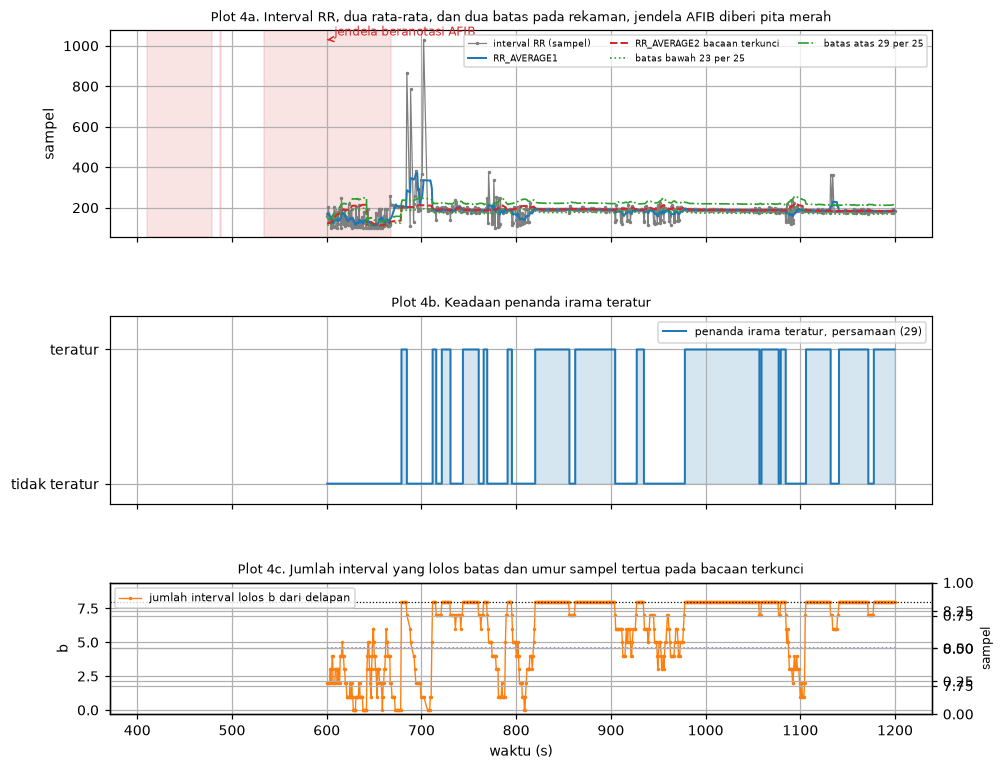

jendela yang digambar 600.0 sampai 1200.0 detik, 824 interval
  fraksi penanda menyala : 0.5000
  jumlah peralihan keadaan penanda : 29
  jendela beranotasi AFIB di dalam rentang gambar : 124 interval
  jumlah interval lolos b sama dengan delapan, fraksi 0.5000
  jumlah sampel RR_AVERAGE2 pada jendela ini : minimum 8, maksimum 8
  umur sampel tertua pada jendela ini : median 8 denyut, maksimum 21 denyut


In [16]:
# Tujuan: menggambar keadaan penanda irama teratur pada rekaman bersama deret interval RR, batasnya,
# jumlah sampel RR_AVERAGE2, dan umur sampel tertua pada bacaan terkunci.
# Cell ini menampilkan Plot 4 dengan tiga panel dan mencetak fraksi menyala pada jendela yang digambar
# beserta jumlah peralihan keadaan penanda.

B0 = 600.0
B1 = 1200.0
sel_p = (t_puncak >= B0) & (t_puncak < B1)
t_p = t_puncak[sel_p]
rr_p = rr_deret[sel_p]
a2_p = h_reg["avg2"][sel_p]
a1_p = h_reg["avg1"][sel_p]
reg_p = h_reg["reg"][sel_p]
umur_p = h_reg["umur"][sel_p]
kelas_p = label_kelas[sel_p]

fig4, axs4 = plt.subplots(3, 1, figsize=(8.4, 7.4), sharex=True,
                          gridspec_kw={"height_ratios": [1.1, 1.0, 0.7], "hspace": 0.45})
for s0, s1, nama in JENDELA_KELAS:
    if nama == "AFIB":
        axs4[0].axvspan(s0 / FS, s1 / FS, color="C3", alpha=0.13)
axs4[0].plot(t_p, rr_p, "C7.-", ms=2.5, lw=0.8, label="interval RR (sampel)")
axs4[0].plot(t_p, a1_p, "C0-", lw=1.3, label="RR_AVERAGE1")
axs4[0].plot(t_p, a2_p, "C3--", lw=1.3, label="RR_AVERAGE2 bacaan terkunci")
axs4[0].plot(t_p, K_TAMPIL["bawah"] * a2_p, "C2:", lw=1.1, label="batas bawah 23 per 25")
axs4[0].plot(t_p, K_TAMPIL["atas"] * a2_p, "C2-.", lw=1.1, label="batas atas 29 per 25")
mask_afib_p = kelas_p == "AFIB"
if mask_afib_p.any():
    axs4[0].annotate("jendela beranotasi AFIB", xy=(t_p[mask_afib_p][0], float(np.max(rr_p))),
                     xytext=(B0 + 8.0, float(np.max(rr_p)) * 1.02), color="C3", fontsize=8,
                     arrowprops=dict(arrowstyle="->", color="C3"))
axs4[0].set_title("Plot 4a. Interval RR, dua rata-rata, dan dua batas pada rekaman, jendela AFIB diberi pita merah", fontsize=8.5)
axs4[0].set_ylabel("sampel")
axs4[0].legend(loc="upper right", fontsize=6.0, ncol=3)
axs4[1].step(t_p, reg_p.astype(float), "C0-", where="post", lw=1.3, label="penanda irama teratur, persamaan (29)")
axs4[1].fill_between(t_p, 0.0, reg_p.astype(float), step="post", color="C0", alpha=0.18)
axs4[1].set_ylim(-0.15, 1.25)
axs4[1].set_yticks([0.0, 1.0])
axs4[1].set_yticklabels(["tidak teratur", "teratur"])
axs4[1].set_title("Plot 4b. Keadaan penanda irama teratur", fontsize=8.5)
axs4[1].legend(loc="upper right", fontsize=7.5)
axs4[2].plot(t_p, h_reg["masuk"][sel_p], "C1.-", ms=2.5, lw=0.9, label="jumlah interval lolos b dari delapan")
axs4[2].axhline(DELAPAN, color="k", ls=":", lw=0.8)
axs4[2].set_ylim(-0.3, 9.4)
axs4[2].set_title("Plot 4c. Jumlah interval yang lolos batas dan umur sampel tertua pada bacaan terkunci", fontsize=8.5)
axs4[2].set_xlabel("waktu (s)")
axs4[2].set_ylabel("b")
axs4[2].legend(loc="upper left", fontsize=7.0)
axs4[2].twinx().plot(t_p, h_reg["penyebut"][sel_p], "C4:", lw=1.0, label="jumlah sampel AVERAGE2")
axs4[2].twinx().set_ylabel("sampel", fontsize=8)
fig4.subplots_adjust(top=0.93, bottom=0.09, left=0.09, right=0.98, hspace=0.42)
plt.show()

print("jendela yang digambar %.1f sampai %.1f detik, %d interval" % (B0, B1, rr_p.size))
print("  fraksi penanda menyala : %.4f" % float(np.mean(reg_p)))
print("  jumlah peralihan keadaan penanda : %d" % int(np.sum(np.abs(np.diff(reg_p.astype(int))))))
print("  jendela beranotasi AFIB di dalam rentang gambar : %d interval" % int(np.sum(mask_afib_p)))
print("  jumlah interval lolos b sama dengan delapan, fraksi %.4f" % float(np.mean(h_reg["masuk"][sel_p] == DELAPAN)))
print("  jumlah sampel RR_AVERAGE2 pada jendela ini : minimum %d, maksimum %d"
      % (int(h_reg["penyebut"][sel_p].min()), int(h_reg["penyebut"][sel_p].max())))
print("  umur sampel tertua pada jendela ini : median %d denyut, maksimum %d denyut"
      % (int(np.median(umur_p)), int(umur_p.max())))
HASIL["fraksi penanda pada jendela gambar"] = float(np.mean(reg_p))
HASIL["umur sampel tertua pada jendela gambar"] = int(umur_p.max())


In [17]:
# Tujuan: melaporkan akibat aturan P4-5 pada gerbang keputusan tingkat jendela, memakai ambang gerbang
# yang diturunkan ulang pada deret detektor sendiri dan bukan ambang lama 0,70.
# Cell ini mencetak tabel jendela uji pada kedua jalur, seluruh ambang turunan beserta kepekaan dan
# spesifisitasnya, ambang terpilih, lalu kepekaan, spesifisitas, dan akurasi pada ambang terpilih, serta
# pembanding ambang lama 0,70 yang tidak boleh dipindahkan.

AMBANG_LAMA_TIDAK_BOLEH_DIPINDAHKAN = 0.70


def tabel_gerbang_jendela(h):
    """Fraksi penyalaan penanda tiap jendela kelas irama pada satu jalur rata-rata kedua."""
    o = ~np.isnan(h["avg1"])
    baris = []
    for s0, s1, nama in JENDELA_KELAS:
        m = o & (t_puncak >= s0 / FS) & (t_puncak < s1 / FS)
        if m.sum() == 0:
            continue
        baris.append({"kelas": nama, "durasi (s)": (s1 - s0) / FS, "denyut": int(m.sum()),
                      "fraksi penanda": float(np.mean(h["reg"][m]))})
    return pd.DataFrame(baris)


def keputusan_gerbang(df, ambang):
    """Keputusan gerbang satu jendela: fraksi penanda di bawah ambang berarti tidak teratur yaitu AFIB,
    fraksi penanda mencapai ambang berarti teratur yaitu N."""
    teratur = df["fraksi penanda"].to_numpy() >= ambang
    kelas = df["kelas"].to_numpy()
    tp = int(np.sum((kelas == "AFIB") & ~teratur))
    fn = int(np.sum((kelas == "AFIB") & teratur))
    fp = int(np.sum((kelas == "N") & ~teratur))
    tn = int(np.sum((kelas == "N") & teratur))
    return dict(TP=tp, FN=fn, FP=fp, TN=tn,
                kepekaan=tp / max(tp + fn, 1),
                spesifisitas=tn / max(tn + fp, 1),
                akurasi=(tp + tn) / max(df.shape[0], 1))


def ambang_turunan(df):
    """Ambang gerbang diturunkan ulang dari deret fraksi detektor sendiri, bukan dari tetapan lama. Yang
    diuji adalah nol, setiap nilai tengah antara dua fraksi bertetangga, dan ujung atas rentang, lalu
    yang dipilih adalah ambang dengan rata-rata kepekaan dan spesifisitas terbesar."""
    fr = np.sort(np.unique(df["fraksi penanda"].to_numpy()))
    kandidat = [0.0]
    kandidat.extend(((fr[:-1] + fr[1:]) / 2.0).tolist())
    kandidat.append(float(fr[-1]) + 0.5)
    baris = []
    terbaik, nilai_terbaik = 0.0, -1.0
    for c in kandidat:
        d = keputusan_gerbang(df, float(c))
        nilai = 0.5 * (d["kepekaan"] + d["spesifisitas"])
        baris.append({"ambang": float(c), "kepekaan": d["kepekaan"], "spesifisitas": d["spesifisitas"],
                      "akurasi": d["akurasi"], "rata kepekaan dan spesifisitas": nilai})
        if nilai > nilai_terbaik + 1e-12:
            terbaik, nilai_terbaik = float(c), nilai
    return terbaik, pd.DataFrame(baris)


bentuk_gerbang = {}
for nama_jalur, h in (("tanpa aturan P4-5", h_tanpa_p45), ("dengan aturan P4-5", h_kunci)):
    df_j = tabel_gerbang_jendela(h)
    ambang_pilih, df_ambang = ambang_turunan(df_j)
    d_pilih = keputusan_gerbang(df_j, ambang_pilih)
    d_lama = keputusan_gerbang(df_j, AMBANG_LAMA_TIDAK_BOLEH_DIPINDAHKAN)
    bentuk_gerbang[nama_jalur] = dict(df=df_j, ambang=ambang_pilih, d=d_pilih, d_lama=d_lama,
                                      df_ambang=df_ambang)
    print("gerbang keputusan tingkat jendela, jalur %s:" % nama_jalur)
    print(df_j.to_string(index=False))
    print("  ambang turunan dari deret detektor sendiri : %.6f" % ambang_pilih)
    print(df_ambang.to_string(index=False))
    print("  pada ambang turunan: kepekaan %.4f, spesifisitas %.4f, akurasi %.4f dari %d jendela uji"
          % (d_pilih["kepekaan"], d_pilih["spesifisitas"], d_pilih["akurasi"], df_j.shape[0]))
    print("  hitungan jendela: TP %d, FN %d, FP %d, TN %d" % (d_pilih["TP"], d_pilih["FN"], d_pilih["FP"], d_pilih["TN"]))
    print("  pembanding ambang lama %.2f yang tidak boleh dipindahkan: kepekaan %.4f, spesifisitas %.4f, akurasi %.4f"
          % (AMBANG_LAMA_TIDAK_BOLEH_DIPINDAHKAN, d_lama["kepekaan"], d_lama["spesifisitas"], d_lama["akurasi"]))
    print()
print("CATATAN: ambang gerbang lama %.2f TIDAK BOLEH DIPINDAHKAN. Ambang itu adalah ambang entropi ternormalisasi"
      % AMBANG_LAMA_TIDAK_BOLEH_DIPINDAHKAN)
print("pada gerbang AND tahap penggolongan irama, dan dokumen itu sendiri menulis bahwa pemindahannya ke deret")
print("detektor sendiri belum boleh dilakukan. Ambang yang dipakai di sel ini adalah ambang yang diturunkan")
print("ulang pada deret detektor sendiri, yaitu pada deret fraksi penanda jendela uji di notebook ini, sehingga")
print("nilainya ikut berubah bila aturan P4-5 mengubah fraksi penanda, dan tidak ada ambang lama yang")
print("dipindahkan dari satu jalur ke jalur lain.")
print()
print("akibat aturan P4-5 pada gerbang keputusan:")
for nama_jalur in ("tanpa aturan P4-5", "dengan aturan P4-5"):
    b = bentuk_gerbang[nama_jalur]
    print("  jalur %-18s: ambang %.6f, kepekaan %.4f, spesifisitas %.4f, akurasi %.4f, jendela benar %d dari %d"
          % (nama_jalur, b["ambang"], b["d"]["kepekaan"], b["d"]["spesifisitas"], b["d"]["akurasi"],
             b["d"]["TP"] + b["d"]["TN"], b["df"].shape[0]))
selisih_aka = bentuk_gerbang["dengan aturan P4-5"]["d"]["akurasi"] - bentuk_gerbang["tanpa aturan P4-5"]["d"]["akurasi"]
print("  selisih akurasi kedua jalur : %+.4f, jadi aturan P4-5 %s keputusan gerbang tingkat jendela pada rekaman ini"
      % (selisih_aka, "mengubah" if abs(selisih_aka) > 1e-9 else "tidak mengubah"))
for nama_jalur in ("tanpa aturan P4-5", "dengan aturan P4-5"):
    df_j = bentuk_gerbang[nama_jalur]["df"]
    print("  fraksi penanda jendela N pada jalur %-18s: %s"
          % (nama_jalur, np.round(df_j.loc[df_j["kelas"] == "N", "fraksi penanda"].to_numpy(), 4).tolist()))
HASIL["kepekaan gerbang dengan aturan P4-5"] = float(bentuk_gerbang["dengan aturan P4-5"]["d"]["kepekaan"])
HASIL["spesifisitas gerbang dengan aturan P4-5"] = float(bentuk_gerbang["dengan aturan P4-5"]["d"]["spesifisitas"])
HASIL["akurasi gerbang dengan aturan P4-5"] = float(bentuk_gerbang["dengan aturan P4-5"]["d"]["akurasi"])
HASIL["akurasi gerbang tanpa aturan P4-5"] = float(bentuk_gerbang["tanpa aturan P4-5"]["d"]["akurasi"])
HASIL["ambang gerbang turunan dengan aturan P4-5"] = float(bentuk_gerbang["dengan aturan P4-5"]["ambang"])


gerbang keputusan tingkat jendela, jalur tanpa aturan P4-5:
kelas  durasi (s)  denyut  fraksi penanda
    N     410.216     556        0.021583
 AFIB      68.080     123        0.000000
    N       8.676      12        0.000000
 AFIB       1.684       3        0.000000
    N      44.616      71        0.000000
 AFIB     134.036     238        0.000000
    N    1132.572    1512        0.588624
  ambang turunan dari deret detektor sendiri : 0.010791
  ambang  kepekaan  spesifisitas  akurasi  rata kepekaan dan spesifisitas
0.000000       0.0          1.00 0.571429                           0.500
0.010791       1.0          0.50 0.714286                           0.750
0.305104       1.0          0.25 0.571429                           0.625
1.088624       1.0          0.00 0.428571                           0.500
  pada ambang turunan: kepekaan 1.0000, spesifisitas 0.5000, akurasi 0.7143 dari 7 jendela uji
  hitungan jendela: TP 3, FN 0, FP 2, TN 2
  pembanding ambang lama 0.70 yang tidak

## 8. Prosedur search back langkah demi langkah

Kalimat makalah persisnya: "If a $QRS$ complex is not found during the interval specified by the
$RR$ $MISSED$ $LIMIT$, the maximal peak reserved between the two established thresholds is considered to
be a $QRS$ candidate." Kalimat itu mengandung seluruh prosedurnya, dan langkahnya dapat ditulis berurutan.

1. Sebelum pemeriksaan, ada dua ambang pada tiap jalur, ambang pertama $I1$ dan ambang kedua $I2$ yang
   nilainya separuh $I1$, ditetapkan dari $SPKI$ dan $NPKI$ menurut persamaan (14) dan (15).
2. Selama sinyal berjalan, setiap puncak lokal yang nilainya di atas ambang kedua tetapi di bawah ambang
   pertama tidak diangkat menjadi denyut, melainkan disimpan sebagai puncak cadangan. Inilah arti
   "between the two established thresholds", dan puncak itu harus disimpan bersama posisinya supaya
   penanda waktu tetap benar bila nanti diangkat.
3. Bersamaan dengan itu, jarak antara waktu sekarang dan waktu denyut terakhir yang sudah diangkat terus
   dibandingkan dengan $RR_{MISSED}$ pada persamaan (28), yaitu 83 per 50 dari $RR_{AVERAGE2}$.
4. Bila jarak itu melampaui $RR_{MISSED}$ padahal tidak ada denyut yang ditemukan, puncak cadangan
   dengan nilai terbesar di dalam selang itu diangkat menjadi calon kompleks QRS. Yang diambil adalah
   yang terbesar, bukan yang pertama, sesuai kata "maximal peak".
5. Penanda waktu hasil pengangkatan adalah posisi puncak cadangan itu, bukan waktu pemeriksaannya. Karena
   itu interval RR sesudah pengangkatan tetap benar, dan ini penting bagi persamaan (24).
6. Bila puncak itu diangkat, $SPKI$ dan $SPKF$ diperbarui dengan bobot seperempat, yaitu persamaan (21),
   bukan dengan bobot seperdelapan seperti pendeteksian biasa. Bobot yang lebih besar inilah yang
   membuat ambang bergerak lebih cepat setelah pengangkatan.
7. Kalau tidak ada puncak cadangan di dalam selang itu, tidak ada yang diangkat, dan pemeriksaan
   diulang pada selang berikutnya.

Puncak cadangan pada langkah 2 disimpan di dalam **penampan puncak kandidat**, yaitu struktur kecil
dengan kedalaman tetap sesuai keputusan P4-4. Penampan itu menyimpan pasangan posisi dan nilai untuk
tiap puncak cadangan, mengembalikan puncak terbesar saat diminta, lalu dikosongkan. Berapa puncak yang
harus tersimpan sekaligus diukur pada rekaman uji di bagian 8.1, dan di sel berikut pada deret buatan
bersatuan sampel dengan satu dan dua denyut yang amplitudonya dikecilkan sehingga jatuh di antara dua
ambang, tepat seperti keadaan yang dimaksud kalimat makalah. Seluruh besaran waktu di bagian ini
bersatuan sampel, sesuai satuan terkunci.


In [18]:
# Tujuan: menjalankan prosedur search back langkah demi langkah pada deret buatan bersatuan sampel dengan
# satu dan dua denyut hilang, memakai penampan puncak kandidat.
# Cell ini mencetak jumlah denyut asli, jumlah denyut terdeteksi, jumlah pengangkatan, posisi dan waktu
# pengangkatan, tunda tambahan dalam sampel dan milidetik, rumus tundanya, dan kedalaman penampan yang
# terpakai pada deret buatan itu.

def buat_denyut(rr_sampel_buat=200, hilang=(), n_denyut=60, amp=3.0, amp_hilang=1.0, sigma_sampel=7.5):
    """Selubung buatan bersatuan sampel, jarak denyut rr_sampel_buat, denyut pada indeks hilang dikecilkan."""
    durasi = 50 + n_denyut * rr_sampel_buat + 100
    n = durasi + 8
    env = np.zeros(n)
    for b in range(n_denyut):
        t0 = 50 + b * rr_sampel_buat
        a = amp_hilang if b in hilang else amp
        s = max(0, t0 - 30)
        e = min(n, t0 + 30)
        tt = np.arange(s, e)
        env[s:e] += a * np.exp(-((tt - t0) / sigma_sampel) ** 2.0)
    return env


def jalankan_search_back(env, rr_avg2=200, bentuk=None, I1=1.5, I2=0.75, refr=REFR_SAMPEL,
                         kedalaman=KEDALAMAN_PENAMPAN):
    """Prosedur search back bersatuan sampel dengan penampan puncak kandidat. Jarak ke denyut terakhir
    diuji terhadap batas missed lewat perkalian silang bulat, tanpa pembagian."""
    if bentuk is None:
        bentuk = BENTUK_BAWAAN
    n = env.size
    penampan = PenampanPuncak(kedalaman)
    last = -10 ** 12
    deteksi = []
    diangkat = []
    pemeriksaan = 0
    menunggu = False
    for i in range(1, n - 1):
        if bool(lewat_missed(i - last, bentuk["missed"], rr_avg2, 1)):
            kandidat = penampan.terbesar()
            if kandidat is not None:
                p, v = kandidat
                diangkat.append((p, v, i))
                deteksi.append(p)
                last = p
                penampan.kosongkan()
                menunggu = False
            elif not menunggu:
                pemeriksaan += 1
                menunggu = True
        if env[i] > env[i - 1] and env[i] >= env[i + 1] and env[i] > I2:
            if i - last < refr:
                continue
            if env[i] > I1:
                deteksi.append(i)
                last = i
                penampan.kosongkan()
                menunggu = False
            else:
                penampan.tambah(i, env[i])
    return np.array(sorted(deteksi)), diangkat, pemeriksaan, penampan


env_satu = buat_denyut(hilang=(30,))
det_satu, angkat_satu, cek_satu, penampan_satu = jalankan_search_back(env_satu)
env_dua = buat_denyut(hilang=(30, 31))
det_dua, angkat_dua, cek_dua, penampan_dua = jalankan_search_back(env_dua)
batas_missed_sampel = float(Fraction(83 * 200, 50))
print("deret buatan 60 denyut, RR tetap 200 sampel yaitu 800 ms, dua ambang I1 1,5 dan I2 0,75,")
print("batas missed 83 per 50 kali 200 sampel = %.1f sampel yaitu %.1f ms, refrakter %d sampel"
      % (batas_missed_sampel, batas_missed_sampel * MS_PER_SAMPEL, REFR_SAMPEL))
for nama, det, angkat, cek, penampan in (("satu denyut hilang", det_satu, angkat_satu, cek_satu, penampan_satu),
                                        ("dua denyut hilang", det_dua, angkat_dua, cek_dua, penampan_dua)):
    print()
    print("%s: denyut terdeteksi %d dari 60, puncak diangkat %d, pemeriksaan lewat batas %d"
          % (nama, det.size, len(angkat), cek))
    for p, v, i in angkat:
        print("  puncak cadangan pada sampel %d nilai %.3f, diangkat pada sampel %d, tunda %d sampel yaitu %.1f ms atau %.4f denyut"
              % (p, v, i, i - p, (i - p) * MS_PER_SAMPEL, (i - p) / 200.0))
    d = np.diff(det)
    print("  RR di sekitar kejadian (sampel):", d[28:35])
    print("  kedalaman penampan puncak kandidat terpakai %d dari %d, kandidat dibuang %d"
          % (penampan.pemakaian_terbesar, penampan.kedalaman, penampan.dibuang))
print()
print("rumus tunda: batas missed dikurangi RR yaitu 83 per 50 dikurangi 1 = %.4f kali RR, pada 200 sampel menjadi %.1f sampel yaitu %.1f ms"
      % (float(Fraction(83, 50)) - 1.0, (float(Fraction(83, 50)) - 1.0) * 200.0,
         (float(Fraction(83, 50)) - 1.0) * 200.0 * MS_PER_SAMPEL))
print("tunda terukur pada pengangkatan pertama %d sampel yaitu %.1f ms, selisih dari rumus %.1f sampel yaitu %.1f ms"
      % (angkat_satu[0][2] - angkat_satu[0][0], (angkat_satu[0][2] - angkat_satu[0][0]) * MS_PER_SAMPEL,
         (angkat_satu[0][2] - angkat_satu[0][0]) - (float(Fraction(83, 50)) - 1.0) * 200.0,
         ((angkat_satu[0][2] - angkat_satu[0][0]) - (float(Fraction(83, 50)) - 1.0) * 200.0) * MS_PER_SAMPEL))
HASIL["puncak diangkat satu denyut hilang"] = len(angkat_satu)
HASIL["tunda pengangkatan (sampel)"] = int(angkat_satu[0][2] - angkat_satu[0][0])
HASIL["kedalaman penampan deret buatan"] = int(penampan_satu.pemakaian_terbesar)
HASIL["RR_MISSED kurang RR"] = float(Fraction(83, 50)) - 1.0


deret buatan 60 denyut, RR tetap 200 sampel yaitu 800 ms, dua ambang I1 1,5 dan I2 0,75,
batas missed 83 per 50 kali 200 sampel = 332.0 sampel yaitu 1328.0 ms, refrakter 50 sampel

satu denyut hilang: denyut terdeteksi 60 dari 60, puncak diangkat 1, pemeriksaan lewat batas 1
  puncak cadangan pada sampel 6050 nilai 1.000, diangkat pada sampel 6183, tunda 133 sampel yaitu 532.0 ms atau 0.6650 denyut
  RR di sekitar kejadian (sampel): [200 200 200 200 200 200 200]
  kedalaman penampan puncak kandidat terpakai 1 dari 64, kandidat dibuang 0

dua denyut hilang: denyut terdeteksi 60 dari 60, puncak diangkat 2, pemeriksaan lewat batas 1
  puncak cadangan pada sampel 6050 nilai 1.000, diangkat pada sampel 6183, tunda 133 sampel yaitu 532.0 ms atau 0.6650 denyut
  puncak cadangan pada sampel 6250 nilai 1.000, diangkat pada sampel 6383, tunda 133 sampel yaitu 532.0 ms atau 0.6650 denyut
  RR di sekitar kejadian (sampel): [200 200 200 200 200 200 200]
  kedalaman penampan puncak kandidat terpakai

### 8.1 Kedalaman penampan puncak kandidat pada rekaman uji

Pertanyaan yang harus dijawab sebelum RTL ditulis adalah berapa puncak cadangan yang harus dapat
tersimpan sekaligus. Jawabannya tidak dapat diturunkan hanya dari aturan $RR_{MISSED}$, karena penampan
diisi setiap puncak lokal yang nilainya berada di antara dua ambang, dan pada irama tidak teratur kedua
ambang itu dipotong separuh menurut persamaan (22) dan (23) sehingga puncak riak ikut memenuhi syarat.
Sel berikut karena itu mengukur kedalaman itu langsung pada rekaman uji `04015` dengan tiga kedalaman
berbeda: pembanding tanpa batas kedalaman, kedalaman terkunci dari keputusan P4-4, dan kedalaman satu
puncak yang menyimpan hanya puncak terbesar. Ketiga jalannya dibandingkan, sehingga terlihat apakah
pembatasan kedalaman mengubah denyut yang ditemukan.


In [19]:
# Tujuan: mengukur kedalaman penampan puncak kandidat yang benar-benar dibutuhkan pada rekaman uji,
# yaitu berapa puncak yang harus tersimpan sekaligus pada kasus terburuk.
# Cell ini mencetak kedalaman terpakai terbesar pada rekaman, keadaan terburuknya, kedalaman yang
# disimpulkan dari jarak terpanjang dibagi refrakter, jumlah kandidat yang dibuang pada tiap kedalaman,
# dan perbandingan denyut yang ditemukan antara kedalaman kecil dan kedalaman tanpa batas.

hasil_acuan = puncak_adaptif(S_lingkungan, z3, kedalaman=100000)
hasil_terkunci = puncak_adaptif(S_lingkungan, z3, kedalaman=KEDALAMAN_PENAMPAN)
hasil_dangkal = puncak_adaptif(S_lingkungan, z3, kedalaman=1)
penampan_acuan = hasil_acuan["penampan"]
penampan_terkunci = hasil_terkunci["penampan"]
penampan_dangkal = hasil_dangkal["penampan"]
rr_acuan = hasil_acuan["rr"]
rr_terbesar = int(rr_deret.max())
kedalaman_analitik = -(-rr_terbesar // REFR_SAMPEL)
kedalaman_lebar_penuh = -(-(2 ** (LEBAR_RR_BIT - 1) - 1) // REFR_SAMPEL)
print("kedalaman penampan puncak kandidat pada rekaman uji 04015, %d puncak lokal diperiksa"
      % len(hasil_acuan["rr"]))
print("  kedalaman terpakai terbesar pada rekaman        : %d puncak" % penampan_acuan.pemakaian_terbesar)
print("  kandidat yang dibuang tanpa batas kedalaman      : %d" % penampan_acuan.dibuang)
print("  kedalaman terkunci dari keputusan P4-4           : %d puncak, dibuang %d"
      % (penampan_terkunci.kedalaman, penampan_terkunci.dibuang))
print("  kedalaman satu yang dicoba                       : %d puncak, dibuang %d"
      % (penampan_dangkal.kedalaman, penampan_dangkal.dibuang))
print("  denyut ditemukan sama pada ketiga kedalaman      : %s, jumlah puncak %d"
      % (bool(np.array_equal(hasil_acuan["puncak"], hasil_terkunci["puncak"])
              and np.array_equal(hasil_acuan["puncak"], hasil_dangkal["puncak"])),
         hasil_acuan["puncak"].size))
print()
print("dua cara membaca kedalaman terburuk:")
print("  terukur langsung pada rekaman                    : %d puncak" % penampan_acuan.pemakaian_terbesar)
print("  jarak RR terpanjang %d sampel dibagi refrakter %d sampel, dibulatkan ke atas : %d puncak"
      % (rr_terbesar, REFR_SAMPEL, kedalaman_analitik))
print("  kalau lebar RR %d bit dipakai penuh, batas atas kedalaman menurut cara yang sama : %d puncak"
      % (LEBAR_RR_BIT, kedalaman_lebar_penuh))
print()
rr_atas = float(np.median(rr_acuan)) * float(Fraction(83, 50))
print("alasan kedalaman itu tidak ditentukan batas missed saja: penampan dikosongkan setiap kali batas")
print("missed terlampaui, jadi kandidat menumpuk hanya selama jarak ke denyut terakhir masih di bawah")
print("batas itu; pada rekaman ini batas missed median adalah %.1f sampel, yaitu %.1f kali refrakter %d sampel"
      % (rr_atas, rr_atas / REFR_SAMPEL, REFR_SAMPEL))
print("sedangkan kedalaman terukur %d puncak muncul pada keadaan terburuk berikut:" % penampan_acuan.pemakaian_terbesar)
print("  rekaman berisi %d interval RR, RR terpanjang %d sampel yaitu %.1f ms"
      % (rr_deret.size, rr_terbesar, rr_terbesar * MS_PER_SAMPEL))
print("  pada jarak terpanjang itu jumlah puncak lokal yang memenuhi dua ambang sekaligus : %d"
      % penampan_acuan.pemakaian_terbesar)
print()
print("kesimpulan yang dipakai RTL: kedalaman penampan yang benar-benar dibutuhkan pada rekaman uji")
print("adalah %d puncak, kedalaman terkunci %d puncak memberi margin %.2f kali tanpa membuang satu kandidat pun,"
      % (penampan_acuan.pemakaian_terbesar, KEDALAMAN_PENAMPAN, KEDALAMAN_PENAMPAN / float(penampan_acuan.pemakaian_terbesar)))
print("dan karena penampan hanya dibaca oleh operasi terbesar, kedalaman satu puncak pun memberi denyut")
print("yang sama pada rekaman ini dengan %d kandidat dibuang, sehingga kedalaman itu adalah pilihan biaya."
      % penampan_dangkal.dibuang)
HASIL["kedalaman penampan dibutuhkan"] = int(penampan_acuan.pemakaian_terbesar)
HASIL["kedalaman penampan dibuang pada kedalaman satu"] = int(penampan_dangkal.dibuang)
HASIL["kedalaman penampan analitik dari RR terpanjang"] = int(kedalaman_analitik)
HASIL["kedalaman penampan pada lebar RR penuh"] = int(kedalaman_lebar_penuh)


kedalaman penampan puncak kandidat pada rekaman uji 04015, 2659 puncak lokal diperiksa
  kedalaman terpakai terbesar pada rekaman        : 36 puncak
  kandidat yang dibuang tanpa batas kedalaman      : 0
  kedalaman terkunci dari keputusan P4-4           : 64 puncak, dibuang 0
  kedalaman satu yang dicoba                       : 1 puncak, dibuang 4488
  denyut ditemukan sama pada ketiga kedalaman      : True, jumlah puncak 2660

dua cara membaca kedalaman terburuk:
  terukur langsung pada rekaman                    : 36 puncak
  jarak RR terpanjang 1772 sampel dibagi refrakter 50 sampel, dibulatkan ke atas : 36 puncak
  kalau lebar RR 14 bit dipakai penuh, batas atas kedalaman menurut cara yang sama : 164 puncak

alasan kedalaman itu tidak ditentukan batas missed saja: penampan dikosongkan setiap kali batas
missed terlampaui, jadi kandidat menumpuk hanya selama jarak ke denyut terakhir masih di bawah
batas itu; pada rekaman ini batas missed median adalah 302.1 sampel, yaitu 6.0 kali re

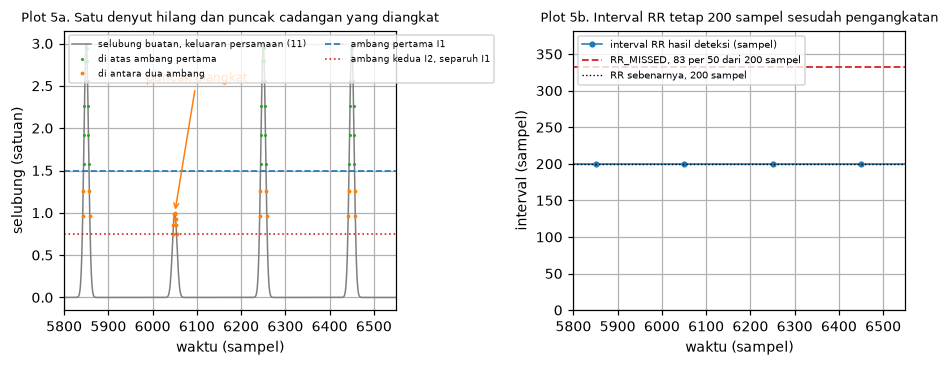

puncak diangkat pada deret satu denyut hilang: 1
  sampel puncak 6050, nilai 1.000, waktu pemeriksaan 6183 sampel, batas missed 332.0 sampel
  simpangan terbesar interval RR dari 200 sampel pada deret satu denyut hilang: 0.000 sampel
  jumlah pengangkatan pada deret dua denyut hilang: 2
  tunda pengangkatan kedua 133 sampel yaitu 532.0 ms
  kedalaman penampan terpakai pada deret buatan: satu denyut hilang 1, dua denyut hilang 1


In [20]:
# Tujuan: menggambar panel search back, yaitu selubung buatan, dua ambang, denyut hilang, puncak yang
# diangkat, dan penampan puncak kandidat yang terpakai.
# Cell ini menampilkan Plot 5 dengan dua panel dan mencetak posisi penanda pada gambar beserta
# pemakaian penampan.

t_env = np.arange(env_satu.size)
pos_puncak_kuat = env_satu > 1.5
pos_puncak_hilang = (env_satu > 0.75) & (env_satu <= 1.5)

fig5, axs5 = plt.subplots(1, 2, figsize=(8.4, 3.4))
axs5[0].plot(t_env, env_satu, "C7-", lw=1.0, label="selubung buatan, keluaran persamaan (11)")
axs5[0].plot(t_env[pos_puncak_kuat], env_satu[pos_puncak_kuat], "C2.", ms=2, label="di atas ambang pertama")
axs5[0].plot(t_env[pos_puncak_hilang], env_satu[pos_puncak_hilang], "C1.", ms=3, label="di antara dua ambang")
axs5[0].axhline(1.5, color="C0", ls="--", lw=1.1, label="ambang pertama I1")
axs5[0].axhline(0.75, color="C3", ls=":", lw=1.1, label="ambang kedua I2, separuh I1")
for p, v, i in angkat_satu:
    axs5[0].annotate("puncak diangkat", xy=(p, v), xytext=(p - 65.0, 2.55),
                     color="C1", fontsize=8, arrowprops=dict(arrowstyle="->", color="C1"))
axs5[0].set_xlim(5800.0, 6550.0)
axs5[0].set_title("Plot 5a. Satu denyut hilang dan puncak cadangan yang diangkat", fontsize=8.5)
axs5[0].set_xlabel("waktu (sampel)")
axs5[0].set_ylabel("selubung (satuan)")
axs5[0].legend(loc="upper left", fontsize=6.0, ncol=2)
t_det = det_satu
axs5[1].plot(t_det[:-1], np.diff(t_det), "C0o-", ms=3, lw=1.0, label="interval RR hasil deteksi (sampel)")
axs5[1].axhline(batas_missed_sampel, color="C3", ls="--", lw=1.2, label="RR_MISSED, 83 per 50 dari 200 sampel")
axs5[1].axhline(200.0, color="k", ls=":", lw=0.9, label="RR sebenarnya, 200 sampel")
axs5[1].set_xlim(5800.0, 6550.0)
axs5[1].set_ylim(0.0, batas_missed_sampel * 1.15)
axs5[1].set_title("Plot 5b. Interval RR tetap 200 sampel sesudah pengangkatan", fontsize=8.5)
axs5[1].set_xlabel("waktu (sampel)")
axs5[1].set_ylabel("interval (sampel)")
axs5[1].legend(loc="upper left", fontsize=6.5)
fig5.tight_layout()
plt.show()

print("puncak diangkat pada deret satu denyut hilang: %d" % len(angkat_satu))
for p, v, i in angkat_satu:
    print("  sampel puncak %d, nilai %.3f, waktu pemeriksaan %d sampel, batas missed %.1f sampel"
          % (p, v, i, batas_missed_sampel))
print("  simpangan terbesar interval RR dari 200 sampel pada deret satu denyut hilang: %.3f sampel"
      % float(np.max(np.abs(np.diff(t_det) - 200.0))))
print("  jumlah pengangkatan pada deret dua denyut hilang: %d" % len(angkat_dua))
print("  tunda pengangkatan kedua %d sampel yaitu %.1f ms"
      % (angkat_dua[1][2] - angkat_dua[1][0], (angkat_dua[1][2] - angkat_dua[1][0]) * MS_PER_SAMPEL))
print("  kedalaman penampan terpakai pada deret buatan: satu denyut hilang %d, dua denyut hilang %d"
      % (penampan_satu.pemakaian_terbesar, penampan_dua.pemakaian_terbesar))


## 9. Catatan fixed-point memakai konvensi terkunci

Konvensi yang sudah dikunci tim dipakai apa adanya: masukan plus minus 5 mV pada 12 bit signifikan
dijepit di plus minus 2047 dan digeser kiri 4 bit, low-pass 22 bit, high-pass 28 bit, turunan 23 bit
lalu digeser kanan 8 bit sehingga faktor skala ambangnya 256, jendela integrasi bergantian 37 dan 38
sampel dengan penampan melingkar, dan pembagian dengan 38 tidak dilakukan di RTL karena ambangnya yang
dikalikan 38. Tahap rata-rata RR di dokumen ini bekerja pada besaran waktu, dan satuan waktunya sudah
dikunci oleh keputusan P4-3, yaitu **sampel**, jadi lebar bitnya ditentukan oleh satuan itu.

Satu interval RR pada laju 250 Hz sekarang disimpan sebagai jumlah sampel. Sebagai milidetik, satu
interval selalu kelipatan empat, dan rentang yang perlu ditampung adalah dari sekitar 250 ms sampai
sekitar 2500 ms. Pada rekaman ini terukur satu interval sepanjang 1772 sampel yaitu 7088 ms, dan itu
bukan irama yang lambat melainkan akibat satu denyut yang tidak terdeteksi. Karena itu lebar RR dipakai
**14 bit penuh** dan tidak dijepit ke 13 bit. Dengan 14 bit, rentang yang tertampung adalah 8191 sampel
yaitu sekitar 32,8 detik, sehingga satu denyut yang tidak terdeteksi pun masih tertampung tanpa
penjepitan, dan berkas RR yang dijepit dapat menyesatkan aturan (24) karena nilai yang dijepit tidak
lagi menyatakan jarak denyut yang sebenarnya. Harga satuan sampel adalah galat geser kanan tiga bit
sebesar 3,5 ms pada penanda waktu, dan harga itu sudah diukur di bagian 3.

Tiga batas persamaan (26) sampai (28) paling murah diterapkan sebagai perkalian silang dengan pecahan
tepat, tanpa pembagian di jalur data dan tanpa pengali konstanta, karena ketiga pengalinya dapat ditulis
sebagai jumlah pangkat dua bertanda. Bentuk yang dipakai sebagai bawaan:

$$ RR \geq \frac{23}{25} RR_{AVERAGE2} \iff 25 \, RR \geq 23 \, RR_{AVERAGE2} $$

$$ RR \leq \frac{29}{25} RR_{AVERAGE2} \iff 25 \, RR \leq 29 \, RR_{AVERAGE2} $$

$$ RR > \frac{83}{50} RR_{AVERAGE2} \iff 50 \, RR > 83 \, RR_{AVERAGE2} $$


In [21]:
# Tujuan: mengukur lebar bit seluruh besaran waktu pada persamaan (24) sampai (28) bersatuan sampel,
# lebar RR yang dipakai penuh, dan biaya tiap bentuk batas.
# Cell ini mencetak lebar bit RR, jumlah delapan interval, dua rata-rata, hasil antara tiap bentuk silang,
# lebar rancangan untuk lebar RR penuh, dan biaya ungkapan tiap bentuk batas.

def lebar_bit(peak):
    """Lebar bit minimum termasuk bit tanda untuk menampung nilai mutlak terbesar."""
    n = int(np.floor(abs(peak)))
    return max(2, n.bit_length() + 1)


ok_bit = ~np.isnan(h_reg["avg2"])
rr_bit = rr_deret[ok_bit].astype(np.int64)
avg1_bit = h_reg["avg1"][ok_bit]
avg2_bit = h_reg["avg2"][ok_bit]
S8_bit = np.array([rr_deret[k - DELAPAN + 1: k + 1].sum()
                   for k in range(DELAPAN - 1, rr_deret.size)])[ok_bit[DELAPAN - 1:]].astype(np.int64)
print("lebar bit besaran waktu pada rekaman, satuan terkunci %s" % SATUAN_RR)
print("  RR maksimum            : %6d sampel yaitu %7.1f ms, lebar %2d bit"
      % (int(rr_bit.max()), float(rr_bit.max()) * MS_PER_SAMPEL, lebar_bit(rr_bit.max())))
print("  S8 jumlah delapan      : %6d sampel yaitu %7.1f ms, lebar %2d bit"
      % (int(S8_bit.max()), float(S8_bit.max()) * MS_PER_SAMPEL, lebar_bit(S8_bit.max())))
print("  S8 digeser kanan 3     : %6d sampel, lebar %2d bit" % (int((S8_bit >> 3).max()), lebar_bit((S8_bit >> 3).max())))
print("  RR_AVERAGE1            : %6.1f sampel, lebar %2d bit" % (float(np.nanmax(avg1_bit)), lebar_bit(np.nanmax(avg1_bit))))
print("  RR_AVERAGE2            : %6.1f sampel, lebar %2d bit" % (float(np.nanmax(avg2_bit)), lebar_bit(np.nanmax(avg2_bit))))
print("  lebar RR yang dipakai  : %2d bit penuh, yaitu %d sampel atau %.0f ms, jadi tidak dijepit ke 13 bit"
      % (LEBAR_RR_BIT, 2 ** (LEBAR_RR_BIT - 1) - 1, (2 ** (LEBAR_RR_BIT - 1) - 1) * MS_PER_SAMPEL))
print("  pembanding lebar 13 bit yang tidak dipakai : %d sampel atau %.0f ms"
      % (2 ** 12 - 1, (2 ** 12 - 1) * MS_PER_SAMPEL))
print("  rentang %d bit dibanding RR terpanjang terukur : %.2f kali lipat"
      % (LEBAR_RR_BIT, (2 ** (LEBAR_RR_BIT - 1) - 1) / float(rr_bit.max())))
print("  RR_AVERAGE2 dengan %d bit pecahan, jadi %d bit nilai ditambah %d bit pecahan = %d bit"
      % (LEBAR_AVG2_PECAH, lebar_bit(np.nanmax(avg2_bit)), LEBAR_AVG2_PECAH,
         lebar_bit(np.nanmax(avg2_bit)) + LEBAR_AVG2_PECAH))
print()
rr_rancangan = 2 ** (LEBAR_RR_BIT - 1) - 1
avg2_rancangan = rr_rancangan * DELAPAN
print("lebar hasil antara perkalian silang bentuk eksak pada lebar rancangan, RR %d bit dan AVERAGE2 %d bit nilai ditambah %d bit pecahan:"
      % (LEBAR_RR_BIT, LEBAR_RR_BIT, LEBAR_AVG2_PECAH))
for nama, pengali_rr, pengali_av in (("bawah silang, 25 RR dibanding 23 AVERAGE2", 25, 23),
                                     ("atas silang, 25 RR dibanding 29 AVERAGE2", 25, 29),
                                     ("missed silang, 50 RR dibanding 83 AVERAGE2", 50, 83)):
    hasil_rr = pengali_rr * rr_rancangan
    hasil_av = pengali_av * avg2_rancangan
    print("  %-42s hasil antara %8d dan %9d, lebar %2d bit"
          % (nama, hasil_rr, hasil_av, max(lebar_bit(hasil_rr), lebar_bit(hasil_av))))
lebar_jalur = max(lebar_bit(25 * rr_rancangan), lebar_bit(83 * avg2_rancangan))
print("  sehingga jalur data perkalian silang memerlukan %d bit termasuk bit tanda, dan akumulator %d bit menampungnya"
      % (lebar_jalur, lebar_jalur + 1))
print()
daftar_bentuk = [("bawah eksak 23/25", "(((rr << 4) + (rr << 3) + rr) >= ((av << 4) + (av << 3) - av))", "eksak dikunci"),
                 ("atas eksak 29/25", "(((rr << 4) + (rr << 3) + rr) <= ((av << 4) + (av << 3) + (av << 2) + av))", "eksak dikunci"),
                 ("missed eksak 83/50", "(((rr << 5) + (rr << 4) + (rr << 1)) > ((av << 6) + (av << 4) + (av << 1) + av))", "eksak dikunci"),
                 ("bawah cadangan 59/64", "((rr << 6) >= ((av << 6) - (av << 2) - av))", "cadangan 64"),
                 ("atas cadangan 74/64", "((rr << 6) <= ((av << 6) + (av << 3) + (av << 1)))", "cadangan 64"),
                 ("missed cadangan 106/64", "((rr << 6) > ((av << 6) + (av << 5) + (av << 3) + (av << 1)))", "cadangan 64"),
                 ("bawah dilarang 30/32", "((rr << 5) >= ((av << 5) - (av << 1)))", "dilarang 32"),
                 ("atas dilarang 37/32", "((rr << 5) <= ((av << 5) + (av << 2) + av))", "dilarang 32"),
                 ("missed dilarang 53/32", "((rr << 5) > ((av << 5) + (av << 4) + (av << 2) + av))", "dilarang 32")]
baris_biaya = []
for nama, rumus, kelompok in daftar_bentuk:
    biaya = biaya_bentuk(rumus)
    baris_biaya.append({"bentuk": nama, "kelompok": kelompok, "rumus silang": rumus, "geser": biaya["geser"],
                        "tambah": biaya["tambah"], "kurang": biaya["kurang"], "pengali konstanta": 0})
df_biaya = pd.DataFrame(baris_biaya)
print("biaya perhitungan tiap bentuk batas, dihitung dari ungkapannya sendiri:")
print(df_biaya[["bentuk", "kelompok", "geser", "tambah", "kurang", "pengali konstanta"]].to_string(index=False))
print()
print("jumlah biaya untuk ketiga batas sekaligus, pengali konstanta tidak dipakai sama sekali:")
for kelompok in ("eksak dikunci", "cadangan 64", "dilarang 32"):
    m = df_biaya["kelompok"] == kelompok
    print("  bentuk %-14s : geser %2d, penjumlahan %2d, pengurangan %2d, pengali konstanta %d"
          % (kelompok, int(df_biaya.loc[m, "geser"].sum()), int(df_biaya.loc[m, "tambah"].sum()),
             int(df_biaya.loc[m, "kurang"].sum()), int(df_biaya.loc[m, "pengali konstanta"].sum())))
mb = df_biaya[(df_biaya["bentuk"] == "bawah eksak 23/25")].iloc[0]
print("  batas bawah eksak 23/25 sendiri : geser %d, penjumlahan %d, pengurangan %d"
      % (int(mb["geser"]), int(mb["tambah"]), int(mb["kurang"])))
print()
print("penampan puncak kandidat masuk jalur waktu, bukan jalur amplitudo: kedalaman terkunci %d puncak," % KEDALAMAN_PENAMPAN)
print("dan lebar RR %d bit penuh menentukan lebar pembanding posisi puncak cadangan." % LEBAR_RR_BIT)
HASIL["lebar bit RR"] = lebar_bit(rr_bit.max())
HASIL["lebar bit S8"] = lebar_bit(S8_bit.max())
HASIL["lebar RR rancangan (bit)"] = int(LEBAR_RR_BIT)
HASIL["lebar jalur perkalian silang"] = int(lebar_jalur)
HASIL["biaya geser tiga batas eksak"] = int(df_biaya.loc[df_biaya["kelompok"] == "eksak dikunci", "geser"].sum())
HASIL["biaya tambah tiga batas eksak"] = int(df_biaya.loc[df_biaya["kelompok"] == "eksak dikunci", "tambah"].sum())


lebar bit besaran waktu pada rekaman, satuan terkunci sampel
  RR maksimum            :   1772 sampel yaitu  7088.0 ms, lebar 12 bit
  S8 jumlah delapan      :   3400 sampel yaitu 13600.0 ms, lebar 13 bit
  S8 digeser kanan 3     :    425 sampel, lebar 10 bit
  RR_AVERAGE1            :  425.0 sampel, lebar 10 bit
  RR_AVERAGE2            :  256.0 sampel, lebar 10 bit
  lebar RR yang dipakai  : 14 bit penuh, yaitu 8191 sampel atau 32764 ms, jadi tidak dijepit ke 13 bit
  pembanding lebar 13 bit yang tidak dipakai : 4095 sampel atau 16380 ms
  rentang 14 bit dibanding RR terpanjang terukur : 4.62 kali lipat
  RR_AVERAGE2 dengan 3 bit pecahan, jadi 10 bit nilai ditambah 3 bit pecahan = 13 bit

lebar hasil antara perkalian silang bentuk eksak pada lebar rancangan, RR 14 bit dan AVERAGE2 14 bit nilai ditambah 3 bit pecahan:
  bawah silang, 25 RR dibanding 23 AVERAGE2  hasil antara   204775 dan   1507144, lebar 22 bit
  atas silang, 25 RR dibanding 29 AVERAGE2   hasil antara   204775 dan   1

### 9.1 Panjang waktu penanda delapan interval

Panjang jendela rata-rata RR bukan jumlah sampel yang tetap, melainkan jumlah denyut yang tetap. Jadi
lamanya dalam detik bergantung pada laju denyut, dan itu menentukan kecepatan penanda irama menyesuaikan
diri. Tabel berikut menghitungnya sebagai delapan kali periode denyut, dalam detik, dalam sampel, dan
dalam milidetik sebagai pembanding.


In [22]:
# Tujuan: menghitung panjang jendela delapan interval RR pada beberapa laju denyut, dalam detik, sampel,
# dan milidetik, serta panjang jendela pada laju median rekaman.
# Cell ini mencetak tabel laju denyut beserta panjang jendela dan panjang jendela pada laju median.

laju_uji = np.array([40.0, 50.0, 60.0, 75.0, 90.0, 100.0, 120.0, 150.0, 180.0, 200.0])
periode_ms = 60000.0 / laju_uji
df_waktu = pd.DataFrame({"laju (bpm)": laju_uji, "RR (ms)": periode_ms,
                         "RR (sampel)": periode_ms / MS_PER_SAMPEL,
                         "jendela 8 interval (s)": 8.0 * periode_ms / 1000.0,
                         "jendela 8 interval (sampel)": 8.0 * periode_ms / MS_PER_SAMPEL})
print("panjang jendela delapan interval RR menurut laju denyut, satuan terkunci sampel")
print(df_waktu.to_string(index=False))
print()
laju_median = 60000.0 / float(np.median(rr_ms))
jendela_median_ms = 8.0 * 60000.0 / laju_median
print("laju median rekaman %.2f bpm, jendela delapan interval %.3f detik yaitu %.1f sampel atau %.1f ms"
      % (laju_median, jendela_median_ms / 1000.0, jendela_median_ms / MS_PER_SAMPEL, jendela_median_ms))
print("pada 200 bpm jendela hanya %.3f detik, jadi penanda dapat berubah keadaan hampir dua kali per detik"
      % (8.0 * 60.0 / 200.0))
print("pada 40 bpm jendela %.1f detik, jadi penanda baru dapat berubah setelah %.1f detik"
      % (8.0 * 60.0 / 40.0, 8.0 * 60.0 / 40.0))
print("kedalaman penampan puncak kandidat %d puncak setara %.1f detik pada refrakter %d sampel"
      % (KEDALAMAN_PENAMPAN, KEDALAMAN_PENAMPAN * REFR_SAMPEL * MS_PER_SAMPEL / 1000.0, REFR_SAMPEL))
HASIL["jendela 8 interval pada 75 bpm (s)"] = float(8.0 * 60.0 / 75.0)
HASIL["jendela 8 interval pada 180 bpm (s)"] = float(8.0 * 60.0 / 180.0)
HASIL["jendela 8 interval pada 75 bpm (sampel)"] = float(8.0 * 60000.0 / 75.0 / MS_PER_SAMPEL)


panjang jendela delapan interval RR menurut laju denyut, satuan terkunci sampel
 laju (bpm)     RR (ms)  RR (sampel)  jendela 8 interval (s)  jendela 8 interval (sampel)
       40.0 1500.000000   375.000000               12.000000                  3000.000000
       50.0 1200.000000   300.000000                9.600000                  2400.000000
       60.0 1000.000000   250.000000                8.000000                  2000.000000
       75.0  800.000000   200.000000                6.400000                  1600.000000
       90.0  666.666667   166.666667                5.333333                  1333.333333
      100.0  600.000000   150.000000                4.800000                  1200.000000
      120.0  500.000000   125.000000                4.000000                  1000.000000
      150.0  400.000000   100.000000                3.200000                   800.000000
      180.0  333.333333    83.333333                2.666667                   666.666667
      200.0  300.000

## 10. Ringkasan seluruh angka terukur


In [23]:
# Tujuan: mencetak seluruh angka terukur di notebook ini sebagai satu tabel ringkasan.
# Cell ini mencetak DataFrame ringkasan beserta jumlah besaran dan kesimpulan akhir notebook.

def fmt_besaran(v):
    """tampilkan bilangan bulat tanpa desimal dan pecahan dengan sepuluh angka penting"""
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return "%.10g" % float(v)


df_ringkas = pd.DataFrame([{"besaran": k, "nilai": fmt_besaran(v)} for k, v in HASIL.items()])
print("ringkasan angka terukur notebook rata-rata interval RR dan penanda irama")
print(df_ringkas.to_string(index=False))
print()
print("jumlah besaran ringkasan:", df_ringkas.shape[0])
print("seluruh angka di tabel ini dicetak oleh sel tempat angka itu dihitung, tanpa satu pun kutipan.")


ringkasan angka terukur notebook rata-rata interval RR dan penanda irama
                                                   besaran          nilai
                                           jumlah sel kode             23
                                        jumlah interval RR           2522
                                   denyut per menit median    81.52173913
                                    kesesuaian dua pemetik    0.936979786
                                         topeng mutu lolos   0.8996827914
                               kedalaman penampan terpakai             36
                                    RR terpanjang (sampel)           1772
                              galat maksimum geser kanan 3          0.875
                               galat geser sampel maksimum           0.75
                                   jumlah jendela RR diuji           5993
                                      beda AVG1 AVG2 semua   0.8862823062
                                  beda 

## 11. Antarmuka ke fase berikutnya, diskriminasi gelombang T

Aturan yang TIDAK dikerjakan di fase ini, dan hanya disebut sebagai antarmuka, ada di halaman 234 juga:
bila satu interval RR kurang dari 360 ms, yang tentu saja harus lebih panjang daripada latensi 200 ms,
maka diambil satu keputusan untuk menentukan apakah kompleks yang baru saja ditemukan itu benar-benar
kompleks QRS atau sesungguhnya gelombang T. Bila kemiringan terbesar di dalam bentuk gelombang itu
kurang dari separuh kemiringan kompleks QRS yang mendahuluinya, gelombang itu dinyatakan gelombang T,
dan bila tidak, ia disebut kompleks QRS. Antarmukanya dengan dokumen ini ada di dua tempat. Pertama,
aturan itu memakai besaran kemiringan terbesar, yaitu keluaran tahap turunan lima titik yang sudah
didokumentasikan di `five-point-derivative-equation.md`, bukan besaran waktu seperti tiga batas di sini.
Kedua, aturan itu hanya dapat berjalan setelah ada kompleks QRS sebelumnya yang sudah disahkan, jadi ia
memerlukan urutan denyut yang sudah ada, dan urutan itulah yang dikeluarkan pemetik puncak pada
dokumen ini. Karena itu fase ini berhenti tepat sebelum keputusan gelombang T, dan seluruh pemeriksaan
kemiringan, termasuk pemilihan besaran kemiringan yang dipakai, masuk fase berikutnya.


## 12. Hubungan ke rancangan AFIB-LITE dan keputusan yang sudah dikunci

Tiga akibat rancangan yang langsung terbaca dari pengukuran di notebook ini.

1. Persamaan (24) memang bebas pengali. Rata-rata delapan interval adalah satu penjumlah bergeser
   $S_8[n] = S_8[n-1] + RR_n - RR_{n-8}$ dan satu geser kanan tiga bit, sehingga yang dibutuhkan hanyalah
   penampan melingkar delapan kata. Karena satuan yang dikunci adalah sampel, galat geser kanannya
   adalah 0,875 sampel yaitu 3,5 ms, dan itu harga penanda waktu yang dibayar oleh keputusan P4-3.
2. Tiga batas persamaan (26) sampai (28) dipakai dalam bentuk eksak 23 per 25, 29 per 25, dan 83 per 50
   lewat perkalian silang, jadi tidak ada pembagi dan tidak ada pengali konstanta di jalur data. Batas
   bawah sendiri hanya memerlukan 4 geseran dan 3 penjumlahan ditambah 1 pengurangan. Aproksimasi
   berpenyebut 64 tetap dicatat sebagai cadangan, sedangkan aproksimasi berpenyebut 32 dilarang karena
   galat relatifnya 1,9022 persen dan pada lingkar tertutup bentuk 30 per 32 terukur meruntuhkan penanda
   irama teratur dari 898 penyalaan menjadi 9 penyalaan pada bacaan yang ditolak.
3. Penanda irama teratur tidak menyala satu kali pun pada tiga jendela beranotasi AFIB pada jalur mana pun,
   dan menyala pada 62,9 persen langkah pada jendela N terpanjang dengan topeng mutu. Namun pada jendela N
   pertama yang panjangnya 410,2 detik penanda itu dengan aturan P4-5 hanya menyala 7,9 persen, sehingga
   gerbang sederhana yang berbunyi tidak teratur sama dengan AFIB akan salah menandai jendela N itu.
   Karena itu penanda itu lebih tepat dipakai sebagai satu fitur tambahan, bukan sebagai gerbang tunggal.

Lima keputusan yang dikunci tim pada **19 Oktober 2026**, seluruhnya berpengaruh ke RTL dan ke kode host.

1. **P4-1, bacaan persamaan (25).** Rata-rata kedua dibaca sebagai rata-rata delapan interval lolos
   terakhir, jadi selalu delapan sampel. Bacaan lain, yaitu rata-rata interval yang lolos di antara
   delapan interval terakhir, ditolak karena terukur memakai paling sedikit satu sampel segar, tidak
   memakai sampel segar sama sekali pada 877 langkah, dan lalu membeku sampai 413 denyut atau 303,8
   detik pada rekaman ini. Bacaan yang ditolak hanya muncul sebagai pembanding singkat di bagian 4,
   6.1, dan 6.2, sedangkan seluruh perhitungan memakai bacaan terkunci.
2. **P4-2, konstanta batas bawah.** Batas bawah memakai bentuk eksak 23 per 25 dalam bentuk silang
   25 kali RR lebih besar atau sama dengan 23 kali RR_AVERAGE2. Biayanya terukur hanya 4 geseran dan
   3 penjumlahan ditambah 1 pengurangan, tanpa pengali konstanta. Aproksimasi 59 per 64 boleh muncul
   sebagai cadangan dengan galat relatif 0,2038 persen, sedangkan aproksimasi 30 per 32 dilarang karena
   galat relatifnya 1,9022 persen dan terukur meruntuhkan penanda dari 898 menjadi 9.
3. **P4-3, satuan waktu RR.** Satuan yang dipakai adalah sampel, bukan milidetik, dan galat 3,5 ms
   ditulis apa adanya sebagai konsekuensinya. Keuntungannya, penanda waktu dapat langsung diambil dari
   penghitung sampel yang sudah ada di rantai, dan seluruh interval RR menjadi bilangan bulat kecil.
4. **P4-4, prosedur search back.** Puncak cadangan disimpan di dalam penampan puncak kandidat, kedalaman
   penampan diukur pada rekaman uji dan dilaporkan di bagian 8.1, dan lebar RR dipakai 14 bit penuh tanpa
   dijepit ke 13 bit. Penampan itu menyimpan pasangan posisi dan nilai untuk tiap puncak cadangan, dan
   hanya operasi terbesar yang membacanya.
5. **P4-5, penyemaian ulang antrean rata-rata kedua.** Bila tidak ada satu pun interval RR yang lolos pita
   0,92 sampai 1,16 kali rata-rata kedua selama 8 denyut berturut-turut, antrean delapan interval diisi
   ulang memakai median 32 interval RR terakhir, lalu rata-rata kedua dihitung ulang dari antrean itu, dan
   penyemaian ulang dibatasi paling banyak sekali per 8 denyut. Pada rekaman uji aturan itu menaikkan
   penyalaan penanda irama teratur dari 902 menjadi 1238 penyalaan dan memendekkan jeda terdampar
   terpanjang dari 411 denyut yaitu 302,3 detik menjadi 19 denyut yaitu 12,1 detik, tanpa mengubah jumlah
   sampel RR_AVERAGE2 yang tetap delapan, dan tanpa menambah ambang baru karena pita pemicunya sama dengan
   batas persamaan (26) dan (27).

Yang masih terbuka untuk fase berikutnya: pemilihan besaran kemiringan untuk diskriminasi gelombang T,
penetapan ambang gerbang penanda irama teratur pada tingkat jendela di luar rekaman uji ini, karena sel
gerbang di bagian 7 hanya menurunkan ambang pada deret detektor sendiri dan ambang lama yang tidak boleh
dipindahkan tidak dipakai sama sekali, dan apakah penampan puncak kandidat dipakai dengan kedalaman
terkunci atau dengan kebijakan simpan puncak terbesar yang lebih murah.


## 13. Rujukan

1. Pan J, Tompkins WJ. *A Real-Time QRS Detection Algorithm.* IEEE Transactions on Biomedical
   Engineering, 1985, BME-32(3):230-236. DOI 10.1109/TBME.1985.325532. Persamaan (24) sampai (29),
   bagian `Adjusting the Average RR Interval and Rate Limits`, bagian `T-Wave Identification`, dan
   bagian `Evaluation` ada di halaman 234. Halaman itu dibaca langsung dari gambar halaman 600 dpi
   salinan PDF di `~/.hermes/cache/scratch/explore/pan-tompkins-1985.pdf`, halaman kelima dari tujuh,
   bukan dari lapisan teksnya karena OCR halaman itu rusak.
2. Salinan penuh naskah: https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf
3. Cermin cadangan: https://people.ece.cornell.edu/land/courses/ece5030/labs/s2014/Pan_Tompkins.pdf
4. Dokumen pendamping di vault: `low-pass-filter-equation.md`, `high-pass-filter-equation.md`,
   `five-point-derivative-equation.md`, `squaring-and-moving-window-integrator-equation.md`
5. Notebook pendamping: `nabdha-afib-lite/model/math-equation-afib/rr-interval-averaging-equations.ipynb`
6. Data uji: PhysioNet MIT-BIH Atrial Fibrillation Database, rekaman `04015`, 250 Hz, 450000 sampel
   pertama dari rekaman. https://physionet.org/content/afdb/
